# Lab Assignment 7 — Multiobjective Optimization: 37 Algorithms, Trade-offs and Applications
**Optimization Techniques Lab · Yash Deshmukh · Roll 241070018 (R = 18)**

Everything below is written from scratch in **Python + NumPy + Matplotlib only** (Section 2A). Run top to bottom.
Single notebook layout:
* **A1** `moo_utils` (dominance, Deb rules, sorting, crowding, HV, IGD, Spacing) + problems P1–P14 + unit tests
* **A2/A3** all 37 algorithms: docstring, unit test, fixed-seed runs, plots, HV / IGD / Spacing, implementation log
* **Problem studies** (the "Investigate" questions of P1–P14)
* **B** comparison table · **C** deep dive (algorithms **18 MOEA/D, 30 MOMA, 5 Value Function**) · **D** head-to-head · **E** selection · **F** viva

Conventions: every objective is **minimised** (Max f ≡ Min −f). Budget **10,000 evaluations**, seeds fixed (`seed=0` for single runs, seeds 0–9 for comparisons).
Set `QUICK = True` below to smoke-test the notebook in ~2 minutes with smaller budgets.

In [1]:
import numpy as np, time, math, itertools, warnings, sys
import matplotlib.pyplot as plt
try:
    from IPython.display import display, Markdown
except Exception:
    display = print
    Markdown = lambda s: s
warnings.filterwarnings("ignore")
plt.rcParams.update({'figure.dpi': 80, 'axes.grid': True, 'grid.alpha': .3, 'figure.max_open_warning': 0})

QUICK = False            # True = tiny budgets for a fast smoke test
BUDGET = 3000 if QUICK else 10000
NSEEDS = 3 if QUICK else 10
SEEDS = list(range(NSEEDS))

def md(s): display(Markdown(s))
def md_table(headers, rows, fmt="{:.4g}"):
    f = lambda v: fmt.format(v) if isinstance(v, (float, np.floating)) else str(v)
    s = "| " + " | ".join(headers) + " |\n|" + "---|" * len(headers) + "\n"
    for r in rows: s += "| " + " | ".join(f(v) for v in r) + " |\n"
    md(s)

## A1 · Shared toolkit `moo_utils`
Dominance test, Deb's constrained dominance (3 rules), fast non-dominated sorting, crowding distance, 2-D hypervolume (exact) / Monte-Carlo hypervolume (M ≥ 3), IGD, Spacing, normalisation, Das–Dennis reference points.

In [2]:
# ------------------------------ moo_utils ------------------------------
def dominates(a, b):
    """a dominates b (minimisation): a<=b everywhere and a<b somewhere."""
    return bool(np.all(a <= b) and np.any(a < b))

def cdominates(fa, cva, fb, cvb):
    """Deb's constrained domination. Rule 1: feasible beats infeasible. Rule 2: both infeasible -> smaller violation wins.
    Rule 3: both feasible -> ordinary dominance."""
    if cva <= 0 and cvb > 0: return True
    if cva > 0 and cvb <= 0: return False
    if cva > 0 and cvb > 0: return cva < cvb
    return dominates(fa, fb)

def dom_matrix(F, CV=None):
    """D[i,j] = True if i dominates j (Deb-constrained if CV is given)."""
    D = (F[:, None, :] <= F[None, :, :]).all(2) & (F[:, None, :] < F[None, :, :]).any(2)
    if CV is not None:
        fe = CV <= 0
        D = np.where(fe[:, None] & fe[None, :], D, False)
        D |= fe[:, None] & ~fe[None, :]
        D |= (~fe[:, None] & ~fe[None, :]) & (CV[:, None] < CV[None, :])
    return D

def nds(F, CV=None):
    """Fast non-dominated sorting (Deb): domination counts, peel fronts. Returns list of index arrays."""
    D = dom_matrix(F, CV); cnt = D.sum(0).astype(int); alive = np.ones(len(F), bool); fronts = []
    while alive.any():
        cur = np.where(alive & (cnt == 0))[0]
        fronts.append(cur); alive[cur] = False; cnt = cnt - D[cur].sum(0)
    return fronts

def crowding(F):
    """Crowding distance of one front (boundary points = inf)."""
    n, m = F.shape; d = np.zeros(n)
    if n <= 2: return np.full(n, np.inf)
    for j in range(m):
        o = np.argsort(F[:, j], kind='stable'); fj = F[o, j]; rg = fj[-1] - fj[0]
        d[o[0]] = d[o[-1]] = np.inf
        if rg > 0: d[o[1:-1]] += (fj[2:] - fj[:-2]) / rg
    return d

def pareto2d(F):
    """Non-dominated subset of a 2-objective set (O(n log n) sweep)."""
    o = np.lexsort((F[:, 1], F[:, 0])); Fs = F[o]
    prev = np.minimum.accumulate(np.r_[np.inf, Fs[:-1, 1]])
    return Fs[Fs[:, 1] < prev]

def hv2d(F, ref):
    """Exact 2-D hypervolume w.r.t. reference point ref (minimisation)."""
    P = F[(F < ref).all(1)]
    if len(P) == 0: return 0.0
    P = P[np.argsort(P[:, 0])]; hv = 0.0; best = ref[1]
    for f1, f2 in P:
        if f2 < best: hv += (ref[0] - f1) * (best - f2); best = f2
    return hv

_MC = {}
def hv_mc(F, ref, K=40000, seed=123):
    """Monte-Carlo hypervolume in the box [0,ref] (objectives already normalised to ~[0,1]); common random numbers."""
    M = F.shape[1]
    key = (M, K, seed)
    if key not in _MC: _MC[key] = np.random.default_rng(seed).random((K, M))
    S = _MC[key] * ref
    P = F[(F < ref).all(1)]
    if len(P) == 0: return 0.0
    hit = np.zeros(K, bool)
    for a in range(0, K, 10000): hit[a:a + 10000] = (P[None, :, :] <= S[a:a + 10000, None, :]).all(2).any(1)
    return hit.mean() * np.prod(ref)

def hypervolume(F, ref):
    F = np.asarray(F, float); ref = np.asarray(ref, float)
    return hv2d(F, ref) if F.shape[1] == 2 else hv_mc(F, ref)

def igd(Z, F):
    """Mean distance from each true-front point in Z to the nearest obtained point in F (smaller = better)."""
    if len(F) == 0: return np.inf
    return np.sqrt(((Z[:, None, :] - F[None, :, :]) ** 2).sum(2)).min(1).mean()

def spacing(F):
    """Standard deviation of nearest-neighbour distances along the obtained front (smaller = more even)."""
    if len(F) < 3: return np.nan
    D = np.sqrt(((F[:, None, :] - F[None, :, :]) ** 2).sum(2)); np.fill_diagonal(D, np.inf)
    return D.min(1).std()

def normalize(F, ideal, nadir): return (F - ideal) / np.maximum(nadir - ideal, 1e-12)

def das_dennis(M, p):
    """Das–Dennis simplex lattice: all weight vectors with components in {0,1/p,..,1} summing to 1."""
    def rec(M, p):
        if M == 1: return [[p]]
        return [[i] + r for i in range(p + 1) for r in rec(M - 1, p - i)]
    return np.array(rec(M, p), float) / p

def thin(Z, n=400):
    if len(Z) <= n: return Z
    o = np.lexsort(Z.T[::-1]); return Z[o[np.linspace(0, len(Z) - 1, n).astype(int)]]

### Unit tests of `moo_utils` on hand-checkable cases
*Car example*: six cars (price in $k, fuel use in L/100 km, both minimised). *Deb's table*: four candidate designs (two feasible, two infeasible).

In [3]:
cars = np.array([[20, 8], [25, 6], [30, 5], [22, 9], [28, 7], [35, 4.5]], float)   # A B C D E F
names = list("ABCDEF")
fr = nds(cars)
print("Car example, front 1:", [names[i] for i in fr[0]], "| front 2:", [names[i] for i in fr[1]])
assert sorted(fr[0]) == [0, 1, 2, 5] and sorted(fr[1]) == [3, 4]
assert abs(hv2d(cars, np.array([40., 10.])) - 82.5) < 1e-9                      # 40+30+10+2.5 by hand
assert np.isinf(crowding(cars[fr[0]])[[0, 3]]).all()
cd = crowding(cars[fr[0]][np.argsort(cars[fr[0], 0])])
# interior point B: (30-20)/15 + (8-5)/3.5 ; point C: (35-25)/15 + (6-4.5)/3.5
assert abs(cd[1] - ((30 - 20) / 15 + (8 - 5) / 3.5)) < 1e-9
# Deb's constrained-dominance table
deb = [("p1", (2, 3), 0.0), ("p2", (3, 4), 0.0), ("p3", (1, 1), 0.5), ("p4", (0.5, 0.5), 1.2)]
rows = []
for (na, fa, ca), (nb, fb, cb) in itertools.combinations(deb, 2):
    w = na if cdominates(np.array(fa), ca, np.array(fb), cb) else (nb if cdominates(np.array(fb), cb, np.array(fa), ca) else "none")
    rule = "1 (feasible > infeasible)" if (ca <= 0) != (cb <= 0) else ("2 (smaller violation)" if ca > 0 else "3 (dominance)")
    rows.append([na, nb, w, rule])
md_table(["a", "b", "winner", "Deb rule"], rows)
assert rows[0][2] == "p1" and rows[2][2] == "p1" and rows[5][2] == "p3"   # p3 (cv .5) beats p4 though p4 has better objectives
assert abs(igd(np.array([[0., 0.], [1., 1.]]), np.array([[0., 0.], [1., 0.]])) - 0.5) < 1e-12
assert abs(spacing(np.array([[0., 0.], [1., 0.], [2., 0.], [3., 0.]]))) < 1e-12
print("moo_utils unit tests: PASS")

Car example, front 1: ['A', 'B', 'C', 'F'] | front 2: ['D', 'E']


| a | b | winner | Deb rule |
|---|---|---|---|
| p1 | p2 | p1 | 3 (dominance) |
| p1 | p3 | p1 | 1 (feasible > infeasible) |
| p1 | p4 | p1 | 1 (feasible > infeasible) |
| p2 | p3 | p2 | 1 (feasible > infeasible) |
| p2 | p4 | p2 | 1 (feasible > infeasible) |
| p3 | p4 | p3 | 2 (smaller violation) |


moo_utils unit tests: PASS


## A1 · Problems P1–P14
Each problem returns objective values **F** (minimisation form) and a constraint violation **CV** (0 = feasible).
`prob.norm(F)` maps to ≈[0,1] with the problem's ideal/nadir; the HV reference point is **1.1** in normalised space for every problem.
Reference (true) fronts `prob.Z`: analytic for P1, P2, P3, P7, P10, P14; dense sampling + Pareto filter for P4, P5, P6 (labelled *reference*); P8/P9 have none (best-known union is used when needed).

In [4]:
class Problem:
    def __init__(s, name, M, n, lb, ub, fn, kind='real', ideal=None, nadir=None, Z=None, label=''):
        s.name, s.M, s.n, s.kind, s.fn, s.label = name, M, n, kind, fn, label
        s.lb, s.ub = np.broadcast_to(np.asarray(lb, float), (n,)).copy(), np.broadcast_to(np.asarray(ub, float), (n,)).copy()
        s.Z = Z
        if Z is not None and ideal is None: ideal, nadir = Z.min(0), Z.max(0)
        s.ideal, s.nadir = (None if ideal is None else np.asarray(ideal, float)), (None if nadir is None else np.asarray(nadir, float))
        s.ref = np.full(M, 1.1)
    def evaluate(s, X):
        X = np.atleast_2d(X); F, CV = s.fn(X); return np.asarray(F, float), np.asarray(CV, float)
    @property
    def rng_(s): return np.maximum(s.nadir - s.ideal, 1e-12)
    def norm(s, F): return (F - s.ideal) / s.rng_
    def pen(s, F, CV):
        """Static penalty used by algorithms WITHOUT feasibility rules: F + 10*CV*range."""
        return F + 10.0 * CV[:, None] * s.rng_[None, :]
    @property
    def Zn(s): return None if s.Z is None else s.norm(s.Z)
    def init(s, N, rng):
        if s.kind == 'real': return s.lb + rng.random((N, s.n)) * (s.ub - s.lb)
        if s.kind == 'perm': return np.array([rng.permutation(s.n) for _ in range(N)])
        return (rng.random((N, s.n)) < 0.5).astype(int)
    def decode(s, Xc, rng=None):
        """Continuous-position swarms: bits for binary problems, identity for real ones."""
        if s.kind == 'bin': return (rng.random(Xc.shape) < 1 / (1 + np.exp(-10 * (Xc - 0.5)))).astype(int)
        return Xc
    def __repr__(s): return s.name

def P1():
    f = lambda X: (np.c_[(X[:, 0] - 3) ** 2, (X[:, 0] - 7) ** 2], np.zeros(len(X)))
    x = np.linspace(3, 7, 400); Z = np.c_[(x - 3) ** 2, (x - 7) ** 2]
    return Problem('P1 factory speed', 2, 1, 1, 10, f, ideal=[0, 0], nadir=[16, 16], Z=Z)

def P2(integer=False):
    def f(X):
        x = np.round(X[:, 0]) if integer else X[:, 0]
        return np.c_[100 / x, x ** 2], np.zeros(len(X))
    x = np.arange(1, 11.) if integer else np.linspace(1, 10, 400)
    return Problem('P2 fleet' + (' (int)' if integer else ' (real)'), 2, 1, 1, 10, f, ideal=[10, 1], nadir=[100, 100], Z=np.c_[100 / x, x ** 2])

def P3(n=10):
    def f(X):
        g = 1 + X[:, 1:].sum(1); return np.c_[X[:, 0], g * (1 - (X[:, 0] / g) ** 2)], np.zeros(len(X))
    x = np.linspace(0, 1, 500)
    return Problem('P3 ZDT2', 2, n, 0, 1, f, ideal=[0, 0], nadir=[1, 1], Z=np.c_[x, 1 - x ** 2])

MU = np.array([.08, .12, .15, .10])
SIG = np.array([[.010, .002, .001, .003], [.002, .040, .006, .004], [.001, .006, .090, .005], [.003, .004, .005, .020]])
def P4(mode='repair'):
    def weights(X):
        if mode == 'repair':
            s = X.sum(1, keepdims=True); return np.where(s > 1e-12, X / np.maximum(s, 1e-12), 0.25), np.zeros(len(X))
        return X, np.maximum(0, np.abs(X.sum(1) - 1) - 1e-3)
    def f(X):
        W, cv = weights(X); return np.c_[np.einsum('ij,jk,ik->i', W, SIG, W), -W @ MU], cv
    r = np.random.default_rng(0); W = np.vstack([r.dirichlet(np.full(4, a), 250000) for a in (.15, .5, 1.)] + [np.eye(4)])
    F = np.c_[np.einsum('ij,jk,ik->i', W, SIG, W), -W @ MU]; Z = pareto2d(F)
    p = Problem('P4 portfolio (%s)' % mode, 2, 4, 0, 1, f, Z=thin(Z, 600)); p.weights = lambda X: weights(X)[0]; return p

def P5():
    L, Pl, E, rho = 1., 1000., 200e9, 7850.
    def f(X):
        b, h = X[:, 0], X[:, 1]
        return np.c_[rho * L * b * h, 4 * Pl * L ** 3 / (E * b * h ** 3)], np.maximum(0, 2.4e-5 - b * h ** 2) / 2.4e-5
    bb, hh = np.meshgrid(np.linspace(.01, .1, 1200), np.linspace(.02, .2, 1200)); X = np.c_[bb.ravel(), hh.ravel()]
    F, cv = f(X); Z = pareto2d(F[cv <= 0])
    p = Problem('P5 beam', 2, 2, [.01, .02], [.1, .2], f, Z=thin(Z, 600))
    # ideal/nadir of the *reference front*; deflection spans decades -> use log10 scaling for normalisation
    p.norm = lambda F, p=p: (np.log10(F) - np.log10(p.Z).min(0)) / np.maximum(np.log10(p.Z).max(0) - np.log10(p.Z).min(0), 1e-12)
    p.ideal, p.nadir = p.Z.min(0), p.Z.max(0)
    p.pen = lambda F, CV, p=p: F + 10.0 * CV[:, None] * p.rng_[None, :]
    return p

def P6():
    def f(X):
        x1, x2 = X[:, 0], X[:, 1]
        g1 = (x1 - 5) ** 2 + x2 ** 2 - 25; g2 = 7.7 - ((x1 - 8) ** 2 + (x2 + 3) ** 2)
        return np.c_[4 * x1 ** 2 + 4 * x2 ** 2, (x1 - 5) ** 2 + (x2 - 5) ** 2], np.maximum(0, g1) + np.maximum(0, g2)
    a, b = np.meshgrid(np.linspace(0, 5, 1500), np.linspace(0, 3, 900)); X = np.c_[a.ravel(), b.ravel()]
    F, cv = f(X); Z = pareto2d(F[cv <= 0])
    return Problem('P6 Binh-Korn', 2, 2, [0, 0], [5, 3], f, Z=thin(Z, 500))

def P7():
    def f(X): return np.c_[-0.8 * X[:, 0], -1.2 * X[:, 1]], np.maximum(0, X[:, 0] + X[:, 1] - 90)
    x1 = np.linspace(10, 70, 400); Z = np.c_[-0.8 * x1, -1.2 * (90 - x1)]
    return Problem('P7 water', 2, 2, [10, 20], [70, 80], f, ideal=[-56, -96], nadir=[-8, -24], Z=Z)

def P8():
    r = np.random.RandomState(7); C = r.uniform(0, 100, (15, 2))      # == numpy.random.seed(7); uniform(0,100,(15,2))
    Dm = np.sqrt(((C[:, None] - C[None]) ** 2).sum(2)); U = np.triu(r.uniform(.5, 2., (15, 15)), 1); U = U + U.T; Tm = Dm * U
    def f(X):
        nx = np.roll(X, -1, 1); return np.c_[Dm[X, nx].sum(1), Tm[X, nx].sum(1)], np.zeros(len(X))
    p = Problem('P8 TSP-15', 2, 15, 0, 14, f, kind='perm'); p.C, p.D, p.T = C, Dm, Tm
    # ideal / nadir from 2-opt tours of each single objective (fixed, used for normalisation only)
    def two_opt(Cm, seed):
        rg = np.random.default_rng(seed); t = rg.permutation(15); best = Cm[t, np.roll(t, -1)].sum(); imp = True
        while imp:
            imp = False
            for i in range(14):
                for j in range(i + 2, 15):
                    u = np.r_[t[:i + 1], t[i + 1:j + 1][::-1], t[j + 1:]]; c = Cm[u, np.roll(u, -1)].sum()
                    if c < best - 1e-12: t, best, imp = u, c, True
        return t, best
    td = min((two_opt(Dm, s) for s in range(30)), key=lambda z: z[1])[0]; tt = min((two_opt(Tm, s) for s in range(30)), key=lambda z: z[1])[0]
    Fd, Ft = f(td[None])[0][0], f(tt[None])[0][0]; p.tour_d, p.tour_t = td, tt
    p.ideal, p.nadir = np.array([Fd[0], Ft[1]]), np.array([Ft[0], Fd[1]]); return p

def P9():
    from sklearn.datasets import load_breast_cancer                    # raw data loading only
    d = load_breast_cancer(); X = (d.data - d.data.mean(0)) / d.data.std(0); y = d.target.astype(int); n = len(y)
    fold = np.random.default_rng(0).permutation(n) % 5
    D2 = ((X.T[:, :, None] - X.T[:, None, :]) ** 2).astype(np.float32).reshape(30, -1)       # per-feature squared differences
    same = (fold[:, None] == fold[None, :]) | np.eye(n, dtype=bool)
    def acc(mask):
        """5-fold CV accuracy of a hand-coded 5-NN classifier on the selected features."""
        D = (mask.astype(np.float32) @ D2).reshape(n, n); D[same] = np.inf
        nn = np.argpartition(D, 5, axis=1)[:, :5]; pred = (y[nn].sum(1) >= 3).astype(int); return (pred == y).mean()
    def f(M):
        F = np.zeros((len(M), 2)); cv = np.zeros(len(M))
        for i, m in enumerate(M):
            k = int(m.sum())
            if k == 0: F[i] = [.5, 0]; cv[i] = 1
            else: F[i] = [1 - acc(m), k]
        return F, cv
    p = Problem('P9 feature selection', 2, 30, 0, 1, f, kind='bin', ideal=[0, 1], nadir=[.4, 30]); p.acc = acc; p.feat = d.feature_names; return p

def P10(M=3):
    n = M + 9
    def f(X):
        g = ((X[:, M - 1:] - .5) ** 2).sum(1); c = np.cos(X[:, :M - 1] * np.pi / 2); s = np.sin(X[:, :M - 1] * np.pi / 2); F = np.zeros((len(X), M))
        for m in range(M):                     # f_{m+1}: cos product of first M-1-m vars times sin(x_{M-1-m})
            F[:, m] = (1 + g) * np.prod(c[:, :M - 1 - m], axis=1) * (s[:, M - 1 - m] if m > 0 else 1)
        return F, np.zeros(len(X))
    W = das_dennis(M, 12 if M == 3 else 6); Z = W / np.linalg.norm(W, axis=1, keepdims=True)
    return Problem('P10 DTLZ2 M=%d' % M, M, n, 0, 1, f, ideal=np.zeros(M), nadir=np.ones(M), Z=Z)

def P11():
    def f(X):
        a, b = X[:, 0], X[:, 1]
        return np.c_[-(4 * a + 6 * b), -(a + b)], np.maximum(0, 2 * a + 3 * b - 1200) / 1200 + np.maximum(0, 4 * a + 2 * b - 1600) / 1600
    return Problem('P11 production', 2, 2, 0, 400, f, ideal=[-2400, -500], nadir=[0, 0])

SUP = np.array([[120, 8, 10, 92], [100, 7, 14, 88], [140, 9, 7, 95], [90, 6, 18, 80], [130, 8, 9, 90]], float)

def P14():
    def f(X):
        x1, x2 = X[:, 0], X[:, 1]; return np.c_[.4 + .05 * x1 + .012 * x2, -0.2 * x2 / (.5 + .03 * x1)], np.zeros(len(X))
    x2 = np.linspace(40, 90, 400); Z = np.c_[.4 + .05 * 13 + .012 * x2, -0.2 * x2 / (.5 + .03 * 13)]
    return Problem('P14 laptop', 2, 2, [13, 40], [17, 90], f, Z=Z)

PROB = {k: v for k, v in dict(P1=P1(), P2=P2(), P3=P3(), P4=P4(), P5=P5(), P6=P6(), P7=P7(), P8=P8(), P9=P9(), P10_3=P10(3), P10_5=P10(5), P11=P11(), P14=P14()).items()}
PROB['P2i'] = P2(True)
print("Problems ready:", ", ".join(PROB))

Problems ready: P1, P2, P3, P4, P5, P6, P7, P8, P9, P10_3, P10_5, P11, P14, P2i


### Sanity checks from the problem bank (all verified by hand in the statement)

In [5]:
chk = lambda p, x: p.evaluate(np.array([x], float))
assert np.allclose(chk(PROB['P1'], [5])[0], [4, 4]) and np.allclose(chk(PROB['P1'], [3])[0], [0, 16])
assert np.allclose(chk(PROB['P2'], [2])[0], [50, 4]) and np.allclose(chk(PROB['P2'], [10])[0], [10, 100])
assert np.allclose(PROB['P3'].Z[:, 1], 1 - PROB['P3'].Z[:, 0] ** 2)
F, cv = chk(PROB['P4'], [0, 0, 1, 0]); assert np.allclose(F[0], [0.09, -0.15])
F, cv = chk(PROB['P5'], [.01, .05]); assert np.allclose(F[0], [3.925, 0.016]) and cv[0] == 0
F, cv = chk(PROB['P6'], [0, 0]); assert np.allclose(F[0], [0, 50]) and cv[0] == 0
F, cv = chk(PROB['P6'], [5, 3]); assert np.allclose(F[0], [136, 4]) and cv[0] == 0
assert np.allclose(chk(PROB['P7'], [10, 80])[0], [-8, -96]) and np.allclose(chk(PROB['P7'], [70, 20])[0], [-56, -24])
x = np.random.default_rng(1).random((5, 12)); F = PROB['P10_3'].evaluate(x)[0]; g = ((x[:, 2:] - .5) ** 2).sum(1)
x0 = x.copy(); x0[:, 2:] = .5; F0 = PROB['P10_3'].evaluate(x0)[0]; assert np.allclose((F0 ** 2).sum(1), 1)
assert np.allclose(chk(PROB['P14'], [13, 40])[0], [1.53, -8.989], atol=2e-3) and np.allclose(chk(PROB['P14'], [13, 90])[0], [2.13, -20.2247], atol=2e-3)
F, cv = chk(PROB['P11'], [300, 200]); assert np.allclose(F[0], [-2400, -500]) and cv[0] == 0
print("P1–P14 sanity checks: PASS | P8 coordinates (seed 7):\n", np.round(PROB['P8'].C, 2).tolist())
print("P8 shortest-distance tour objs:", np.round(PROB['P8'].evaluate(PROB['P8'].tour_d[None])[0][0], 1), "| shortest-time tour objs:", np.round(PROB['P8'].evaluate(PROB['P8'].tour_t[None])[0][0], 1))

P1–P14 sanity checks: PASS | P8 coordinates (seed 7):
 [[7.63, 77.99], [43.84, 72.35], [97.8, 53.85], [50.11, 7.21], [26.84, 49.99], [67.92, 80.37], [38.09, 6.59], [28.81, 90.96], [21.34, 45.21], [93.12, 2.49], [60.05, 95.01], [23.03, 54.85], [90.91, 13.32], [52.34, 75.04], [66.9, 46.78]]
P8 shortest-distance tour objs: [351.8 463.7] | shortest-time tour objs: [411.4 366.3]


## A2 · Shared run / plot / log helpers

In [6]:
FRONTS, XFR, STUDY = {}, {}, {}   # obtained fronts / decision vectors / numbers measured in the problem studies (used as evidence in Task B)
RES = {}     # (alg_no, problem key) -> metrics dict, filled by every run; used for the implementation log (A3) and Task B evidence

def score(prob, F):
    if len(F) == 0: return dict(hv=0., igd=np.inf, sp=np.nan, n=0)
    Fn = prob.norm(F); Zn = prob.Zn
    return dict(hv=hypervolume(Fn, prob.ref), igd=(igd(Zn, Fn) if Zn is not None else np.nan), sp=spacing(Fn), n=len(F))

def draw(ax, prob, F, title, color='C3'):
    if prob.M == 2:
        if prob.Z is not None:
            Z = prob.Z[np.argsort(prob.Z[:, 0])]; ax.plot(Z[:, 0], Z[:, 1], '-', c='0.6', lw=3, alpha=.6, label='true/ref front', zorder=1)
        if len(F): ax.scatter(F[:, 0], F[:, 1], s=14, c=color, zorder=2, label='obtained (%d)' % len(F))
        ax.set_xlabel('f1'); ax.set_ylabel('f2'); ax.legend(fontsize=7)
    elif prob.M == 3:
        if len(F): ax.scatter(F[:, 0], F[:, 1], F[:, 2], s=8, c=color)
        ax.set_xlabel('f1'); ax.set_ylabel('f2'); ax.set_zlabel('f3')
    else:
        idx = np.random.default_rng(0).choice(len(F), min(40, len(F)), replace=False) if len(F) else []
        for i in idx: ax.plot(range(1, prob.M + 1), F[i], c='C0', alpha=.35)
        ax.set_xlabel('objective'); ax.set_ylabel('value')
    ax.set_title(title, fontsize=9)

def show(entries, suptitle=None):
    """entries: list of (title, prob, F). One row of subplots."""
    k = len(entries); fig = plt.figure(figsize=(4.6 * k, 3.6))
    for i, (t, p, F) in enumerate(entries):
        ax = fig.add_subplot(1, k, i + 1, projection='3d' if p.M == 3 else None); draw(ax, p, F, t)
    if suptitle: fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout(); plt.show()

def log(no, key, prob, F, t, nfe, status='works'):
    s = score(prob, F); s.update(time=t, nfe=nfe, status=status); RES[(no, key)] = s; return s

def line(no, name, key, s): print(f"[{no:>2}] {name:<14} {key:<7} n={s['n']:<4} HV={s['hv']:.4f}  IGD={s['igd']:.4f}  Spacing={s['sp']:.4f}  nfe={s['nfe']}  t={s['time']:.1f}s")


def pmap(fn, arglist, procs=2, timeout=3600):
    """Run fn(*args) for every args in arglist on `procs` forked worker processes (falls back to a serial loop). Results come back in order."""
    arglist = list(arglist)
    if QUICK or procs <= 1 or len(arglist) < 2 or not hasattr(__import__('os'), 'fork'): return [fn(*a) for a in arglist]
    try:
        import multiprocessing as mp; ctx = mp.get_context('fork'); q = ctx.Queue()
        def work(ids):
            for i in ids:
                try: q.put((i, fn(*arglist[i])))
                except Exception as e: q.put((i, e))
        ps = [ctx.Process(target=work, args=(list(range(k, len(arglist), procs)),)) for k in range(procs)]; [p.start() for p in ps]
        out = [None] * len(arglist)
        for _ in arglist: i, r = q.get(timeout=timeout); out[i] = r
        [p.join() for p in ps]
        if any(isinstance(r, Exception) for r in out): raise RuntimeError('worker failed')
        return out
    except Exception: return [fn(*a) for a in arglist]

## A2 · Classical methods (algorithms 1–9)
**Sub-problem solver.** Section 2A allows `scipy.optimize` for the single-objective sub-problem; to stay dependency-free this notebook uses its own constrained differential evolution (Deb feasibility rule) + pattern-search polish, `solve_so`.
The scalarisation, sweeps over weights / ε / targets, deviation variables and priority logic are all coded below.

In [7]:
class Counter: n = 0

def solve_so(fvec, lb, ub, seed=0, pop=40, gens=200, x0=None):
    """Minimise a scalar function (vectorised over rows) with constraint violation. fvec(X)->(values, cv).
    DE/rand/1/bin with feasibility rule, followed by shrinking pattern search."""
    rng = np.random.default_rng(seed); lb = np.asarray(lb, float); ub = np.asarray(ub, float); n = len(lb)
    better = lambda fu, cu, fv, cv: np.where((cu <= 1e-9) & (cv <= 1e-9), fu < fv, cu < cv)
    X = lb + rng.random((pop, n)) * (ub - lb)
    if x0 is not None: X[0] = x0
    fv, cv = fvec(X)
    for g in range(gens):
        r = rng.integers(0, pop, (pop, 3)); Fm = rng.uniform(.4, .9, (pop, 1)); V = X[r[:, 0]] + Fm * (X[r[:, 1]] - X[r[:, 2]])
        m = rng.random((pop, n)) < .9; m[np.arange(pop), rng.integers(0, n, pop)] = True
        U = np.clip(np.where(m, V, X), lb, ub); fu, cu = fvec(U); b = better(fu, cu, fv, cv)
        X[b], fv[b], cv[b] = U[b], fu[b], cu[b]
    i = 0
    for k in range(1, pop):
        if better(fv[k:k + 1], cv[k:k + 1], fv[i:i + 1], cv[i:i + 1])[0]: i = k
    x, f, c = X[i].copy(), fv[i], cv[i]; step = 0.05 * (ub - lb)
    dirs = np.vstack([np.eye(n), -np.eye(n), rng.normal(size=(2 * n, n))])
    for it in range(300):
        C = np.clip(x + step[None, :] * dirs, lb, ub); fc, cc = fvec(C)
        j = 0
        for k in range(1, len(C)):
            if better(fc[k:k + 1], cc[k:k + 1], fc[j:j + 1], cc[j:j + 1])[0]: j = k
        if better(fc[j:j + 1], cc[j:j + 1], np.array([f]), np.array([c]))[0]: x, f, c = C[j].copy(), fc[j], cc[j]
        else:
            step = step * 0.5
            if step.max() < 1e-12: break
    return x, f, c

def vecF(prob):
    """Normalised objective matrix + cv for a batch of decision vectors (counts evaluations)."""
    def g(X):
        F, cv = prob.evaluate(X); Counter.n += len(X); return prob.norm(F), cv
    return g

def sweep_solve(prob, scal, extra_cv=None, seeds=0, x0=None, **kw):
    g = vecF(prob)
    def fvec(X):
        Fn, cv = g(X); v = scal(Fn)
        if extra_cv is not None: cv = cv + extra_cv(Fn)
        return v, cv
    return solve_so(fvec, prob.lb, prob.ub, seed=seeds, x0=x0, **kw)

def front_from(prob, xs):
    X = np.array(xs); F, cv = prob.evaluate(X); ok = cv <= 1e-9; X, F = X[ok], F[ok]
    nd = nds(F)[0]; X, F = X[nd], F[nd]; _, u = np.unique(np.round(F, 6), axis=0, return_index=True); return X[u], F[u]   # distinct points only

# ---- 1 Weighted Sum
def weighted_sum(prob, n_w=21, seed=0):
    """Alg 1 Weighted Sum. Steps: (1) normalise objectives; (2) for each weight w in [0,1] minimise w*f1+(1-w)*f2; (3) collect solutions; (4) keep non-dominated."""
    xs = [sweep_solve(prob, lambda Fn, w=w: w * Fn[:, 0] + (1 - w) * Fn[:, 1], seeds=seed)[0] for w in np.linspace(0, 1, n_w)]
    return front_from(prob, xs)
# ---- 2 epsilon-constraint
def eps_constraint(prob, n_e=21, seed=0, free=0):
    """Alg 2 ε-constraint. Steps: (1) keep objective `free` as the objective; (2) bound the other by ε (swept between ideal and nadir); (3) solve; (4) keep non-dominated."""
    other = 1 - free; xs = []
    for e in np.linspace(0, 1, n_e):
        xs.append(sweep_solve(prob, lambda Fn: Fn[:, free], extra_cv=lambda Fn, e=e: np.maximum(0, Fn[:, other] - e), seeds=seed)[0])
    return front_from(prob, xs)
# ---- 3 Benson
def benson(prob, n_s=12, seed=0, w=(.5, .5)):
    """Alg 3 Benson. Steps: (1) pick a feasible start x0 (reference point F(x0)); (2) maximise sum_i w_i*l_i with l_i = F_i(x0)-F_i(x) >= 0; (3) result is a Pareto point that dominates x0; (4) repeat for several x0."""
    rng = np.random.default_rng(seed); xs = []; w = np.asarray(w)
    for k in range(n_s):
        for _ in range(200):
            x0 = prob.lb + rng.random(prob.n) * (prob.ub - prob.lb)
            if prob.evaluate(x0[None])[1][0] <= 0: break
        f0 = prob.norm(prob.evaluate(x0[None])[0])[0]
        xs.append(sweep_solve(prob, lambda Fn: -(w * (f0 - Fn)).sum(1), extra_cv=lambda Fn: np.maximum(0, Fn - f0).sum(1), seeds=seed + k, x0=x0)[0])
    return front_from(prob, xs)
# ---- 4 weight metric
def weight_metric(prob, p=2, n_w=21, seed=0):
    """Alg 4 Weight metric. Steps: (1) ideal point z*=0 (normalised); (2) minimise (sum (w_i f_i)^p)^(1/p) (p=1,2) or max_i w_i f_i (p=inf, Tchebycheff); (3) sweep w; (4) keep non-dominated."""
    def sc(Fn, w, p=p): return np.max(w * Fn, 1) if np.isinf(p) else ((w * Fn) ** p).sum(1) ** (1 / p)
    xs = [sweep_solve(prob, lambda Fn, w=np.array([a, 1 - a]): sc(Fn, w), seeds=seed)[0] for a in np.linspace(0.02, .98, n_w)]
    return front_from(prob, xs)
# ---- 5 value function
def value_function(prob, U, seed=0, **kw):
    """Alg 5 Value function. Steps: (1) DM supplies a utility U(f_normalised) to maximise; (2) minimise -U subject to constraints; (3) report the single preferred Pareto solution."""
    x, f, c = sweep_solve(prob, lambda Fn: -U(Fn), seeds=seed, **kw); F = prob.evaluate(x[None])[0][0]; return x, F, -f
def cobb_douglas(a): return lambda Fn: np.clip(1 - Fn[:, 0], 1e-9, None) ** a * np.clip(1 - Fn[:, 1], 1e-9, None) ** (1 - a)
# ---- 6 goal programming
def goal_programming(prob, goals, wts, types, sign=-1, seed=0):
    """Alg 6 Goal programming. Steps: (1) goals g_i in natural units; (2) deviation variables d+_i=max(0,f_i-g_i), d-_i=max(0,g_i-f_i) (so f_i + d-_i - d+_i = g_i);
    (3) minimise sum w_i*(d- for '>=' goals, d+ for '<=' goals) subject to the original constraints."""
    goals = np.asarray(goals, float); wts = np.asarray(wts, float); g = vecF(prob)
    def dev(F): nat = sign * F; return np.maximum(0, nat - goals), np.maximum(0, goals - nat)
    def fvec(X):
        F, cv = prob.evaluate(X); Counter.n += len(X); dp, dm = dev(F)
        return (wts * np.where(np.array(types) == '>=', dm, dp)).sum(1), cv
    x, f, c = solve_so(fvec, prob.lb, prob.ub, seed=seed); F = prob.evaluate(x[None])[0]; dp, dm = dev(F)
    return x, sign * F[0], dp[0], dm[0], f
# ---- 7 lexicographic
def lexicographic(prob, order, tol=5e-3, seed=0):
    """Alg 7 Lexicographic. Steps: for k in priority order: (1) minimise f_k subject to f_j <= f_j* + tol for every higher-priority j; (2) record f_k*; (3) continue with next priority."""
    best = {}
    for k in order:
        def fvec(X, k=k):
            F, cv = prob.evaluate(X); Counter.n += len(X)
            c = cv + sum(np.maximum(0, F[:, j] - best[j] - tol * max(1, abs(best[j]))) for j in best)
            return F[:, k], c
        x, f, c = solve_so(fvec, prob.lb, prob.ub, seed=seed); best[k] = f
    return x, prob.evaluate(x[None])[0][0], best
# ---- 8 TOPSIS, 9 VIKOR
def topsis(D, w, benefit):
    """Alg 8 TOPSIS. Steps: vector-normalise, weight, ideal/anti-ideal, Euclidean distances, closeness C = d-/(d+ + d-)."""
    D = np.asarray(D, float); V = D / np.sqrt((D ** 2).sum(0)) * w; benefit = np.asarray(benefit, bool)
    ideal, anti = np.where(benefit, V.max(0), V.min(0)), np.where(benefit, V.min(0), V.max(0))
    dp, dm = np.sqrt(((V - ideal) ** 2).sum(1)), np.sqrt(((V - anti) ** 2).sum(1)); C = dm / (dp + dm); return C, np.argsort(-C)
def vikor(D, w, benefit, v=.5):
    """Alg 9 VIKOR. Steps: f*,f- per criterion; S_i=sum w_j (f*_j-f_ij)/(f*_j-f-_j); R_i=max_j(...); Q_i=v(S-S*)/(S--S*)+(1-v)(R-R*)/(R--R*); rank by Q (small=best); check C1 (advantage) and C2 (stability)."""
    D = np.asarray(D, float); benefit = np.asarray(benefit, bool)
    fb, fw = np.where(benefit, D.max(0), D.min(0)), np.where(benefit, D.min(0), D.max(0))
    T = w * (fb - D) / np.where(fb == fw, 1, fb - fw); S, R = T.sum(1), T.max(1)
    Q = v * (S - S.min()) / max(S.max() - S.min(), 1e-12) + (1 - v) * (R - R.min()) / max(R.max() - R.min(), 1e-12)
    o = np.argsort(Q); J = len(Q); c1 = (Q[o[1]] - Q[o[0]]) >= 1 / (J - 1); c2 = (o[0] == np.argmin(S)) or (o[0] == np.argmin(R))
    return dict(S=S, R=R, Q=Q, order=o, C1=bool(c1), C2=bool(c2))

### Unit tests (algorithms 1–9): each checks the key rule of the method

In [8]:
p1 = PROB['P1']; p11 = PROB['P11']; p7 = PROB['P7']
T = {}
x, F, _ = value_function(p1, cobb_douglas(.5)); T[5] = abs(x[0] - 5) < 1e-2                                   # symmetric utility -> mid point (4,4)
X1, F1 = weighted_sum(p1, 5); T[1] = abs(F1[np.argmin(np.abs(F1[:, 0] - F1[:, 1]))].mean() - 4) < .5 and F1[:, 0].min() < 1e-6   # w=.5 -> x=5, w=1 -> x=3
X2, F2 = eps_constraint(p1, 5); T[2] = np.isclose(F2[np.argmin(np.abs(F2[:, 1] - 4))][0], 4, atol=.05) and F2[:, 1].max() <= 16 + 1e-6   # f2<=4 (eps=.25 normalised) -> min f1 = 4
f0 = p1.norm(p1.evaluate(np.array([[2.]]))[0])[0]; Fb = p1.evaluate(sweep_solve(p1, lambda Fn: -(.5 * (f0 - Fn)).sum(1), extra_cv=lambda Fn: np.maximum(0, Fn - f0).sum(1), x0=np.array([2.]))[0][None])[0][0]
F0 = p1.evaluate(np.array([[2.]]))[0][0]; T[3] = bool(np.all(Fb <= F0 + 1e-6) and np.any(Fb < F0 - 1e-3)) and 3 - 1e-3 <= np.sqrt(Fb[0]) + 3 <= 7 + 1e-3        # Benson result dominates its start and is Pareto (x in [3,7])
Fw = [p1.evaluate(weight_metric(p1, pp, 3)[0])[0] for pp in (1, 2, np.inf)]; T[4] = all(len(f) >= 1 for f in Fw)
Tt = topsis(np.array([[1, 1], [2, 2], [3, 3.]]), np.array([.5, .5]), [True, True]); T[8] = list(Tt[1]) == [2, 1, 0]
Vv = vikor(np.array([[1, 1], [2, 2], [3, 3.]]), np.array([.5, .5]), [True, True]); T[9] = list(Vv['order']) == [2, 1, 0] and Vv['Q'][2] == 0
xg, nat, dp, dm, _ = goal_programming(p11, [2400, 600], [1, 1], ['>=', '>=']); T[6] = abs(dm[1] - 100) < .5 and abs(dm[0]) < .5
xl, Fl, bl = lexicographic(p11, [0, 1]); T[7] = np.allclose(xl, [300, 200], atol=1.0)
print({k: ('PASS' if v else 'FAIL') for k, v in sorted(T.items())}); assert all(T.values())
UNIT = {k: v for k, v in T.items()}

{1: 'PASS', 2: 'PASS', 3: 'PASS', 4: 'PASS', 5: 'PASS', 6: 'PASS', 7: 'PASS', 8: 'PASS', 9: 'PASS'}


### Alg 1 — Weighted Sum · Alg 2 — ε-constraint (runs on their test problems, seed 0)

[ 1] Weighted Sum   P1      n=21   HV=1.0258  IGD=0.0202  Spacing=0.0089  nfe=172116  t=0.6s


[ 1] Weighted Sum   P3      n=2    HV=0.2100  IGD=0.3543  Spacing=nan  nfe=200000  t=0.8s


[ 1] Weighted Sum   P4      n=17   HV=0.9395  IGD=0.0344  Spacing=0.0625  nfe=180968  t=0.7s


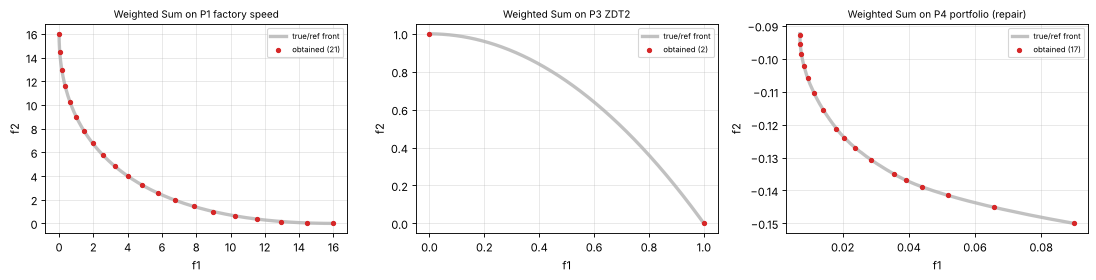

[ 2] ε-constraint   P2      n=21   HV=1.0865  IGD=0.0372  Spacing=0.1291  nfe=172148  t=0.5s


[ 2] ε-constraint   P3      n=21   HV=0.5192  IGD=0.0253  Spacing=0.0343  nfe=217200  t=0.9s


[ 2] ε-constraint   P5      n=21   HV=0.8188  IGD=0.0212  Spacing=0.0203  nfe=174592  t=1.1s


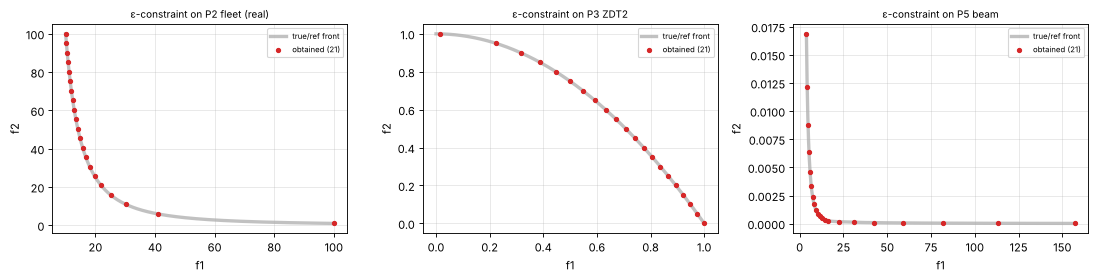

In [9]:
def run_classical(no, name, fn, keys, label=None):
    ents = []
    for k in keys:
        Counter.n = 0; t = time.time(); X, F = fn(PROB[k]); dt = time.time() - t
        s = log(no, k, PROB[k], F, dt, Counter.n); FRONTS[(no, k)] = F; XFR[(no, k)] = X; line(no, name, k, s); ents.append((f"{name} on {PROB[k].name}", PROB[k], F))
    show(ents)
run_classical(1, 'Weighted Sum', weighted_sum, ['P1', 'P3', 'P4'])
run_classical(2, 'ε-constraint', eps_constraint, ['P2', 'P3', 'P5'])

### Alg 3 — Benson · Alg 4 — Weight metric (p = 1, 2, ∞)

[ 3] Benson         P1      n=11   HV=0.9703  IGD=0.0730  Spacing=0.1305  nfe=98352  t=0.3s


[ 3] Benson         P7      n=12   HV=0.6056  IGD=0.0759  Spacing=0.0375  nfe=100512  t=0.3s


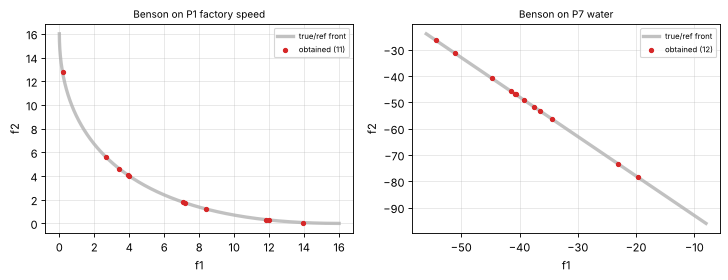

[ 4] Wmetric p=1    P1_p1   n=21   HV=1.0265  IGD=0.0194  Spacing=0.0080  nfe=172116  t=0.6s


[ 4] Wmetric p=1    P3_p1   n=2    HV=0.2100  IGD=0.3543  Spacing=nan  nfe=200360  t=0.9s


[ 4] Wmetric p=2    P1_p2   n=21   HV=1.0268  IGD=0.0261  Spacing=0.0287  nfe=172116  t=0.6s


[ 4] Wmetric p=2    P3_p2   n=13   HV=0.4616  IGD=0.0998  Spacing=0.1593  nfe=203000  t=0.9s


[ 4] Wmetric p=inf  P1_pinf n=21   HV=1.0217  IGD=0.0433  Spacing=0.0335  nfe=172116  t=0.6s


[ 4] Wmetric p=inf  P3_pinf n=21   HV=0.5168  IGD=0.0180  Spacing=0.0108  nfe=218080  t=0.9s


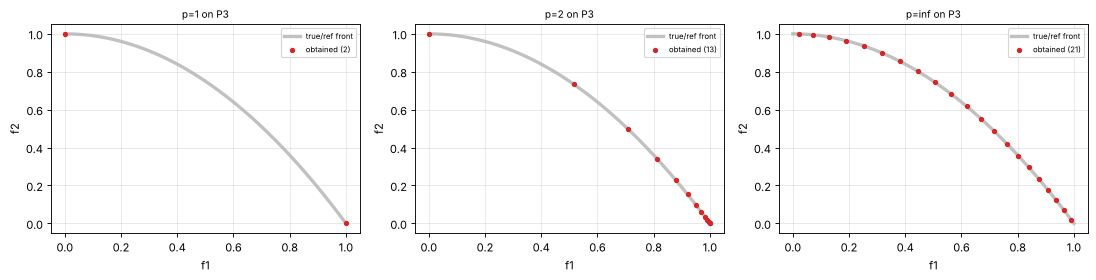

In [10]:
run_classical(3, 'Benson', benson, ['P1', 'P7'])
ents = []
for pp in (1, 2, np.inf):
    for k in ('P1', 'P3'):
        Counter.n = 0; t = time.time(); X, F = weight_metric(PROB[k], pp); dt = time.time() - t; kk = k + ('_p%s' % ('inf' if np.isinf(pp) else int(pp)))
        s = log(4, kk, PROB[k], F, dt, Counter.n); FRONTS[(4, kk)] = F; line(4, f"Wmetric p={pp}", kk, s)
        if k == 'P3': ents.append((f"p={pp} on P3", PROB[k], F))
show(ents)
RES[(4, 'P1')] = RES[(4, 'P1_p2')]; RES[(4, 'P3')] = RES[(4, 'P3_pinf')]

### Alg 5 — Value function (P4 portfolio and P14 laptop) · Alg 6 — Goal programming · Alg 7 — Lexicographic

| investor | weight a on risk | weights w | risk | return | utility |
|---|---|---|---|---|---|
| conservative | 0.8 | [0.061, 0.34, 0.26, 0.338] | 0.01616 | 0.1186 | 0.7783 |
| balanced | 0.5 | [0.0, 0.452, 0.454, 0.094] | 0.03012 | 0.1317 | 0.7021 |
| aggressive | 0.2 | [0.0, 0.298, 0.702, 0.0] | 0.05041 | 0.1411 | 0.7536 |


P14 value-function solution: screen 14.53 in, battery 56.1 Wh -> 1.800 kg, 12.00 h


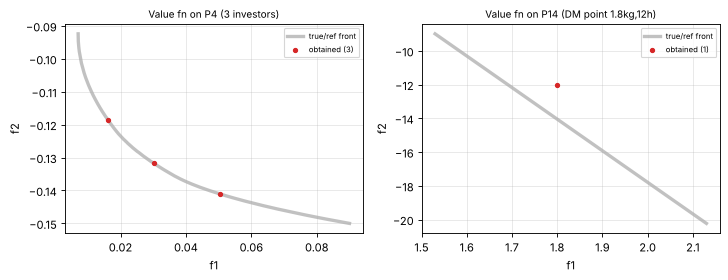

In [11]:
# P4: DM utility = Cobb-Douglas of normalised risk and return, weight a on risk (conservative a=.8, balanced .5, aggressive .2)
rows = []; fr4 = []
for a, lab in ((.8, 'conservative'), (.5, 'balanced'), (.2, 'aggressive')):
    Counter.n = 0; x, F, u = value_function(PROB['P4'], cobb_douglas(a)); w = PROB['P4'].weights(x[None])[0]; fr4.append(F)
    rows.append([lab, a, np.round(w, 3).tolist(), F[0], -F[1], u])
md_table(["investor", "weight a on risk", "weights w", "risk", "return", "utility"], rows)
# P14: DM wants ~1.8 kg and 12 h -> utility = -(normalised squared distance to the DM point)
dm_pt = np.array([1.8, -12.]); Upref = lambda Fn: -(((Fn - PROB['P14'].norm(dm_pt[None])[0]) ** 2).sum(1))
Counter.n = 0; x14, F14, u14 = value_function(PROB['P14'], Upref); print("P14 value-function solution: screen %.2f in, battery %.1f Wh -> %.3f kg, %.2f h" % (x14[0], x14[1], F14[0], -F14[1]))
s = log(5, 'P4', PROB['P4'], np.array(fr4), 0, Counter.n); s5 = log(5, 'P14', PROB['P14'], F14[None], 0, Counter.n)
show([("Value fn on P4 (3 investors)", PROB['P4'], np.array(fr4)), ("Value fn on P14 (DM point 1.8kg,12h)", PROB['P14'], F14[None])])

In [12]:
# Goal programming and Lexicographic on P11 (profit, units) and P7 (water)
md("**Goal programming, P11** (goals: profit ≥ 2400, units ≥ 600). Unit weights vs weights normalised by the goal values:")
rows = []
for lab, wt in (("unit weights", [1, 1]), ("normalised (1/goal)", [1 / 2400, 1 / 600]), ("priority-like (1,100)", [1, 100])):
    x, nat, dp, dm, obj = goal_programming(p11, [2400, 600], wt, ['>=', '>='])
    rows.append([lab, np.round(x, 2).tolist(), np.round(nat, 2).tolist(), np.round(dm, 2).tolist(), np.round(dp, 2).tolist(), obj])
md_table(["weights", "(xA,xB)", "(profit,units)", "d-", "d+", "objective"], rows)
md("**Lexicographic, P11** (profit first, units second) and **why the tie must be broken**: profit = 2400 on the whole edge from (300,200) to (0,400), units are 500 vs 400 there, so only the 2nd priority picks (300,200).")
x1, F1_, b1 = lexicographic(p11, [0]); x2, F2_, b2 = lexicographic(p11, [0, 1])
md_table(["priority", "(xA,xB)", "(profit,units)"], [["profit only", np.round(x1, 1).tolist(), (-F1_).round(1).tolist()], ["profit then units", np.round(x2, 1).tolist(), (-F2_).round(1).tolist()]])
md("**P7 water allocation** (goals: yield ≥ 40, output ≥ 50; reference point of the DM = (40, 50)). Both goals together would need 91.7 > 90 million m³, so a shortfall is unavoidable:")
rows = []
for lab, wt in (("unit weights", [1, 1]), ("normalised", [1 / 40, 1 / 50]), ("agri-first (10,1)", [10, 1])):
    x, nat, dp, dm, obj = goal_programming(p7, [40, 50], wt, ['>=', '>='])
    rows.append([lab, np.round(x, 2).tolist(), np.round(nat, 2).tolist(), np.round(dm, 2).tolist()])
md_table(["weights", "(x1,x2)", "(yield,output)", "d-"], rows)
xa, Fa, ba = lexicographic(p7, [0, 1]); xb, Fb_, bb = lexicographic(p7, [1, 0])
md_table(["priority", "(x1,x2)", "(yield,output)"], [["agri first", np.round(xa, 1).tolist(), (-Fa).round(1).tolist()], ["industry first", np.round(xb, 1).tolist(), (-Fb_).round(1).tolist()]])
for no, k in ((6, 'P11'), (6, 'P7'), (7, 'P11'), (7, 'P7')):
    RES[(no, k)] = dict(hv=np.nan, igd=np.nan, sp=np.nan, n=1, time=0., nfe=0, status='works')

**Goal programming, P11** (goals: profit ≥ 2400, units ≥ 600). Unit weights vs weights normalised by the goal values:

| weights | (xA,xB) | (profit,units) | d- | d+ | objective |
|---|---|---|---|---|---|
| unit weights | [300.0, 200.0] | [2400.0, 500.0] | [0.0, 100.0] | [0.0, 0.0] | 100 |
| normalised (1/goal) | [300.0, 200.0] | [2400.0, 500.0] | [0.0, 100.0] | [0.0, 0.0] | 0.1667 |
| priority-like (1,100) | [300.0, 200.0] | [2400.0, 500.0] | [0.0, 100.0] | [0.0, 0.0] | 1e+04 |


**Lexicographic, P11** (profit first, units second) and **why the tie must be broken**: profit = 2400 on the whole edge from (300,200) to (0,400), units are 500 vs 400 there, so only the 2nd priority picks (300,200).

| priority | (xA,xB) | (profit,units) |
|---|---|---|
| profit only | [0.0, 400.0] | [2400.0, 400.0] |
| profit then units | [300.0, 200.0] | [2400.0, 500.0] |


**P7 water allocation** (goals: yield ≥ 40, output ≥ 50; reference point of the DM = (40, 50)). Both goals together would need 91.7 > 90 million m³, so a shortfall is unavoidable:

| weights | (x1,x2) | (yield,output) | d- |
|---|---|---|---|
| unit weights | [48.33, 41.67] | [38.67, 50.0] | [1.33, 0.0] |
| normalised | [48.33, 41.67] | [38.67, 50.0] | [1.33, 0.0] |
| agri-first (10,1) | [50.0, 40.0] | [40.0, 48.0] | [0.0, 2.0] |


| priority | (x1,x2) | (yield,output) |
|---|---|---|
| agri first | [70.0, 20.0] | [56.0, 24.0] |
| industry first | [10.0, 80.0] | [8.0, 96.0] |


### Alg 8 — TOPSIS · Alg 9 — VIKOR on P12 (supplier selection)

In [13]:
crit = ["Cost", "Quality", "Delivery", "Reliability"]; benefit = [False, True, False, True]; wts = np.array([.3, .3, .2, .2])
minform = SUP * np.where(benefit, -1, 1); nd12 = nds(minform)[0]
print("Pareto-optimal suppliers:", ["S%d" % (i + 1) for i in sorted(nd12)])
C, o = topsis(SUP, wts, benefit); print("TOPSIS closeness:", np.round(C, 4), "ranking:", ["S%d" % (i + 1) for i in o])
rows = []
for v in (.25, .5, .75):
    r = vikor(SUP, wts, benefit, v); rows.append([v, np.round(r['Q'], 3).tolist(), ["S%d" % (i + 1) for i in r['order']], r['C1'], r['C2']])
md_table(["v", "Q", "ranking", "C1", "C2"], rows)
rows = []
for dw, lab in (([.1, -.1, 0, 0], "+0.1 cost / -0.1 quality"), ([-.1, .1, 0, 0], "-0.1 cost / +0.1 quality"), ([0, 0, .1, -.1], "+0.1 delivery / -0.1 reliability")):
    w2 = wts + np.array(dw); rows.append([lab, ["S%d" % (i + 1) for i in topsis(SUP, w2, benefit)[1]], ["S%d" % (i + 1) for i in vikor(SUP, w2, benefit, .5)['order']]])
md_table(["weight shift", "TOPSIS ranking", "VIKOR (v=.5) ranking"], rows)
# protection against one very bad criterion: add S6 with an excellent profile except reliability 40 %
SUP6 = np.vstack([SUP, [80, 9, 6, 40]])
t6 = topsis(SUP6, wts, benefit)[1]; v6 = vikor(SUP6, wts, benefit, 0.0)['order']; v65 = vikor(SUP6, wts, benefit, 0.5)['order']
print("With bad-criterion supplier S6 (reliability 40%): TOPSIS rank of S6 =", list(t6).index(5) + 1, "| VIKOR v=0 (max regret) rank of S6 =", list(v6).index(5) + 1, "| VIKOR v=.5 rank =", list(v65).index(5) + 1)
for no in (8, 9): RES[(no, 'P12')] = dict(hv=np.nan, igd=np.nan, sp=np.nan, n=len(SUP), time=0., nfe=0, status='works')

Pareto-optimal suppliers: ['S1', 'S2', 'S3', 'S4', 'S5']
TOPSIS closeness: [0.6214 0.4758 0.6298 0.3702 0.597 ] ranking: ['S3', 'S1', 'S5', 'S2', 'S4']


| v | Q | ranking | C1 | C2 |
|---|---|---|---|---|
| 0.25 | [0.047, 0.238, 0.75, 1.0, 0.464] | ['S1', 'S2', 'S5', 'S3', 'S4'] | False | True |
| 0.5 | [0.093, 0.309, 0.5, 1.0, 0.429] | ['S1', 'S2', 'S5', 'S3', 'S4'] | False | True |
| 0.75 | [0.14, 0.38, 0.25, 1.0, 0.393] | ['S1', 'S3', 'S2', 'S5', 'S4'] | False | True |


| weight shift | TOPSIS ranking | VIKOR (v=.5) ranking |
|---|---|---|
| +0.1 cost / -0.1 quality | ['S1', 'S2', 'S3', 'S5', 'S4'] | ['S2', 'S1', 'S3', 'S5', 'S4'] |
| -0.1 cost / +0.1 quality | ['S3', 'S5', 'S1', 'S2', 'S4'] | ['S1', 'S3', 'S5', 'S2', 'S4'] |
| +0.1 delivery / -0.1 reliability | ['S3', 'S5', 'S1', 'S2', 'S4'] | ['S1', 'S2', 'S5', 'S3', 'S4'] |


With bad-criterion supplier S6 (reliability 40%): TOPSIS rank of S6 = 1 | VIKOR v=0 (max regret) rank of S6 = 3 | VIKOR v=.5 rank = 1


## A2 · Evolutionary framework (shared by algorithms 10–35)
`Variation` (SBX + polynomial mutation for real, order crossover + swap/inversion for permutations, uniform crossover + bit flip for binary), base class `MOO` with
`initialize / evaluate / iterate / run`, an external-archive helper `Arc`, selection helpers and the algorithm registry.
Algorithms **without** feasibility rules handle constraints with a static penalty (`prob.pen`); only Constrained NSGA-II (21) uses Deb's rules.

In [14]:
class Variation:
    def __init__(s, prob, rng, pc=.9, eta_c=15., eta_m=20., pm=None):
        s.p, s.rng, s.pc, s.eta_c, s.eta_m = prob, rng, pc, eta_c, eta_m; s.pm = 1.0 / prob.n if pm is None else pm; s.perm_mut = 'both'; s.perm_cross = 'ox'   # perm_mut: both|swap|inversion|none
    def sbx(s, A, B):
        u = s.rng.random(A.shape); e = 1 / (s.eta_c + 1)
        beta = np.where(u <= .5, (2 * u) ** e, (1 / (2 * (1 - u) + 1e-12)) ** e)
        c1 = .5 * ((1 + beta) * A + (1 - beta) * B); c2 = .5 * ((1 - beta) * A + (1 + beta) * B)
        do = (s.rng.random((len(A), 1)) < s.pc) & (s.rng.random(A.shape) < .5)
        return np.clip(np.where(do, c1, A), s.p.lb, s.p.ub), np.clip(np.where(do, c2, B), s.p.lb, s.p.ub)
    def pmut(s, C):
        u = s.rng.random(C.shape); mk = s.rng.random(C.shape) < s.pm; e = 1 / (s.eta_m + 1)
        d = np.where(u < .5, (2 * u) ** e - 1, 1 - (2 * (1 - u)) ** e); return np.clip(C + mk * d * (s.p.ub - s.p.lb), s.p.lb, s.p.ub)
    def ox(s, a, b):
        n = len(a); i, j = sorted(s.rng.choice(n, 2, replace=False)); c = -np.ones(n, int); c[i:j + 1] = a[i:j + 1]; seg = set(a[i:j + 1].tolist())
        rest = [g for g in np.roll(b, -(j + 1)) if g not in seg]; c[[(j + 1 + k) % n for k in range(len(rest))]] = rest; return c
    def cross(s, A, B):
        k = s.p.kind
        if k == 'real': return s.sbx(A, B)
        if k == 'perm':
            do = (s.rng.random(len(A)) < s.pc) & (s.perm_cross == 'ox')
            return (np.array([s.ox(a, b) if d else a.copy() for a, b, d in zip(A, B, do)]), np.array([s.ox(b, a) if d else b.copy() for a, b, d in zip(A, B, do)]))
        m = (s.rng.random(A.shape) < .5) & (s.rng.random((len(A), 1)) < s.pc); return np.where(m, B, A), np.where(m, A, B)
    def mutate(s, C):
        k = s.p.kind
        if k == 'real': return s.pmut(C)
        C = C.copy()
        if k == 'perm':
            for r in range(len(C)):
                if s.rng.random() < .3 and s.perm_mut != 'none':
                    i, j = sorted(s.rng.choice(C.shape[1], 2, replace=False))
                    if s.perm_mut == 'swap' or (s.perm_mut == 'both' and s.rng.random() < .5): C[r, [i, j]] = C[r, [j, i]]                 # swap mutation
                    else: C[r, i:j + 1] = C[r, i:j + 1][::-1]                            # inversion mutation
            return C
        return np.where(s.rng.random(C.shape) < s.pm, 1 - C, C)
    def offspring(s, P):
        K = len(P)
        if K % 2: P = np.vstack([P, P[-1:]])
        c1, c2 = s.cross(P[0::2], P[1::2]); C = np.empty_like(P); C[0::2], C[1::2] = c1, c2; return s.mutate(C)[:K]
    def one(s, a, b): return s.mutate(s.cross(a[None], b[None])[0])[0]
    def neighbor(s, X, scale=.05):
        """Small move used by local search / SA: Gaussian (real), swap (perm), single bit flip (binary)."""
        k = s.p.kind; X = X.copy()
        if k == 'real': return np.clip(X + s.rng.normal(size=X.shape) * scale * (s.p.ub - s.p.lb), s.p.lb, s.p.ub)
        for r in range(len(X)):
            if k == 'perm': i, j = s.rng.choice(X.shape[1], 2, replace=False); X[r, [i, j]] = X[r, [j, i]]
            else: i = s.rng.integers(X.shape[1]); X[r, i] = 1 - X[r, i]
        return X

def tournament(rank, crowd, K, rng):
    """Binary tournament with the crowded-comparison rule: lower rank wins, ties -> larger crowding."""
    a = rng.integers(0, len(rank), K); b = rng.integers(0, len(rank), K)
    return np.where((rank[a] < rank[b]) | ((rank[a] == rank[b]) & (crowd[a] >= crowd[b])), a, b)

def grid_index(F, div=10, lo=None, hi=None):
    lo = F.min(0) if lo is None else lo; hi = F.max(0) if hi is None else hi
    g = np.clip(((F - lo) / np.maximum(hi - lo, 1e-12) * div).astype(int), 0, div - 1); return (g * (div ** np.arange(F.shape[1]))).sum(1)

class Arc:
    """External archive of non-dominated solutions with capacity cap; truncation by crowding distance or by grid (remove from the most crowded cell)."""
    def __init__(s, cap=100, deb=False, trunc='crowd', div=10, rng=None):
        s.cap, s.deb, s.trunc, s.div, s.rng = cap, deb, trunc, div, rng or np.random.default_rng(0); s.X = None
    def __len__(s): return 0 if s.X is None else len(s.X)
    def add(s, X, F, CV, Fp):
        if s.X is not None: X, F, CV, Fp = np.vstack([s.X, X]), np.vstack([s.F, F]), np.r_[s.CV, CV], np.vstack([s.Fp, Fp])
        Fs, CVs = (F, CV) if s.deb else (Fp, None); nd = nds(Fs, CVs)[0]; X, F, CV, Fp = X[nd], F[nd], CV[nd], Fp[nd]
        _, u = np.unique(np.round(Fp, 10), axis=0, return_index=True); u = np.sort(u); X, F, CV, Fp = X[u], F[u], CV[u], Fp[u]
        while len(X) > s.cap:
            if s.trunc == 'crowd': j = np.argmin(crowding(Fp))
            else:
                gi = grid_index(Fp, s.div); ids, cnt = np.unique(gi, return_counts=True); big = ids[cnt == cnt.max()]
                j = s.rng.choice(np.where(np.isin(gi, big))[0])
            keep = np.arange(len(X)) != j; X, F, CV, Fp = X[keep], F[keep], CV[keep], Fp[keep]
        s.X, s.F, s.CV, s.Fp = X, F, CV, Fp

class MOO:
    """Base class. initialize() -> evaluate() -> iterate() until the evaluation budget is spent -> result() (non-dominated, feasible)."""
    name = 'MOO'
    def __init__(s, prob, N=100, seed=0, deb=False, **kw):
        s.prob, s.N, s.seed, s.deb, s.t, s.nfe = prob, N, seed, deb, 0, 0
        s.rng = np.random.default_rng(seed); s.var = Variation(prob, s.rng, pc=kw.get('pc', .9), eta_c=kw.get('eta_c', 15.), eta_m=kw.get('eta_m', 20.)); s.__dict__.update(kw)
    def evaluate(s, X):
        F, CV = s.prob.evaluate(X); s.nfe += len(F); return F, CV, s.prob.pen(F, CV)
    def sk(s, F, CV, Fp): return (F, CV) if s.deb else (Fp, None)       # what the sorting/dominance sees
    def initialize(s): s.X = s.prob.init(s.N, s.rng); s.F, s.CV, s.Fp = s.evaluate(s.X)
    def iterate(s): raise NotImplementedError
    def run(s, max_nfe=10000):
        s.max_nfe = max_nfe; s.initialize()
        while s.nfe < max_nfe: s.iterate(); s.t += 1
        return s.result()
    def out(s): return s.X, s.F, s.CV
    def result(s):
        X, F, CV = s.out(); ok = CV <= 0; X, F = X[ok], F[ok]
        if len(F) == 0: return X, F
        nd = nds(F)[0]; X, F = X[nd], F[nd]; _, u = np.unique(np.round(F, 9), axis=0, return_index=True); return X[u], F[u]

def run_alg(cls, prob, seed=0, nfe=None, **kw):
    nfe = BUDGET if nfe is None else nfe; t = time.time(); a = cls(prob, seed=seed, **kw); X, F = a.run(nfe); return X, F, time.time() - t, a

## Family: non-elitist evolutionary methods (algorithms 10–13)

In [15]:
class NonElitist(MOO):
    """Generational scheme without elitism: the offspring replace the population entirely. Subclasses define mate_idx()."""
    def mate_idx(s): raise NotImplementedError
    def iterate(s):
        Q = s.var.offspring(s.X[s.mate_idx()]); s.X = Q; s.F, s.CV, s.Fp = s.evaluate(Q)

def share_matrix(Fn, sigma): D = np.sqrt(((Fn[:, None] - Fn[None]) ** 2).sum(2)); return np.maximum(0, 1 - D / sigma)
def minmax(F): return (F - F.min(0)) / np.maximum(F.max(0) - F.min(0), 1e-12)

def vega_select(Fp, m, k, rng):
    """Alg 10 core: sub-population m is filled by binary tournaments on objective m ONLY."""
    a = rng.integers(0, len(Fp), k); b = rng.integers(0, len(Fp), k); return np.where(Fp[a, m] <= Fp[b, m], a, b)
class VEGA(NonElitist):
    """Alg 10 VEGA (Schaffer 1985). Steps: (1) random population; (2) for each objective m select N/M parents by tournament on f_m; (3) shuffle the M sub-populations together;
    (4) crossover + mutation -> new population (no elitism). Default: N=100, SBX pc=.9, PM 1/n."""
    name = 'VEGA'
    def mate_idx(s):
        M = s.prob.M; pool = np.concatenate([vega_select(s.Fp, m, s.N // M + 1, s.rng) for m in range(M)])[:s.N]; return s.rng.permutation(pool)

def moga_rank(F): return 1 + dom_matrix(F).sum(0)                            # 1 + number of dominators
def moga_fitness(F, sigma=.1):
    N = len(F); rank = moga_rank(F); order = np.argsort(rank, kind='stable'); raw = np.empty(N); raw[order] = np.linspace(N, 1, N)
    fit = raw.copy()
    for r in np.unique(rank): fit[rank == r] = raw[rank == r].mean()          # same rank -> same raw fitness (average)
    m = share_matrix(minmax(F), sigma).sum(1); sh = fit / m
    for r in np.unique(rank): sh[rank == r] *= fit[rank == r].mean() / sh[rank == r].mean()    # rescale so the class average is preserved
    return rank, fit, sh
class MOGA(NonElitist):
    """Alg 11 MOGA (Fonseca & Fleming 1993). Steps: (1) rank_i = 1 + #individuals dominating i; (2) raw fitness interpolated N..1 by rank, averaged inside a rank;
    (3) fitness sharing with niche radius sigma (normalised objective space); (4) fitness-proportionate selection; (5) variation. sigma=.1."""
    name = 'MOGA'
    def mate_idx(s):
        _, _, sh = moga_fitness(s.Fp, getattr(s, 'sigma', .1)); return s.rng.choice(s.N, s.N, p=sh / sh.sum())

def nsga_fitness(F, sigma=.1):
    N = len(F); fit = np.zeros(N); dummy = float(N); fronts = nds(F); Sh = share_matrix(minmax(F), sigma)
    for fr in fronts:
        m = Sh[np.ix_(fr, fr)].sum(1); fit[fr] = dummy / m; dummy = fit[fr].min() * .9            # sharing only INSIDE a front
    return fit, fronts
class NSGA(NonElitist):
    """Alg 12 NSGA (Srinivas & Deb 1994). Steps: (1) classify into non-dominated fronts; (2) front 1 gets dummy fitness N, shared inside the front (niche count);
    (3) next front's dummy fitness = 0.9*min shared fitness of the previous front; (4) fitness-proportionate selection; (5) variation. sigma=.1 (objective space)."""
    name = 'NSGA'
    def mate_idx(s): fit, _ = nsga_fitness(s.Fp, getattr(s, 'sigma', .1)); return s.rng.choice(s.N, s.N, p=fit / fit.sum())

def npga_winner(F, a, b, S, niche):
    """Alg 13 core: compare candidates a,b against comparison set S. Dominated-by-set loses; if both or none are dominated, the smaller niche count wins."""
    da = bool(np.any(np.all(F[S] <= F[a], 1) & np.any(F[S] < F[a], 1))); db = bool(np.any(np.all(F[S] <= F[b], 1) & np.any(F[S] < F[b], 1)))
    if da != db: return b if da else a
    return a if niche[a] <= niche[b] else b
class NPGA(NonElitist):
    """Alg 13 NPGA (Horn, Nafpliotis & Goldberg 1994). Steps: (1) pick two candidates; (2) draw a comparison set of t_dom=10% of N; (3) a candidate dominated by someone in the set loses;
    (4) tie (both/none dominated) -> smaller niche count (sharing, sigma=.1) wins; (5) variation. No elitism."""
    name = 'NPGA'
    def mate_idx(s):
        N = s.N; niche = share_matrix(minmax(s.Fp), getattr(s, 'sigma', .1)).sum(1); td = max(2, int(.1 * N)); w = []
        for _ in range(N):
            a, b = s.rng.integers(0, N, 2); w.append(npga_winner(s.Fp, a, b, s.rng.integers(0, N, td), niche))
        return np.array(w)

## Family: elitist methods — NSGA-II (14), Constrained NSGA-II (21), MOMA (30), R-NSGA-II (35)

In [16]:
class NSGA2(MOO):
    """Alg 14 NSGA-II (Deb et al. 2002). Steps: (1) random P0; (2) rank (fast non-dominated sort) + crowding distance; (3) binary tournament with crowded comparison;
    (4) SBX + PM -> Q_t; (5) R = P_t + Q_t; (6) sort R into fronts, fill N slots front by front, truncate the last front by crowding distance (elitism). N=100, pc=.9, eta_c=15, eta_m=20."""
    name = 'NSGA-II'
    def initialize(s): super().initialize(); s.rank_crowd()
    def rank_crowd(s):
        Fs, CVs = s.sk(s.F, s.CV, s.Fp); fr = nds(Fs, CVs); s.rank = np.zeros(len(Fs), int); s.crowd = np.zeros(len(Fs))
        for r, f in enumerate(fr): s.rank[f] = r; s.crowd[f] = s.crowd_measure(Fs, f)
    def crowd_measure(s, Fs, f): return crowding(Fs[f])
    def offspring(s): return s.var.offspring(s.X[tournament(s.rank, s.crowd, s.N, s.rng)])
    def survive(s, F, CV, Fp, N):
        Fs, CVs = s.sk(F, CV, Fp); sel = []
        for fr in nds(Fs, CVs):
            if len(sel) + len(fr) <= N: sel += fr.tolist()
            else:
                o = np.argsort(-s.crowd_measure(Fs, fr), kind='stable'); sel += fr[o[:N - len(sel)]].tolist(); break
        return np.array(sel)
    def merge(s, Q, QF, QCV, QFp):
        X, F, CV, Fp = np.vstack([s.X, Q]), np.vstack([s.F, QF]), np.r_[s.CV, QCV], np.vstack([s.Fp, QFp]); k = s.survive(F, CV, Fp, s.N)
        s.X, s.F, s.CV, s.Fp = X[k], F[k], CV[k], Fp[k]; s.rank_crowd()
    def iterate(s): Q = s.offspring(); s.merge(Q, *s.evaluate(Q))

class CNSGA2(NSGA2):
    """Alg 21 Constrained NSGA-II (Deb 2002, Part 4). Same as NSGA-II but 'dominates' is replaced by Deb's constrained domination:
    (R1) feasible beats infeasible; (R2) both infeasible -> smaller violation; (R3) both feasible -> Pareto dominance. No penalty parameter."""
    name = 'C-NSGA-II'
    def __init__(s, prob, **kw): super().__init__(prob, deb=True, **kw)

class MOMA(NSGA2):
    """Alg 30 MOMA (memetic: NSGA-II global search + hill-climbing local search, Lamarckian). Steps: (1)-(4) as NSGA-II to create Q_t; (5) with prob p_ls pick offspring and improve each by
    L hill-climbing steps on a random-weight Tchebycheff scalarisation (accept a neighbour only if the scalar value improves); (6) write improved solutions back; (7) NSGA-II survival.
    Defaults: p_ls=.2, L=5 (neighbour = Gaussian step 5% of range / swap / bit flip)."""
    name = 'MOMA'
    def tcheb(s, Fp, w): return np.max(w * s.prob.norm(Fp), 1)
    def local_search(s, X, F, CV, Fp, w, L):
        for _ in range(L):
            Y = s.var.neighbor(X, getattr(s, 'ls_scale', .05)); YF, YCV, YFp = s.evaluate(Y)
            better = s.tcheb(YFp, w) < s.tcheb(Fp, w)
            X, F, CV, Fp = np.where(better[:, None], Y, X), np.where(better[:, None], YF, F), np.where(better, YCV, CV), np.where(better[:, None], YFp, Fp)
        return X, F, CV, Fp
    def iterate(s):
        Q = s.offspring(); QF, QCV, QFp = s.evaluate(Q); p = getattr(s, 'p_ls', .2); sel = np.where(s.rng.random(len(Q)) < p)[0]
        if len(sel):
            w = s.rng.dirichlet(np.ones(s.prob.M), len(sel)) + 1e-6
            Q[sel], QF[sel], QCV[sel], QFp[sel] = s.local_search(Q[sel], QF[sel], QCV[sel], QFp[sel], w, getattr(s, 'L', 5))
        s.merge(Q, QF, QCV, QFp)

def pref_order(Fn, ref_n, eps):
    """Alg 35 core: order solutions of one front by distance to the DM reference point(s), with ε-clearing (a solution within eps of an already chosen one is postponed)."""
    d = np.sqrt(((Fn[:, None, :] - ref_n[None]) ** 2).sum(2)).min(1); left = list(np.argsort(d)); order = []
    while left:
        chosen = []; rest = []
        for i in left:
            if all(np.linalg.norm(Fn[i] - Fn[j]) > eps for j in chosen): chosen.append(i)
            else: rest.append(i)
        order += chosen; left = rest
    return np.array(order)
class RNSGA2(NSGA2):
    """Alg 35 R-NSGA-II (Deb & Sundar 2006). Steps: as NSGA-II, but inside each front crowding distance is replaced by the preference rank = order of the (normalised) Euclidean distance to the DM
    reference point, with ε-clearing to keep diversity (eps=.002). `ref` (natural units, minimisation form) must be supplied."""
    name = 'R-NSGA-II'
    def crowd_measure(s, Fs, f):
        Fn = s.prob.norm(Fs[f]); rn = s.prob.norm(np.atleast_2d(s.ref)); o = pref_order(Fn, rn, getattr(s, 'eps', .002)); c = np.empty(len(f)); c[o] = -np.arange(len(f)); return c

## Family: reference-point, archive-based and decomposition methods (algorithms 15–20)

In [17]:
def nsga3_normalize(F):
    """NSGA-III adaptive normalisation: translate by the ideal point, find extreme points with an achievement scalarising function, intercepts of the hyperplane."""
    z = F.min(0); Ft = F - z; M = F.shape[1]; ext = []
    for j in range(M):
        w = np.full(M, 1e-6); w[j] = 1; ext.append(np.argmin(np.max(Ft / w, 1)))
    try:
        a = np.linalg.solve(Ft[ext], np.ones(M)); ic = 1 / a
        if np.any(a <= 1e-12) or not np.all(np.isfinite(ic)): raise np.linalg.LinAlgError
    except np.linalg.LinAlgError: ic = Ft.max(0)
    return Ft / np.maximum(ic, 1e-9)
def associate(Fn, W):
    """Assign each (normalised) point to the reference line with the smallest PERPENDICULAR distance."""
    Wn = W / np.linalg.norm(W, axis=1, keepdims=True); proj = Fn @ Wn.T; d = np.sqrt(np.maximum((Fn ** 2).sum(1)[:, None] - proj ** 2, 0))
    r = d.argmin(1); return r, d[np.arange(len(Fn)), r]
class NSGA3(MOO):
    """Alg 15 NSGA-III (Deb & Jain 2014). Steps: (1) Das–Dennis reference points; (2) random mating, SBX+PM; (3) R=P+Q, non-dominated sort, take whole fronts until >=N (last front F_l);
    (4) adaptive normalisation (ideal, extreme points, hyperplane intercepts); (5) associate every member to its nearest reference line (perpendicular distance); (6) niche counts rho_j from fronts before F_l;
    (7) niche-preservation: repeatedly take the reference point with the smallest rho_j and add one F_l member associated with it (closest if rho_j=0, random otherwise). Divisions p=12 (M=3), 4 (M=5)."""
    name = 'NSGA-III'
    def __init__(s, prob, p=None, **kw):
        M = prob.M; p = p or {2: 99, 3: 12, 5: 4}.get(M, 3); W = das_dennis(M, p); N = kw.pop('N', int(math.ceil(len(W) / 4) * 4)); super().__init__(prob, N=N, **kw); s.W = W
    def niching(s, K, rho, ref, dist):
        rho = rho.copy(); avail = np.ones(len(ref), bool); active = np.ones(len(rho), bool); chosen = []
        while len(chosen) < K:
            cand = np.where(active)[0]; js = cand[rho[cand] == rho[cand].min()]; j = s.rng.choice(js); mem = np.where(avail & (ref == j))[0]
            if len(mem) == 0: active[j] = False; continue
            pick = mem[np.argmin(dist[mem])] if rho[j] == 0 else s.rng.choice(mem)
            chosen.append(pick); avail[pick] = False; rho[j] += 1
        return np.array(chosen)
    def survive(s, F, CV, Fp, N):
        fronts = nds(Fp); sel = []; Fl = None
        for fr in fronts:
            if len(sel) + len(fr) <= N: sel += fr.tolist()
            else: Fl = fr; break
            if len(sel) == N: break
        if len(sel) == N or Fl is None: return np.array(sel)
        S = np.array(sel + Fl.tolist()); Fn = nsga3_normalize(Fp[S]); ref, dist = associate(Fn, s.W); nsel = len(sel)
        rho = np.bincount(ref[:nsel], minlength=len(s.W)); pick = s.niching(N - nsel, rho, ref[nsel:], dist[nsel:])
        return np.array(sel + Fl[pick].tolist())
    def iterate(s):
        Q = s.var.offspring(s.X[s.rng.permutation(s.N)]); QF, QCV, QFp = s.evaluate(Q)
        X, F, CV, Fp = np.vstack([s.X, Q]), np.vstack([s.F, QF]), np.r_[s.CV, QCV], np.vstack([s.Fp, QFp]); k = s.survive(F, CV, Fp, s.N)
        s.X, s.F, s.CV, s.Fp = X[k], F[k], CV[k], Fp[k]

def spea2_fitness(F):
    """Alg 16 core. S(i)=#dominated by i; raw R(i)=sum of S(j) over dominators j; density D(i)=1/(sigma_k+2), k=sqrt(n); fitness=R+D (<1 <=> non-dominated)."""
    n = len(F); D = dom_matrix(F); S = D.sum(1); R = D.T.astype(float) @ S
    dist = np.sqrt(((F[:, None] - F[None]) ** 2).sum(2)); np.fill_diagonal(dist, np.inf); k = max(1, min(n - 1, int(np.sqrt(n)))); sk = np.sort(dist, 1)[:, k - 1]
    return R + 1 / (sk + 2), R
def spea2_truncate(F, K):
    """Archive truncation: repeatedly delete the point whose sorted distance list to the others is lexicographically smallest."""
    idx = list(range(len(F))); Dm = np.sqrt(((F[:, None] - F[None]) ** 2).sum(2))
    while len(idx) > K:
        sub = Dm[np.ix_(idx, idx)].copy(); np.fill_diagonal(sub, np.inf); S = np.sort(sub, 1)[:, :8]; idx.pop(np.lexsort(S.T[::-1])[0])
    return np.array(idx)
class SPEA2(MOO):
    """Alg 16 SPEA2 (Zitzler, Laumanns & Thiele 2001). Steps: (1) population P (N) + fixed-size archive A (Nbar=N); (2) fitness = raw (strength of dominators) + k-th nearest-neighbour density;
    (3) A_next = all non-dominated (fitness<1); fill with best dominated if too small, truncate by nearest-neighbour rule if too large; (4) binary tournament on A_next by fitness; (5) SBX+PM -> new P."""
    name = 'SPEA2'
    def initialize(s): super().initialize(); s.AX = np.empty((0,) + s.X.shape[1:], s.X.dtype); s.AF = np.empty((0, s.prob.M)); s.ACV = np.empty(0); s.AFp = np.empty((0, s.prob.M)); s.env()
    def env(s):
        X, F, CV, Fp = np.vstack([s.AX, s.X]), np.vstack([s.AF, s.F]), np.r_[s.ACV, s.CV], np.vstack([s.AFp, s.Fp]); fit, _ = spea2_fitness(Fp); Nb = s.N
        nd = np.where(fit < 1)[0]
        if len(nd) < Nb: k = np.argsort(fit)[:Nb]
        elif len(nd) > Nb: k = nd[spea2_truncate(Fp[nd], Nb)]
        else: k = nd
        s.AX, s.AF, s.ACV, s.AFp = X[k], F[k], CV[k], Fp[k]; s.afit = spea2_fitness(s.AFp)[0]
    def iterate(s):
        a = s.rng.integers(0, len(s.AX), s.N); b = s.rng.integers(0, len(s.AX), s.N); w = np.where(s.afit[a] <= s.afit[b], a, b)
        s.X = s.var.offspring(s.AX[w]); s.F, s.CV, s.Fp = s.evaluate(s.X); s.env()
    def out(s): return s.AX, s.AF, s.ACV

class PESA2(MOO):
    """Alg 17 PESA-II (Corne et al. 2001). Steps: (1) small internal population (N=20 children per generation) and an external archive (cap 100) divided into hyper-boxes (grid, 10 divisions per objective);
    (2) region-based selection: pick a hyper-box by binary tournament (the less crowded box wins), then a random archive member inside it; (3) SBX+PM; (4) evaluate; (5) insert non-dominated children,
    delete dominated members; if the archive overflows delete from the most crowded box."""
    name = 'PESA-II'
    def __init__(s, prob, N=20, cap=100, div=10, **kw): super().__init__(prob, N=N, **kw); s.arc = Arc(cap, trunc='grid', div=div, rng=s.rng); s.div = div
    def initialize(s): super().initialize(); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def pick(s):
        gi = grid_index(s.arc.Fp, s.div); ids, cnt = np.unique(gi, return_counts=True); a, b = s.rng.integers(0, len(ids), 2)
        box = ids[a] if cnt[a] <= cnt[b] else ids[b]; return s.rng.choice(np.where(gi == box)[0])      # less crowded box wins the tournament
    def iterate(s):
        Q = np.array([s.var.one(s.arc.X[s.pick()], s.arc.X[s.pick()]) for _ in range(s.N)]); QF, QCV, QFp = s.evaluate(Q); s.arc.add(Q, QF, QCV, QFp)
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

def tcheb(Fv, w, z, zn): return np.max(w * np.abs(Fv - z) / np.maximum(zn - z, 1e-12), axis=-1)
def neighbours(W, T): D = np.sqrt(((W[:, None] - W[None]) ** 2).sum(2)); return np.argsort(D, 1, kind='stable')[:, :T]
class MOEAD(MOO):
    """Alg 18 MOEA/D (Zhang & Li 2007) with Tchebycheff decomposition. Steps: (1) N weight vectors lambda_i, neighbourhood B_i = the T closest weight vectors; (2) one solution per subproblem, ideal point z*;
    (3) for each i: pick two parents from B_i (prob delta) or the whole population, SBX+PM -> y; (4) update z*; (5) for neighbours j (at most nr replacements): if g(y|lambda_j,z*) <= g(x_j|lambda_j,z*) then x_j=y.
    g(x|lambda,z*)=max_k lambda_k |f_k-z*_k| (objectives normalised by the current ideal/nadir estimate). Defaults: N=100 (M=2), T=20, nr=2, delta=0.9."""
    name = 'MOEA/D'
    def __init__(s, prob, T=20, nr=2, delta=.9, p=None, **kw):
        M = prob.M
        if M == 2: W = np.c_[np.linspace(0, 1, kw.get('N', 100)), 1 - np.linspace(0, 1, kw.get('N', 100))]
        else: W = das_dennis(M, p or {3: 13, 5: 5}.get(M, 4))
        kw['N'] = len(W); super().__init__(prob, **kw); s.W = np.maximum(W, 1e-6); s.T, s.nr, s.delta = T, nr, delta; s.B = neighbours(s.W, min(T, len(W)))
    def initialize(s): super().initialize(); s.z = s.Fp.min(0); s.zn = s.Fp.max(0)
    def g(s, Fv, j): return tcheb(Fv, s.W[j], s.z, s.zn)
    def child(s, i, P): a, b = s.rng.choice(P, 2, replace=False) if len(P) > 1 else (P[0], P[0]); return s.var.one(s.X[a], s.X[b])
    def update(s, i, y, P):
        yF, yCV, yFp = s.evaluate(y[None]); s.z = np.minimum(s.z, yFp[0]); cnt = 0
        for j in s.rng.permutation(P):
            if s.g(yFp[0], j) <= s.g(s.Fp[j], j): s.X[j], s.F[j], s.CV[j], s.Fp[j] = y, yF[0], yCV[0], yFp[0]; cnt += 1
            if cnt >= s.nr: break
    def iterate(s):
        for i in s.rng.permutation(s.N):
            P = s.B[i] if s.rng.random() < s.delta else np.arange(s.N); s.update(i, s.child(i, P), P)
        s.zn = s.Fp.max(0)

class MOEADDE(MOEAD):
    """Alg 19 MOEA/D-DE (Li & Zhang 2009). MOEA/D whose variation is differential evolution: y = x_r1 + F (x_r2 - x_r3) (r's from B_i), binomial crossover with x_i (CR=1), polynomial mutation.
    Also adds the nr limit that stops one good child taking over a whole neighbourhood. F=0.5, CR=1.0, delta=0.9, nr=2, T=20."""
    name = 'MOEA/D-DE'
    def child(s, i, P):
        r = s.rng.choice(P, 3, replace=len(P) < 3); y = s.X[r[0]] + getattr(s, 'F_de', .5) * (s.X[r[1]] - s.X[r[2]]); m = s.rng.random(s.prob.n) < getattr(s, 'CR', 1.0); m[s.rng.integers(s.prob.n)] = True
        y = np.where(m, y, s.X[i]); return s.var.pmut(np.clip(y, s.prob.lb, s.prob.ub)[None])[0]

def aco_tour(W, rng):
    """Probabilistic route construction: next city j from city c with prob proportional to W[c,j] (=tau^alpha*eta^beta) over unvisited cities."""
    n = len(W); cur = int(rng.integers(n)); tour = [cur]; vis = np.zeros(n, bool); vis[cur] = True
    for _ in range(n - 1):
        p = W[cur] * ~vis; c = np.cumsum(p); nxt = min(int(np.searchsorted(c, rng.random() * c[-1])), n - 1)
        while vis[nxt]: nxt = int(rng.integers(n))
        tour.append(nxt); vis[nxt] = True; cur = nxt
    return np.array(tour)
def edge_matrix(tour): n = len(tour); E = np.zeros((n, n)); a, b = tour, np.roll(tour, -1); E[a, b] = 1; E[b, a] = 1; return E
class MOEADACO(MOEAD):
    """Alg 20 MOEA/D-ACO (Ke, Zhang & Battiti 2013). Steps: (1) N Tchebycheff subproblems with weights lambda_i; each has its own pheromone matrix tau_i and heuristic eta_i = 1/(lambda1*d_ij + lambda2*t_ij) (normalised);
    (2) one ant per subproblem builds a tour with P ~ tau^alpha * eta^beta; (3) evaluate, update ideal point, neighbours' solutions replaced if the child is better for their Tchebycheff function (nr=2);
    (4) pheromone of subproblem i is evaporated (rho) and reinforced by the current solutions of its neighbourhood B_i, weighted by their quality for lambda_i. alpha=1, beta=2, rho=.1, N=20, T=5."""
    name = 'MOEA/D-ACO'
    def __init__(s, prob, N=20, T=5, alpha=1., beta=2., rho=.1, **kw): super().__init__(prob, N=N, T=T, **kw); s.alpha, s.beta, s.rho = alpha, beta, rho
    def initialize(s):
        super().initialize(); n = s.prob.n; s.tau = np.ones((s.N, n, n)); Dn = s.prob.D / s.prob.D[s.prob.D > 0].mean(); Tn = s.prob.T / s.prob.T[s.prob.T > 0].mean()
        s.eta = np.array([1 / (np.maximum(w[0] * Dn + w[1] * Tn, 1e-9)) for w in s.W]); s.eta[:, np.arange(n), np.arange(n)] = 0
    def iterate(s):
        for i in s.rng.permutation(s.N):
            Wm = (s.tau[i] ** s.alpha) * (s.eta[i] ** s.beta); y = aco_tour(Wm, s.rng); s.update(i, y, s.B[i])
        s.zn = s.Fp.max(0); n = s.prob.n
        for i in range(s.N):
            Bi = s.B[i]; g = s.g(s.Fp[Bi], i); delta = (g.min() + 1e-9) / (g + 1e-9); dep = sum(d * edge_matrix(s.X[j]) for d, j in zip(delta, Bi)) / len(Bi)
            s.tau[i] = np.clip((1 - s.rho) * s.tau[i] + s.rho * dep, .05, 5.)

## Family: swarm, physics- and human-inspired metaheuristics (algorithms 22–29)

In [18]:
def cell_leader(arc, n, rng, div=10):
    """Leader selection from an archive: choose a hyper-box with probability ~ 1/(#members) (less crowded boxes favoured), then a random member inside it."""
    gi = grid_index(arc.Fp, div); ids, cnt = np.unique(gi, return_counts=True); p = (1 / cnt) / (1 / cnt).sum(); cells = rng.choice(len(ids), n, p=p)
    return np.array([rng.choice(np.where(gi == ids[c])[0]) for c in cells])

def pso_velocity(w, c1, c2, v, x, pb, gb, r1, r2): return w * v + c1 * r1 * (pb - x) + c2 * r2 * (gb - x)
class MOPSO(MOO):
    """Alg 22 MOPSO (Coello, Pulido & Lechuga 2004). Steps: (1) swarm, velocities 0, personal bests, external archive with adaptive grid; (2) global best of each particle = archive member drawn from a
    less-crowded hyper-box; (3) v = w v + c1 r1 (pbest-x) + c2 r2 (gbest-x), x += v (reflect at bounds); (4) turbulence mutation with a rate that decays; (5) evaluate; pbest replaced if the new position dominates
    (random if non-dominated); (6) update archive (non-dominated, grid truncation). w=.4, c1=c2=1.5, swarm 100, archive 100."""
    name = 'MOPSO'
    def __init__(s, prob, N=100, w=.4, c1=1.5, c2=1.5, cap=100, div=10, **kw): super().__init__(prob, N=N, **kw); s.w, s.c1, s.c2, s.div = w, c1, c2, div; s.arc = Arc(cap, trunc='grid', div=div, rng=s.rng)
    def initialize(s): super().initialize(); s.V = np.zeros_like(s.X, float); s.PB, s.PBF = s.X.copy(), s.Fp.copy(); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def iterate(s):
        N, n = s.X.shape; gb = s.arc.X[cell_leader(s.arc, N, s.rng, s.div)]; V = pso_velocity(s.w, s.c1, s.c2, s.V, s.X, s.PB, gb, s.rng.random((N, n)), s.rng.random((N, n)))
        X = s.X + V; lo, hi = X < s.prob.lb, X > s.prob.ub; X = np.clip(X, s.prob.lb, s.prob.ub); V = np.where(lo | hi, -V, V)
        rate = .5 * (1 - s.nfe / s.max_nfe) ** 3; m = s.rng.random(N) < rate; j = s.rng.integers(0, n, N); step = (s.prob.ub - s.prob.lb)[j] * rate * s.rng.uniform(-1, 1, N)
        X[m, j[m]] = np.clip(X[m, j[m]] + step[m], s.prob.lb[j[m]], s.prob.ub[j[m]])
        F, CV, Fp = s.evaluate(X); dn = np.all(Fp <= s.PBF, 1) & np.any(Fp < s.PBF, 1); od = np.all(s.PBF <= Fp, 1) & np.any(s.PBF < Fp, 1)
        rep = dn | (~dn & ~od & (s.rng.random(N) < .5)); s.PB[rep], s.PBF[rep] = X[rep], Fp[rep]; s.X, s.V, s.F, s.CV, s.Fp = X, V, F, CV, Fp; s.arc.add(X, F, CV, Fp)
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

def gwo_pos(X, Xa, Xb, Xd, a, rng):
    """GWO encircling: X_k = L_k - A_k |C_k L_k - X| for leaders alpha, beta, delta; new position = mean of the three. A=2a r1 - a, C=2 r2."""
    out = 0
    for L in (Xa, Xb, Xd): A = 2 * a * rng.random(X.shape) - a; C = 2 * rng.random(X.shape); out = out + L - A * np.abs(C * L - X)
    return out / 3
class MOGWO(MOO):
    """Alg 23 MOGWO (Mirjalili et al. 2016). Steps: (1) wolf pack + archive (grid); (2) alpha, beta, delta = three leaders drawn from the least crowded archive boxes; (3) every wolf moves to the mean of the
    three encircling positions, with a decreasing from 2 to 0; (4) evaluate, update archive. Binary problems: continuous position in [0,1] decoded by a sigmoid transfer. pack 50, archive 100."""
    name = 'MOGWO'
    def __init__(s, prob, N=50, cap=100, div=10, **kw): super().__init__(prob, N=N, **kw); s.div = div; s.arc = Arc(cap, trunc='grid', div=div, rng=s.rng)
    def initialize(s):
        p = s.prob; s.Xc = p.lb + s.rng.random((s.N, p.n)) * (p.ub - p.lb); s.X = p.decode(s.Xc, s.rng); s.F, s.CV, s.Fp = s.evaluate(s.X); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def leaders(s):
        if len(s.arc) < 3: idx = s.rng.integers(0, len(s.arc), 3)
        else: idx = cell_leader(s.arc, 3, s.rng, s.div)
        return idx
    def iterate(s):
        p = s.prob; ia, ib, idl = s.leaders(); C = s.arc.X.astype(float) if p.kind != 'bin' else s.arc.X.astype(float) * .8 + .1                  # bits -> continuous guide
        a = 2 * (1 - s.nfe / s.max_nfe); s.Xc = np.clip(gwo_pos(s.Xc, C[ia], C[ib], C[idl], a, s.rng), p.lb, p.ub)
        s.X = p.decode(s.Xc, s.rng); s.F, s.CV, s.Fp = s.evaluate(s.X); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

def dom_pair(a, b): return bool(np.all(a <= b) and np.any(a < b))
class MOABC(MOO):
    """Alg 24 MOABC (artificial bee colony, Pareto version). Steps: (1) SN=50 food sources, trial counters, archive; (2) employed bees: v_ij = x_ij + phi (x_ij - x_kj) on one random dimension, greedy DOMINANCE selection
    (replace if v dominates x; keep if x dominates v; non-dominated pair -> replace with prob .5); (3) onlooker bees choose sources with probability ~ 1/(1+rank) (non-dominated rank) and repeat (2);
    (4) scouts replace sources whose trial counter exceeds limit=20 by random ones; (5) archive of non-dominated solutions (crowding truncation)."""
    name = 'MOABC'
    def __init__(s, prob, N=50, limit=20, cap=100, **kw): super().__init__(prob, N=N, **kw); s.limit = limit; s.arc = Arc(cap, trunc='crowd', rng=s.rng)
    def initialize(s): super().initialize(); s.trial = np.zeros(s.N, int); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def candidate(s, idx):
        N, n = s.X.shape; V = s.X[idx].copy(); k = (idx + s.rng.integers(1, N, len(idx))) % N; j = s.rng.integers(0, n, len(idx)); phi = s.rng.uniform(-1, 1, len(idx)); r = np.arange(len(idx))
        V[r, j] = np.clip(V[r, j] + phi * (V[r, j] - s.X[k, j]), s.prob.lb[j], s.prob.ub[j]); return V
    def greedy(s, idx, V):
        VF, VCV, VFp = s.evaluate(V)
        for r, i in enumerate(idx):
            if dom_pair(VFp[r], s.Fp[i]): rep = True
            elif dom_pair(s.Fp[i], VFp[r]): rep = False
            else: rep = s.rng.random() < .5
            if rep: s.X[i], s.F[i], s.CV[i], s.Fp[i], s.trial[i] = V[r], VF[r], VCV[r], VFp[r], 0
            else: s.trial[i] += 1
        s.arc.add(V, VF, VCV, VFp)
    def iterate(s):
        idx = np.arange(s.N); s.greedy(idx, s.candidate(idx))                                                           # employed bees
        rank = np.zeros(s.N);
        for r, f in enumerate(nds(s.Fp)): rank[f] = r
        p = 1 / (1 + rank); idx = s.rng.choice(s.N, s.N, p=p / p.sum()); s.greedy(idx, s.candidate(idx))                  # onlookers
        sc = np.where(s.trial > s.limit)[0]
        if len(sc):                                                                                                     # scouts
            Xn = s.prob.init(len(sc), s.rng); F, CV, Fp = s.evaluate(Xn); s.X[sc], s.F[sc], s.CV[sc], s.Fp[sc], s.trial[sc] = Xn, F, CV, Fp, 0; s.arc.add(Xn, F, CV, Fp)
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

class MOACO(MOO):
    """Alg 25 MOACO (two pheromone matrices, bi-objective TSP). Steps: (1) tau_dist, tau_time = 1; heuristics eta_dist=1/d, eta_time=1/t (normalised); (2) ant k gets weight lambda_k=k/(m-1) and builds a tour with
    P ~ [tau1^l tau2^(1-l)]^alpha [eta1^l eta2^(1-l)]^beta; (3) evaluate, update non-dominated archive; (4) evaporate (rho=.1) and deposit rho/(f_k+.1) for 10 random archive tours on each matrix; tau clipped to [.05,10].
    m=20 ants, alpha=1, beta=2."""
    name = 'MOACO'
    def __init__(s, prob, N=20, alpha=1., beta=2., rho=.1, cap=100, **kw): super().__init__(prob, N=N, **kw); s.alpha, s.beta, s.rho = alpha, beta, rho; s.arc = Arc(cap, rng=s.rng)
    def initialize(s):
        n = s.prob.n; s.tau = [np.ones((n, n)), np.ones((n, n))]; D, T = s.prob.D, s.prob.T; s.eta = [D.mean() / np.maximum(D, 1e-9), T.mean() / np.maximum(T, 1e-9)]
        for e in s.eta: np.fill_diagonal(e, 0)
        s.X = s.prob.init(s.N, s.rng); s.F, s.CV, s.Fp = s.evaluate(s.X); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def weights(s, l): return ((s.tau[0] ** l) * (s.tau[1] ** (1 - l))) ** s.alpha * ((s.eta[0] ** l) * (s.eta[1] ** (1 - l))) ** s.beta
    def iterate(s):
        lam = np.linspace(0, 1, s.N); X = np.array([aco_tour(s.weights(l), s.rng) for l in lam]); F, CV, Fp = s.evaluate(X); s.arc.add(X, F, CV, Fp)
        pick = s.rng.choice(len(s.arc), min(10, len(s.arc)), replace=False); Fn = s.prob.norm(s.arc.F[pick])
        for k in range(2):
            s.tau[k] *= (1 - s.rho)
            for t, f in zip(s.arc.X[pick], Fn[:, k]): s.tau[k] += s.rho / (max(f, 0) + .1) * edge_matrix(t)
            s.tau[k] = np.clip(s.tau[k], .05, 10.)
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

def sa_accept_prob(dE, T):
    """Boltzmann acceptance: improvements (dE<=0) always accepted, deteriorations with prob exp(-dE/T)."""
    return 1.0 if dE <= 0 else float(np.exp(-dE / T))
class MOSA(MOO):
    """Alg 26 MOSA (Suppapitnarm et al. 2000, archive-based, return-to-base). Steps: (1) one current solution, archive of non-dominated solutions; (2) neighbour move (Gaussian / swap / bit flip) whose size shrinks with T;
    (3) energy change dE = sum_k (f_k(new)-f_k(cur))/range_k; accept with Boltzmann probability, always accept if the new point enters the archive; (4) geometric cooling T0=.5 -> 1e-3 over the budget;
    (5) every 200 iterations restart from a random archive member."""
    name = 'MOSA'
    def __init__(s, prob, N=1, T0=.5, Tend=1e-3, cap=100, base=200, **kw): super().__init__(prob, N=N, **kw); s.T0, s.Tend, s.base = T0, Tend, base; s.arc = Arc(cap, rng=s.rng)
    def initialize(s): super().initialize(); s.T = s.T0; s.arc.add(s.X, s.F, s.CV, s.Fp)
    def iterate(s):
        T = s.T0 * (s.Tend / s.T0) ** (s.nfe / s.max_nfe); y = s.var.neighbor(s.X, .02 + .3 * T / s.T0); yF, yCV, yFp = s.evaluate(y)
        dE = ((yFp[0] - s.Fp[0]) / s.prob.rng_).sum(); entered = not np.any(np.all(s.arc.Fp <= yFp[0], 1))
        if entered: s.arc.add(y, yF, yCV, yFp)
        if entered or s.rng.random() < sa_accept_prob(dE, T): s.X, s.F, s.CV, s.Fp = y, yF, yCV, yFp
        if s.t % s.base == s.base - 1:
            j = s.rng.integers(len(s.arc)); s.X, s.F, s.CV, s.Fp = s.arc.X[j:j + 1], s.arc.F[j:j + 1], s.arc.CV[j:j + 1], s.arc.Fp[j:j + 1]
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

def rand_idx(rng, N, k=3):
    P = np.argsort(rng.random((N, N)), 1); return np.array([P[i][P[i] != i][:k] for i in range(N)])
def de_mutant(xr1, xr2, xr3, F): return xr1 + F * (xr2 - xr3)
class MODE(MOO):
    """Alg 27 MODE (Pareto differential evolution). Steps: (1) population N=100; (2) DE/rand/1 mutant v = x_r1 + F (x_r2 - x_r3), F=.5; (3) binomial crossover CR=.9 -> trial u;
    (4) selection: the trial replaces its TARGET only if it dominates it; (5) every evaluated trial is offered to an external non-dominated archive (cap 100, crowding) which is the reported front."""
    name = 'MODE'
    def __init__(s, prob, N=100, F_de=.5, CR=.9, cap=100, **kw): super().__init__(prob, N=N, **kw); s.F_de, s.CR = F_de, CR; s.arc = Arc(cap, rng=s.rng)
    def initialize(s): super().initialize(); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def iterate(s):
        N, n = s.X.shape; r = rand_idx(s.rng, N); V = de_mutant(s.X[r[:, 0]], s.X[r[:, 1]], s.X[r[:, 2]], s.F_de); m = s.rng.random((N, n)) < s.CR; m[np.arange(N), s.rng.integers(0, n, N)] = True
        U = np.clip(np.where(m, V, s.X), s.prob.lb, s.prob.ub); F, CV, Fp = s.evaluate(U); rep = np.all(Fp <= s.Fp, 1) & np.any(Fp < s.Fp, 1)
        s.X[rep], s.F[rep], s.CV[rep], s.Fp[rep] = U[rep], F[rep], CV[rep], Fp[rep]; s.arc.add(U, F, CV, Fp)
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

def teacher_phase(X, T, TF, rng): return X + rng.random(X.shape) * (T - TF * X.mean(0))
class MOTLBO(NSGA2):
    """Alg 28 MO-TLBO (teaching-learning-based optimisation, multiobjective). Steps: (1) class of N learners, rank + crowding as in NSGA-II; (2) TEACHER phase: teacher = random member of the first front,
    x' = x + r (T - TF*mean), TF shrinks 2 -> 1; (3) LEARNER phase: pick a random partner j, move towards it if j is better (rank, crowding) else away: x' = x + r (x_j - x) or x + r (x - x_j);
    (4) parents + both offspring sets are merged and cut back to N by non-dominated rank + crowding (elitist). Real variables only."""
    name = 'MO-TLBO'
    def iterate(s):
        N = s.N; TF = 2 - s.nfe / s.max_nfe; front = np.where(s.rank == 0)[0]; T = s.X[s.rng.choice(front, N)]
        Xt = np.clip(teacher_phase(s.X, T, TF, s.rng), s.prob.lb, s.prob.ub); j = (np.arange(N) + s.rng.integers(1, N, N)) % N
        jb = (s.rank[j] < s.rank) | ((s.rank[j] == s.rank) & (s.crowd[j] > s.crowd)); r = s.rng.random(s.X.shape)
        Xl = np.clip(np.where(jb[:, None], s.X + r * (s.X[j] - s.X), s.X + r * (s.X - s.X[j])), s.prob.lb, s.prob.ub); Q = np.vstack([Xt, Xl]); s.merge(Q, *s.evaluate(Q))

def bat_freq(fmin, fmax, beta): return fmin + (fmax - fmin) * beta
class MOBA(MOO):
    """Alg 29 MOBA (multiobjective bat algorithm). Steps: (1) N=50 bats with velocity 0, loudness A=1, pulse rate r=0, external archive; (2) f = fmin + (fmax-fmin)*beta; v += (x - x_leader) f; x += v, where the
    leader is a random archive member; (3) with prob (1-r) replace the move by a local walk around the leader, x = leader + eps*mean(A)*0.1*range; (4) evaluate; accept if rand<A and the new bat dominates (or is non-dominated
    with prob .5); on acceptance A *= alpha, r = r0 (1 - exp(-gamma t)); (5) archive. fmin=0, fmax=2, alpha=gamma=.9, r0=.5."""
    name = 'MOBA'
    def __init__(s, prob, N=50, fmin=0., fmax=2., alpha=.9, gamma=.9, r0=.5, cap=100, **kw): super().__init__(prob, N=N, **kw); s.fmin, s.fmax, s.alpha, s.gamma, s.r0 = fmin, fmax, alpha, gamma, r0; s.arc = Arc(cap, rng=s.rng)
    def initialize(s): super().initialize(); s.V = np.zeros_like(s.X, float); s.A = np.ones(s.N); s.r = np.zeros(s.N); s.arc.add(s.X, s.F, s.CV, s.Fp)
    def iterate(s):
        N, n = s.X.shape; p = s.prob; L = s.arc.X[s.rng.integers(0, len(s.arc), N)]; f = bat_freq(s.fmin, s.fmax, s.rng.random((N, 1)))
        s.V = np.clip(s.V + (s.X - L) * f, -(p.ub - p.lb), p.ub - p.lb); Xn = np.clip(s.X + s.V, p.lb, p.ub); lw = s.rng.random(N) > s.r
        walk = np.clip(L + s.rng.uniform(-1, 1, (N, n)) * s.A.mean() * .1 * (p.ub - p.lb), p.lb, p.ub); Xn = np.where(lw[:, None], walk, Xn)
        F, CV, Fp = s.evaluate(Xn); dn = np.all(Fp <= s.Fp, 1) & np.any(Fp < s.Fp, 1); od = np.all(s.Fp <= Fp, 1) & np.any(s.Fp < Fp, 1)
        acc = (s.rng.random(N) < s.A) & (dn | (~dn & ~od & (s.rng.random(N) < .5)))
        s.X[acc], s.F[acc], s.CV[acc], s.Fp[acc] = Xn[acc], F[acc], CV[acc], Fp[acc]; s.A[acc] *= s.alpha; s.r[acc] = s.r0 * (1 - np.exp(-s.gamma * (s.t + 1))); s.arc.add(Xn, F, CV, Fp)
    def out(s): return s.arc.X, s.arc.F, s.arc.CV

## Family: many-objective and indicator-based methods (algorithms 31–34)

In [19]:
def apd_values(F, V, gamma, zmin, frac, M, alpha=2.):
    """Alg 31 core. Angle-penalised distance: APD = (1 + P) ||f - zmin||, P = M (t/tmax)^alpha theta / gamma_v, theta = angle between f - zmin and its reference vector."""
    Ft = F - zmin; nrm = np.linalg.norm(Ft, axis=1) + 1e-12; cos = (Ft / nrm[:, None]) @ V.T; a = cos.argmax(1); th = np.arccos(np.clip(cos[np.arange(len(F)), a], -1, 1))
    return (1 + M * frac ** alpha * th / gamma[a]) * nrm, a
class RVEA(MOO):
    """Alg 31 RVEA (Cheng et al. 2016). Steps: (1) unit reference vectors V (Das–Dennis); (2) random mating -> offspring; (3) P+Q: associate each solution to the reference vector with the smallest angle;
    (4) in every sub-population keep the solution with the smallest angle-penalised distance (penalty grows with generation count); (5) every fr*tmax generations rescale V by the current objective range
    (reference vector adaptation). alpha=2, fr=0.1. M=3: 12 divisions; M=5: 4."""
    name = 'RVEA'
    def __init__(s, prob, p=None, alpha=2., fr=.1, **kw):
        M = prob.M; W = das_dennis(M, p or {3: 12, 5: 4}.get(M, 3)); s_N = kw.pop('N', len(W)); super().__init__(prob, N=s_N, **kw)
        s.V0 = W / np.linalg.norm(W, axis=1, keepdims=True); s.alpha, s.fr = alpha, fr; s.set_V(s.V0)
    def set_V(s, V): s.V = V / np.linalg.norm(V, axis=1, keepdims=True); c = s.V @ s.V.T; np.fill_diagonal(c, -1); s.gamma = np.maximum(np.arccos(np.clip(c.max(1), -1, 1)), 1e-6)
    def select(s, F, frac):
        apd, a = apd_values(F, s.V, s.gamma, F.min(0), frac, s.prob.M, s.alpha); keep = []
        for v in np.unique(a): m = np.where(a == v)[0]; keep.append(m[np.argmin(apd[m])])
        return np.array(keep)
    def iterate(s):
        tmax = max(1, s.max_nfe // s.N); Q = s.var.offspring(s.X[s.rng.integers(0, len(s.X), s.N)]); QF, QCV, QFp = s.evaluate(Q)
        X, F, CV, Fp = np.vstack([s.X, Q]), np.vstack([s.F, QF]), np.r_[s.CV, QCV], np.vstack([s.Fp, QFp]); k = s.select(Fp, min(1., s.t / tmax))
        s.X, s.F, s.CV, s.Fp = X[k], F[k], CV[k], Fp[k]
        if s.t % max(1, int(s.fr * tmax)) == 0 and s.t > 0: rg = np.maximum(s.Fp.max(0) - s.Fp.min(0), 1e-9); s.set_V(s.V0 * rg)

def eps_indicator(Fn): """I_eps+(x_i, x_j) = max_k (f_k(x_i) - f_k(x_j)): the smallest shift that makes x_i weakly dominate x_j.""" ; return Fn[:, None, :].__sub__(Fn[None, :, :]).max(2)
def ibea_fitness(I, kappa=.05):
    """Fitness(x_j) = - sum_{i != j} exp(-I(x_i, x_j) / (c kappa)),  c = max |I| (larger is better)."""
    c = np.abs(I).max() + 1e-12; E = np.exp(-I / (c * kappa)); np.fill_diagonal(E, 0); return -E.sum(0), E
class IBEA(MOO):
    """Alg 32 IBEA (Zitzler & Künzli 2004), additive ε-indicator. Steps: (1) population N; (2) binary tournament on indicator fitness; (3) SBX+PM; (4) union of 2N, normalise objectives;
    (5) fitness from pairwise I_eps+ values; (6) repeatedly delete the worst-fitness individual and update the others' fitness until N remain. No explicit diversity mechanism. kappa=.05."""
    name = 'IBEA'
    def fit(s, Fp): return ibea_fitness(eps_indicator(minmax(Fp)), getattr(s, 'kappa', .05))
    def initialize(s): super().initialize(); s.pf, _ = s.fit(s.Fp)
    def iterate(s):
        a = s.rng.integers(0, s.N, s.N); b = s.rng.integers(0, s.N, s.N); w = np.where(s.pf[a] >= s.pf[b], a, b); Q = s.var.offspring(s.X[w]); QF, QCV, QFp = s.evaluate(Q)
        X, F, CV, Fp = np.vstack([s.X, Q]), np.vstack([s.F, QF]), np.r_[s.CV, QCV], np.vstack([s.Fp, QFp]); fit, E = ibea_fitness(eps_indicator(minmax(Fp)), getattr(s, 'kappa', .05)); alive = np.ones(len(X), bool)
        while alive.sum() > s.N: w = np.argmin(np.where(alive, fit, np.inf)); alive[w] = False; fit = fit + E[w]
        k = np.where(alive)[0]; s.X, s.F, s.CV, s.Fp = X[k], F[k], CV[k], Fp[k]; s.pf, _ = s.fit(s.Fp)

def hv_contributions(Fn, ref):
    """Alg 33 core. Exclusive hypervolume contribution of every point of a (normalised) set: exact in 2-D, Monte-Carlo for M>=3."""
    n = len(Fn)
    if Fn.shape[1] == 2:
        o = np.argsort(Fn[:, 0]); P = Fn[o]; c = np.zeros(n); right = np.r_[P[1:, 0], ref[0]]; up = np.r_[ref[1], P[:-1, 1]]
        c[o] = np.maximum(right - P[:, 0], 0) * np.maximum(up - P[:, 1], 0) * (P[:, 0] < ref[0]) * (P[:, 1] < ref[1]); return c
    tot = hypervolume(Fn, ref); return np.array([tot - hypervolume(np.delete(Fn, i, 0), ref) for i in range(n)])
class SMSEMOA(MOO):
    """Alg 33 SMS-EMOA (Beume, Naujoks & Emmerich 2007). Steady-state (mu+1). Steps: (1) population N=50; (2) two random parents -> one child (SBX+PM); (3) non-dominated sort of the N+1 individuals;
    (4) in the worst front delete the individual with the smallest exclusive hypervolume contribution (reference point = 1.1 in normalised space)."""
    name = 'SMS-EMOA'
    def __init__(s, prob, N=50, **kw): super().__init__(prob, N=N, **kw)
    def iterate(s):
        a, b = s.rng.choice(s.N, 2, replace=False); y = s.var.one(s.X[a], s.X[b])[None]; yF, yCV, yFp = s.evaluate(y)
        X, F, CV, Fp = np.vstack([s.X, y]), np.vstack([s.F, yF]), np.r_[s.CV, yCV], np.vstack([s.Fp, yFp]); last = nds(Fp)[-1]
        w = last[0] if len(last) == 1 else last[np.argmin(hv_contributions(s.prob.norm(Fp[last]), s.prob.ref))]
        k = np.delete(np.arange(len(X)), w); s.X, s.F, s.CV, s.Fp = X[k], F[k], CV[k], Fp[k]

def hype_alpha(n, k):
    """HypE weights: alpha_j = (1/j) prod_{i=1}^{j-1} (k-i)/(n-i): share of a sampled point dominated by j individuals when k individuals are to be removed."""
    a = np.zeros(n + 1)
    for j in range(1, n + 1): a[j] = np.prod([(k - i) / (n - i) for i in range(1, j)]) / j if j <= k else 0.
    return a
def hype_fitness(Fn, k, S, vol):
    """Monte-Carlo hypervolume-based fitness: S = uniform samples in the box [0,ref]; fitness_i = vol/|S| * sum over samples dominated by i of alpha_{#dominators}."""
    dom = (Fn[None, :, :] <= S[:, None, :]).all(2); cnt = dom.sum(1); w = hype_alpha(len(Fn), k)[cnt]; return (dom * w[:, None]).sum(0) * vol / len(S)
class HypE(MOO):
    """Alg 34 HypE (Bader & Zitzler 2011). Steps: (1) population N; (2) mating by tournament on HypE fitness; (3) SBX+PM; (4) union: take whole non-dominated fronts while they fit;
    (5) in the last front remove, one at a time, the individual with the smallest MC-estimated hypervolume fitness (k = number still to remove); samples: 1000 per selection. Reference point 1.1 (normalised)."""
    name = 'HypE'
    def __init__(s, prob, N=100, nsamp=1000, **kw): super().__init__(prob, N=N, **kw); s.nsamp = nsamp
    def samples(s): return s.rng.random((s.nsamp, s.prob.M)) * s.prob.ref, float(np.prod(s.prob.ref))
    def survive(s, Fp, N):
        fronts = nds(Fp); sel = []
        for fr in fronts:
            if len(sel) + len(fr) <= N: sel += fr.tolist()
            else:
                S, vol = s.samples(); cand = sel + fr.tolist(); Fn = s.prob.norm(Fp[cand]); dom = (Fn[None] <= S[:, None, :]).all(2); alive = np.ones(len(cand), bool); k = len(cand) - N
                while alive.sum() > N:
                    d = dom[:, alive]; cnt = d.sum(1); w = hype_alpha(alive.sum(), alive.sum() - N)[cnt]; fit = (d * w[:, None]).sum(0); fit_full = np.full(len(cand), np.inf)
                    fit_full[np.where(alive)[0]] = fit; fit_full[:len(sel)] = np.inf; alive[np.argmin(fit_full)] = False
                sel = [c for c, a in zip(cand, alive) if a]; break
        return np.array(sel)
    def iterate(s):
        S, vol = s.samples(); fit = hype_fitness(s.prob.norm(s.Fp), s.N // 2, S, vol); a = s.rng.integers(0, s.N, s.N); b = s.rng.integers(0, s.N, s.N)
        Q = s.var.offspring(s.X[np.where(fit[a] >= fit[b], a, b)]); QF, QCV, QFp = s.evaluate(Q)
        X, F, CV, Fp = np.vstack([s.X, Q]), np.vstack([s.F, QF]), np.r_[s.CV, QCV], np.vstack([s.Fp, QFp]); k = s.survive(Fp, s.N); s.X, s.F, s.CV, s.Fp = X[k], F[k], CV[k], Fp[k]

## Family: gradient-based multi-task methods (algorithms 36–37) on P13
**(a) Toy:** f1 = ‖x−a‖², f2 = ‖x−b‖², a=(3,3), b=(−3,−3), start (0,5); Pareto set = segment a–b.
**(b) Network:** a shared body (tanh layer) with a classification head (logistic loss) and a regression head (MSE), forward/backward written by hand in NumPy.

In [20]:
def mgda_alpha(g1, g2):
    """Alg 36 core: closed-form min-norm point of the segment [g2, g1]:  alpha* = clip( (g2-g1).g2 / ||g1-g2||^2 , 0, 1 ),  d = alpha g1 + (1-alpha) g2."""
    d = g1 - g2; den = float(d @ d); return 0.5 if den < 1e-18 else float(np.clip(((g2 - g1) @ g2) / den, 0, 1))
def min_norm(G, iters=200):
    """Frank-Wolfe min-norm point in the convex hull of the rows of G (any number of tasks)."""
    M = len(G); a = np.ones(M) / M; K = G @ G.T
    for _ in range(iters):
        t = int(np.argmin(K @ a)); e = np.zeros(M); e[t] = 1; d = e - a; den = d @ K @ d
        if den < 1e-18: break
        a = a + float(np.clip(-(a @ K @ d) / den, 0, 1)) * d
    return a
def mgda_step(grads):
    """Alg 36 MGDA (Désidéri 2012; Sener & Koltun 2018). Steps: (1) gradient g_i of every objective; (2) find weights alpha in the simplex minimising ||sum alpha_i g_i||; (3) step along -d, d=sum alpha_i g_i
    (a common descent direction, d=0 <=> Pareto-stationary)."""
    G = np.asarray(grads); a = np.array([mgda_alpha(G[0], G[1]), 1 - mgda_alpha(G[0], G[1])]) if len(G) == 2 else min_norm(G); return a, a @ G

def gradnorm_update(w, G, L, L0, alpha=1.5, lr=.025):
    """Alg 37 core. G_i = ||w_i grad_W L_i||, r_i = (L_i/L_i(0)) / mean(.), target_i = mean(G) r_i^alpha; w_i <- w_i - lr * sign(G_i - target_i) * ||grad_W L_i|| ; renormalise sum w = M.
    A task whose gradient is too large (G_i > target) has its weight decreased."""
    G = np.asarray(G); gn = G / np.maximum(w, 1e-12); Gw = w * gn; Lt = np.asarray(L) / np.asarray(L0); r = Lt / Lt.mean(); tgt = Gw.mean() * r ** alpha
    w = np.maximum(w - lr * np.sign(Gw - tgt) * gn, 1e-3); return w * len(w) / w.sum()

# ---- (a) toy
A_, B_ = np.array([3., 3.]), np.array([-3., -3.])
def toy_grads(x): return np.array([2 * (x - A_), 2 * (x - B_)])
def toy_run(method, x0=(0., 5.), eta=.05, iters=200):
    x = np.array(x0, float); w = np.ones(2); L0 = None; path = [x.copy()]
    for _ in range(iters):
        g = toy_grads(x); L = np.array([((x - A_) ** 2).sum(), ((x - B_) ** 2).sum()]); L0 = L if L0 is None else L0
        if method == 'equal': d = .5 * g[0] + .5 * g[1]
        elif method == 'mgda': d = mgda_step(g)[1]
        else: w = gradnorm_update(w, np.linalg.norm(w[:, None] * g, axis=1), L, L0); d = (w[:, None] * g).sum(0) / 2
        x = x - eta * d; path.append(x.copy())
    return np.array(path)

# ---- (b) network
class Net:
    def __init__(s, d=8, h=16, seed=0, reg_scale=1., n=400):
        r = np.random.default_rng(seed); s.X = r.normal(size=(n, d)); s.yc = ((s.X[:, 0] * s.X[:, 1] + np.sin(s.X[:, 2])) > 0).astype(float)
        s.yr = reg_scale * (s.X[:, 3] + .5 * s.X[:, 4] ** 2 - s.X[:, 5]) + .1 * r.normal(size=n)
        s.W1 = r.normal(size=(d, h)) * .3; s.b1 = np.zeros(h); s.wc = r.normal(size=h) * .3; s.bc = 0.; s.wr = r.normal(size=h) * .3; s.br = 0.
    def forward(s):
        s.H = np.tanh(s.X @ s.W1 + s.b1); z = s.H @ s.wc + s.bc; s.p = 1 / (1 + np.exp(-z)); s.r = s.H @ s.wr + s.br; n = len(s.yc)
        L1 = -np.mean(s.yc * np.log(s.p + 1e-12) + (1 - s.yc) * np.log(1 - s.p + 1e-12)); L2 = np.mean((s.r - s.yr) ** 2); return np.array([L1, L2])
    def backward(s):
        """Returns (shared-parameter gradients [2 x P], head gradients (wc,bc),(wr,br)) -- hand-coded backprop."""
        n = len(s.yc); dz = (s.p - s.yc) / n; dr = 2 * (s.r - s.yr) / n; gh = [];
        for dh in (np.outer(dz, s.wc), np.outer(dr, s.wr)):
            dpre = dh * (1 - s.H ** 2); gh.append(np.r_[(s.X.T @ dpre).ravel(), dpre.sum(0)])
        return np.array(gh), (s.H.T @ dz, dz.sum()), (s.H.T @ dr, dr.sum())
    def apply(s, d_shared, wts, hc, hr, lr):
        d, h = s.W1.shape; s.W1 -= lr * d_shared[:d * h].reshape(d, h); s.b1 -= lr * d_shared[d * h:]
        s.wc -= lr * wts[0] * hc[0]; s.bc -= lr * wts[0] * hc[1]; s.wr -= lr * wts[1] * hr[0]; s.br -= lr * wts[1] * hr[1]
def net_train(method, reg_scale=1., iters=500, lr=.05, seed=0):
    net = Net(seed=seed, reg_scale=reg_scale); w = np.ones(2); L0 = None; hist = []
    for it in range(iters):
        L = net.forward(); L0 = L.copy() if L0 is None else L0; hist.append(L.copy()); G, hc, hr = net.backward()
        if not np.all(np.isfinite(L)): break
        if method == 'equal': d = G[0] + G[1]; wts = (1., 1.)
        elif method == 'mgda': a, d = mgda_step(G); d = 2 * d; wts = (1., 1.)           # alpha-combination (scaled by M) for the shared body; heads follow their own losses
        else:
            w = gradnorm_update(w, np.linalg.norm(w[:, None] * G, axis=1), L, L0); d = (w[:, None] * G).sum(0); wts = tuple(w)
        net.apply(d, wts, hc, hr, lr)
    return np.array(hist)

### Run: toy (a) and network (b), balanced and imbalanced (regression targets ×20 ⇒ much larger gradients)

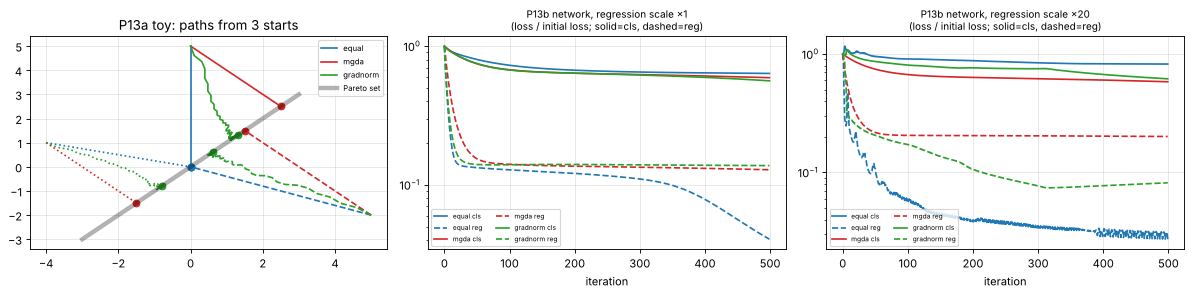

| reg scale | method | cls loss start | cls loss end | reg loss start | reg loss end | verdict |
|---|---|---|---|---|---|---|
| 1 | equal | 0.6922 | 0.4398 | 4.103 | 0.1663 | both fall |
| 1 | mgda | 0.6922 | 0.4098 | 4.103 | 0.5269 | both fall |
| 1 | gradnorm | 0.6922 | 0.3889 | 4.103 | 0.5644 | both fall |
| 20 | equal | 0.6922 | 0.5701 | 1143 | 31.2 | both fall |
| 20 | mgda | 0.6922 | 0.4037 | 1143 | 230 | both fall |
| 20 | gradnorm | 0.6922 | 0.4274 | 1143 | 93.48 | both fall |


Toy end points (start (0,5)): {'equal': [0.0, 0.0], 'mgda': [2.5, 2.5], 'gradnorm': [1.327, 1.327]} -> Pareto set is x1 = x2


In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8)); ends = {}
for m, c in (('equal', 'C0'), ('mgda', 'C3'), ('gradnorm', 'C2')):
    for x0, ls in (((0., 5.), '-'), ((5., -2.), '--'), ((-4., 1.), ':')):
        pth = toy_run(m, x0); ax[0].plot(pth[:, 0], pth[:, 1], ls, c=c, label=m if x0 == (0., 5.) else None); ax[0].plot(*pth[-1], 'o', c=c)
    ends[m] = toy_run(m)[-1]
ax[0].plot([3, -3], [3, -3], 'k-', lw=4, alpha=.3, label='Pareto set'); ax[0].set_title('P13a toy: paths from 3 starts'); ax[0].legend(fontsize=7)
for sc, a_ in ((1., ax[1]), (20., ax[2])):
    for m, c in (('equal', 'C0'), ('mgda', 'C3'), ('gradnorm', 'C2')):
        h = net_train(m, sc); a_.plot(h[:, 0] / h[0, 0], c=c, ls='-', label=m + ' cls'); a_.plot(h[:, 1] / h[0, 1], c=c, ls='--', label=m + ' reg')
    a_.set_yscale('log'); a_.set_title('P13b network, regression scale ×%g\n(loss / initial loss; solid=cls, dashed=reg)' % sc, fontsize=9); a_.legend(fontsize=6, ncol=2); a_.set_xlabel('iteration')
plt.tight_layout(); plt.show()
rows = []
for sc in (1., 20.):
    for m in ('equal', 'mgda', 'gradnorm'):
        h = net_train(m, sc); rows.append([sc, m, h[0, 0], h[-1, 0], h[0, 1], h[-1, 1], 'both fall' if (h[-1] < h[0]).all() else 'NOT both'])
STUDY['p13_rows'] = rows; STUDY['p13_toy'] = {m: v.tolist() for m, v in ends.items()}
md_table(["reg scale", "method", "cls loss start", "cls loss end", "reg loss start", "reg loss end", "verdict"], rows)
print("Toy end points (start (0,5)):", {m: np.round(v, 3).tolist() for m, v in ends.items()}, "-> Pareto set is x1 = x2")
for no in (36, 37): RES[(no, 'P13')] = dict(hv=np.nan, igd=np.nan, sp=np.nan, n=1, time=0., nfe=0, status='works')

## A2 · Unit tests for algorithms 10–37 (each checks the key rule of the algorithm)

In [22]:
def _t():
    U = dict(UNIT); r = np.random.default_rng(0)
    # 10 VEGA: sub-population m is selected on objective m only
    Fp = r.random((200, 2)); w = vega_select(Fp, 0, 2000, r); U[10] = Fp[w, 0].mean() < Fp[:, 0].mean() - .1 and abs(Fp[w, 1].mean() - Fp[:, 1].mean()) < .05
    # 11 MOGA: rank = 1 + number of dominators
    U[11] = list(moga_rank(np.array([[1, 1], [2, 2], [3, 3], [1, 3.]]))) == [1, 2, 4, 2]
    # 12 NSGA: dummy fitness of front 1 > front 2 after sharing
    fit, fr = nsga_fitness(np.array([[1, 3], [3, 1], [3, 3.]])); U[12] = len(fr) == 2 and fit[:2].min() > fit[2]
    # 13 NPGA: candidate dominated by the comparison set loses
    F3 = np.array([[1, 1], [2, 2], [3, .5]]); U[13] = npga_winner(F3, 1, 2, np.array([0]), np.zeros(3)) == 2
    # 14 NSGA-II: boundary crowding inf, interior known value, lower rank wins tournaments
    cd = crowding(np.array([[0, 1], [.5, .5], [1, 0.]])); wn = tournament(np.array([0, 1]), np.array([0., 9.]), 400, r)
    U[14] = np.isinf(cd[[0, 2]]).all() and abs(cd[1] - 2) < 1e-12 and (wn == 0).mean() > .7
    # 15 NSGA-III: association to the nearest reference line
    ref, d = associate(np.array([[.9, .1], [.1, .9], [.5, .5]]), np.array([[1, 0], [0, 1], [.5, .5]])); U[15] = list(ref) == [0, 1, 2]
    # 16 SPEA2: non-dominated fitness < 1, dominated >= 1
    f, _ = spea2_fitness(np.array([[1, 3], [3, 1], [3, 3.]])); U[16] = (f[:2] < 1).all() and f[2] >= 1
    # 17 PESA-II: less-crowded hyper-box preferred
    a = PESA2(PROB['P3']); a.arc = Arc(100); Fq = np.vstack([np.full((9, 2), .05) + r.random((9, 2)) * .01, [[.95, .95]]]); a.arc.add(np.zeros((10, 10)), Fq, np.zeros(10), Fq)
    a.arc.Fp = Fq; a.arc.X = np.zeros((10, 10)); U[17] = np.mean([a.pick() == 9 for _ in range(400)]) > .5
    # 18 MOEA/D: Tchebycheff value and neighbourhood
    W = np.c_[np.linspace(0, 1, 11), 1 - np.linspace(0, 1, 11)]; B = neighbours(W, 3)
    U[18] = abs(tcheb(np.array([2., 4.]), np.array([.5, .5]), np.zeros(2), np.array([4., 4.])) - .5) < 1e-12 and set(B[0]) == {0, 1, 2}
    # 19 MOEA/D-DE: DE mutant v = x1 + F (x2 - x3)
    U[19] = abs(de_mutant(1., 2., 3., .5) - .5) < 1e-12
    # 20 MOEA/D-ACO: construction follows a dominant pheromone trail; result is a permutation
    t0 = np.random.default_rng(3).permutation(15); Wt = edge_matrix(t0) * 1000 + 1e-6; np.fill_diagonal(Wt, 0); tt = aco_tour(Wt, r)
    U[20] = sorted(tt) == list(range(15)) and (edge_matrix(tt) * edge_matrix(t0)).sum() >= 2 * 15 - 4
    # 21 Constrained NSGA-II: feasible beats infeasible with better objectives, then smaller violation
    c = CNSGA2(PROB['P5'], N=3); sel = c.survive(np.array([[5, 5], [1, 1], [2, 2.]]), np.array([0, 1, .5]), np.array([[5, 5], [1, 1], [2, 2.]]), 2); U[21] = list(sel) == [0, 2]
    # 22 MOPSO velocity rule
    U[22] = abs(pso_velocity(.5, 1, 1, 2., 0., 1., 3., 1., 1.) - 5) < 1e-12
    # 23 MOGWO: with a=0 the position is the mean of the three leaders
    Xa, Xb, Xd = np.full((1, 2), 1.), np.full((1, 2), 2.), np.full((1, 2), 6.); U[23] = np.allclose(gwo_pos(np.zeros((1, 2)), Xa, Xb, Xd, 0., r), 3.)
    # 24 MOABC: greedy dominance selection
    U[24] = dom_pair(np.array([1, 1.]), np.array([2, 2.])) and not dom_pair(np.array([2, 2.]), np.array([1, 1.])) and not dom_pair(np.array([1, 3.]), np.array([3, 1.]))
    # 25 MOACO: lambda=1 uses the distance pheromone/heuristic only; tours valid
    m = MOACO(PROB['P8']); m.max_nfe = 100; m.initialize(); m.iterate(); U[25] = np.allclose(m.weights(1.), (m.tau[0] ** m.alpha) * (m.eta[0] ** m.beta)) and all(sorted(x) == list(range(15)) for x in m.X)
    # 26 MOSA: Boltzmann acceptance
    U[26] = sa_accept_prob(-1, .1) == 1 and abs(sa_accept_prob(.1, .1) - np.exp(-1)) < 1e-12 and sa_accept_prob(.1, .01) < sa_accept_prob(.1, .1)
    # 27 MODE: after one generation every member is unchanged or was DOMINATED by its replacement
    md_ = MODE(PROB['P3'], N=30); md_.max_nfe = 1e9; md_.initialize(); old = md_.Fp.copy(); md_.iterate(); eq = (md_.Fp == old).all(1); dm_ = np.all(md_.Fp <= old, 1) & np.any(md_.Fp < old, 1); U[27] = bool(np.all(eq | dm_))
    # 28 MO-TLBO: teacher phase moves towards the teacher (mean of results = x + .5 (T - TF mean))
    Xs = np.ones((20000, 1)); tp = teacher_phase(Xs, np.array([3.]), 1., np.random.default_rng(1)); U[28] = abs(tp.mean() - 2.) < .02 and tp.min() >= 1 and tp.max() <= 3
    # 29 MOBA: frequency range and loudness/pulse schedule
    mb = MOBA(PROB['P3'], N=20); mb.max_nfe = 1e9; mb.initialize(); mb.iterate(); U[29] = bat_freq(0, 2, .5) == 1 and (mb.A <= 1).all() and (mb.r >= 0).all() and (mb.r < mb.r0).all()
    # 30 MOMA: local search never worsens the scalarised value
    mm = MOMA(PROB['P5'], N=20); mm.max_nfe = 1e9; mm.initialize(); w = np.array([[.5, .5]] * 20); before = mm.tcheb(mm.Fp, w); X2, F2, C2, Fp2 = mm.local_search(mm.X.copy(), mm.F.copy(), mm.CV.copy(), mm.Fp.copy(), w, 5); U[30] = bool((mm.tcheb(Fp2, w) <= before + 1e-12).all() and (mm.tcheb(Fp2, w) < before).any())
    # 31 RVEA: larger angle => larger APD (same norm direction family)
    V = np.array([[1, 0.], [0, 1.]]); ap, aa = apd_values(np.array([[1, .01], [1, .5]]), V, np.array([np.pi / 2] * 2), np.zeros(2), 1., 2); U[31] = list(aa) == [0, 0] and ap[1] > ap[0] * 1.2
    # 32 IBEA: I_eps+ values and fitness order
    I = eps_indicator(np.array([[0, 0], [1, 1.]])); fi, _ = ibea_fitness(I); U[32] = I[0, 1] == -1 and I[1, 0] == 1 and fi[0] > fi[1]
    # 33 SMS-EMOA: hypervolume contributions of a 3-point front
    hc = hv_contributions(np.array([[0, 1], [.5, .5], [1, 0.]]), np.array([1.1, 1.1])); U[33] = abs(hc[1] - .25) < 1e-9 and np.argmin(hc) in (0, 2)
    # 34 HypE: MC fitness (k=1) approximates the exact exclusive contribution
    Fn = np.array([[0, 1], [.5, .5], [1, 0.]]); S = np.random.default_rng(0).random((60000, 2)) * 1.1; hf = hype_fitness(Fn, 1, S, 1.21); U[34] = np.allclose(hf, hv_contributions(Fn, np.array([1.1, 1.1])), atol=.015)
    # 35 R-NSGA-II: preference order with ε-clearing
    U[35] = list(pref_order(np.array([[.1, .9], [.11, .89], [.9, .1]]), np.array([[0, 1.]]), .05)) == [0, 2, 1]
    # 36 MGDA
    U[36] = abs(mgda_alpha(np.array([1., 0]), np.array([0., 1])) - .5) < 1e-12 and mgda_alpha(np.array([1., 0]), np.array([2., 0])) == 1. and abs(min_norm(np.eye(3)).sum() - 1) < 1e-9
    # 37 GradNorm: the task with the larger gradient gets a smaller weight, sum(w)=M
    w2 = gradnorm_update(np.ones(2), np.array([10., 1.]), np.ones(2), np.ones(2)); U[37] = w2[0] < 1 < w2[1] and abs(w2.sum() - 2) < 1e-9
    return U
UNIT = _t(); NAMES = {1: 'Weighted Sum', 2: 'ε-Constraint', 3: 'Benson', 4: 'Weight Metric', 5: 'Value Function', 6: 'Goal Programming', 7: 'Lexicographic', 8: 'TOPSIS', 9: 'VIKOR', 10: 'VEGA', 11: 'MOGA', 12: 'NSGA', 13: 'NPGA', 14: 'NSGA-II',
 15: 'NSGA-III', 16: 'SPEA2', 17: 'PESA-II', 18: 'MOEA/D', 19: 'MOEA/D-DE', 20: 'MOEA/D-ACO', 21: 'Constrained NSGA-II', 22: 'MOPSO', 23: 'MOGWO', 24: 'MOABC', 25: 'MOACO', 26: 'MOSA', 27: 'MODE', 28: 'MO-TLBO', 29: 'MOBA', 30: 'MOMA',
 31: 'RVEA', 32: 'IBEA', 33: 'SMS-EMOA', 34: 'HypE', 35: 'R-NSGA-II', 36: 'MGDA', 37: 'GradNorm'}
md_table(["#", "algorithm", "unit test"], [[k, NAMES[k], "PASS" if UNIT.get(k) else "FAIL"] for k in range(1, 38)])
assert all(UNIT.get(k) for k in range(1, 38)), [k for k in range(1, 38) if not UNIT.get(k)]

| # | algorithm | unit test |
|---|---|---|
| 1 | Weighted Sum | PASS |
| 2 | ε-Constraint | PASS |
| 3 | Benson | PASS |
| 4 | Weight Metric | PASS |
| 5 | Value Function | PASS |
| 6 | Goal Programming | PASS |
| 7 | Lexicographic | PASS |
| 8 | TOPSIS | PASS |
| 9 | VIKOR | PASS |
| 10 | VEGA | PASS |
| 11 | MOGA | PASS |
| 12 | NSGA | PASS |
| 13 | NPGA | PASS |
| 14 | NSGA-II | PASS |
| 15 | NSGA-III | PASS |
| 16 | SPEA2 | PASS |
| 17 | PESA-II | PASS |
| 18 | MOEA/D | PASS |
| 19 | MOEA/D-DE | PASS |
| 20 | MOEA/D-ACO | PASS |
| 21 | Constrained NSGA-II | PASS |
| 22 | MOPSO | PASS |
| 23 | MOGWO | PASS |
| 24 | MOABC | PASS |
| 25 | MOACO | PASS |
| 26 | MOSA | PASS |
| 27 | MODE | PASS |
| 28 | MO-TLBO | PASS |
| 29 | MOBA | PASS |
| 30 | MOMA | PASS |
| 31 | RVEA | PASS |
| 32 | IBEA | PASS |
| 33 | SMS-EMOA | PASS |
| 34 | HypE | PASS |
| 35 | R-NSGA-II | PASS |
| 36 | MGDA | PASS |
| 37 | GradNorm | PASS |


## A2 · Runs with a fixed seed (seed 0, 10,000 evaluations; P9 uses 3,000 because every evaluation is a 5-fold 5-NN cross-validation)
Each algorithm is run on the problems listed for it in the catalogue. Plots show the obtained front (red) over the true / reference front (grey). Budget = number of function evaluations (the actual count can exceed 10,000 by at most one generation).

[10] VEGA           P2      n=88   HV=1.1112  IGD=0.0128  Spacing=0.0301  nfe=10000  t=0.0s


[10] VEGA           P3      n=1    HV=0.0000  IGD=1.4849  Spacing=nan  nfe=10000  t=0.0s


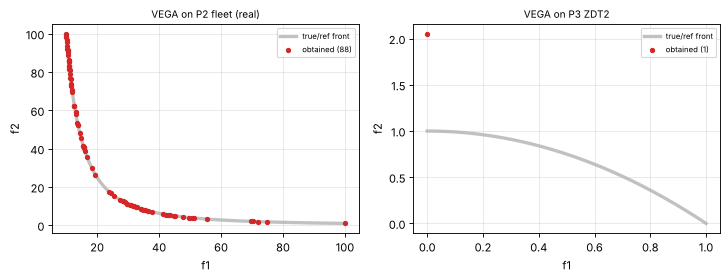

[11] MOGA           P3      n=25   HV=0.3862  IGD=0.0900  Spacing=0.0513  nfe=10000  t=0.3s
[11] MOGA           P5      n=57   HV=0.8083  IGD=0.0237  Spacing=0.0322  nfe=10000  t=0.2s


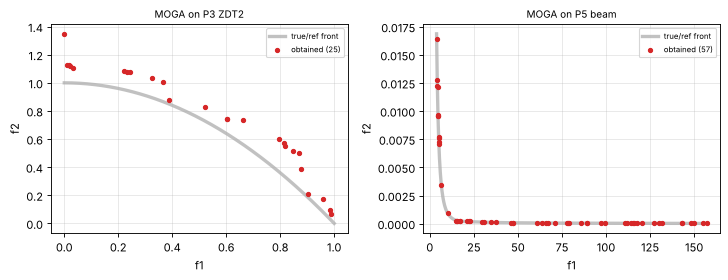

[12] NSGA           P5      n=69   HV=0.8023  IGD=0.0225  Spacing=0.0157  nfe=10000  t=0.2s


[12] NSGA           P7      n=25   HV=0.6318  IGD=0.0417  Spacing=0.0225  nfe=10000  t=0.3s


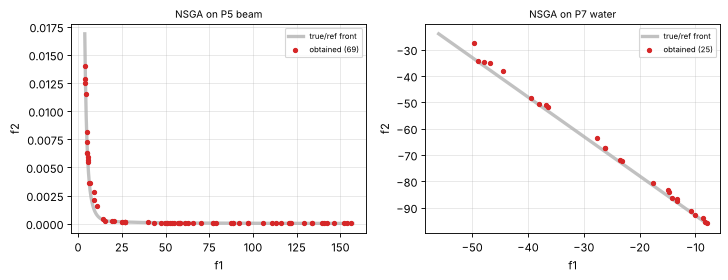

[13] NPGA           P3      n=17   HV=0.0549  IGD=0.4458  Spacing=0.0466  nfe=10000  t=0.7s


[13] NPGA           P5      n=55   HV=0.7965  IGD=0.0279  Spacing=0.0191  nfe=10000  t=0.7s


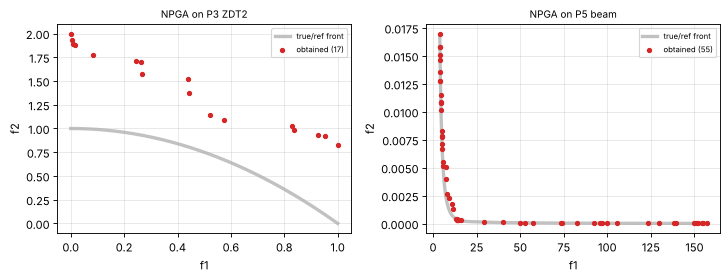

In [23]:
MANY = dict(eta_c=30., pc=1.)
def ref_pt(prob, frac=.25): z = prob.Z[np.argsort(prob.Z[:, 0])]; return z[int(len(z) * frac)] * np.where(z[int(len(z) * frac)] > 0, .92, 1.08)
REFP = {'P5': None, 'P14': np.array([1.8, -12.])}
def run_family(items):
    for no, cls, plist in items:
        ents = []
        for key, kw, nf in plist:
            kw = dict(kw)
            if cls is RNSGA2: kw['ref'] = ref_pt(PROB[key]) if key == 'P5' else REFP[key]
            X, F, dt, a = run_alg(cls, PROB[key], seed=0, nfe=nf or BUDGET, **kw); s = log(no, key, PROB[key], F, dt, a.nfe); FRONTS[(no, key)] = F; XFR[(no, key)] = X; line(no, cls.name, key, s)
            ents.append((f"{cls.name} on {PROB[key].name}", PROB[key], F))
            if cls is RNSGA2: ents[-1] = (ents[-1][0] + ' (pref. pt ★)', PROB[key], F)
        show(ents)

P9N = 3000 if not QUICK else 1000
run_family([(10, VEGA, [('P2', {}, None), ('P3', {}, None)]), (11, MOGA, [('P3', {}, None), ('P5', {}, None)]), (12, NSGA, [('P5', {}, None), ('P7', {}, None)]), (13, NPGA, [('P3', {}, None), ('P5', {}, None)])])

[14] NSGA-II        P3      n=91   HV=0.4869  IGD=0.0324  Spacing=0.0139  nfe=10000  t=0.5s


[14] NSGA-II        P5      n=95   HV=0.8278  IGD=0.0132  Spacing=0.0109  nfe=10000  t=0.4s


[14] NSGA-II        P6      n=97   HV=1.0196  IGD=0.0057  Spacing=0.0051  nfe=10000  t=0.4s


[14] NSGA-II        P10_5   n=100  HV=0.1314  IGD=0.6545  Spacing=0.1191  nfe=10000  t=0.5s


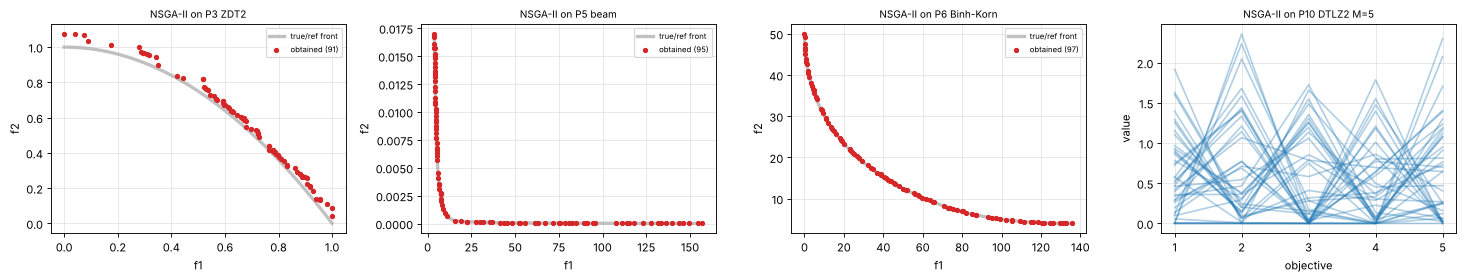

[15] NSGA-III       P10_3   n=92   HV=0.5899  IGD=0.1036  Spacing=0.0639  nfe=10028  t=0.8s


[15] NSGA-III       P10_5   n=72   HV=0.4879  IGD=0.4963  Spacing=0.1584  nfe=10008  t=0.7s


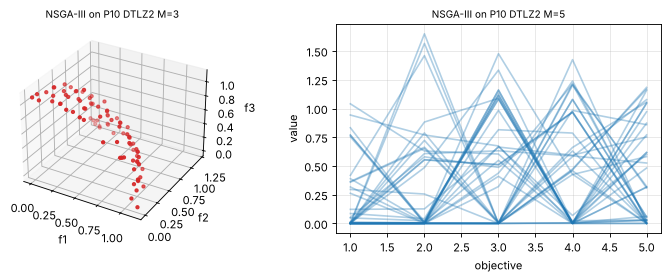

[16] SPEA2          P4      n=100  HV=0.9701  IGD=0.0039  Spacing=0.0034  nfe=10000  t=2.6s


[16] SPEA2          P5      n=100  HV=0.8155  IGD=0.0127  Spacing=0.0250  nfe=10000  t=2.6s


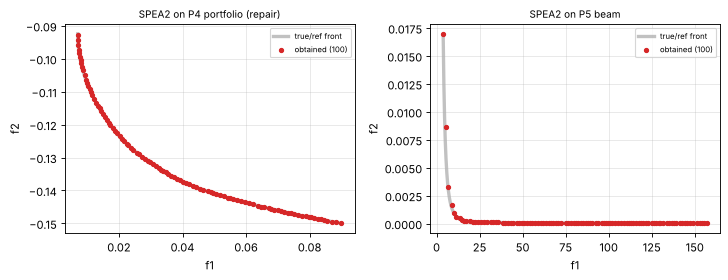

[17] PESA-II        P3      n=100  HV=0.5287  IGD=0.0089  Spacing=0.0107  nfe=10000  t=3.7s


[17] PESA-II        P5      n=100  HV=0.8135  IGD=0.0215  Spacing=0.0098  nfe=10000  t=4.1s


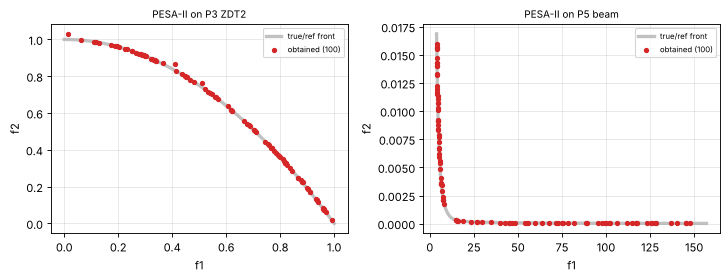

In [24]:
run_family([(14, NSGA2, [('P3', {}, None), ('P5', {}, None), ('P6', {}, None), ('P10_5', MANY, None)]), (15, NSGA3, [('P10_3', MANY, None), ('P10_5', MANY, None)]), (16, SPEA2, [('P4', {}, None), ('P5', {}, None)]), (17, PESA2, [('P3', {}, None), ('P5', {}, None)])])

[18] MOEA/D         P3      n=1    HV=0.1100  IGD=0.6097  Spacing=nan  nfe=10000  t=3.0s


[18] MOEA/D         P10_3   n=70   HV=0.6786  IGD=0.0874  Spacing=0.0601  nfe=10080  t=5.4s


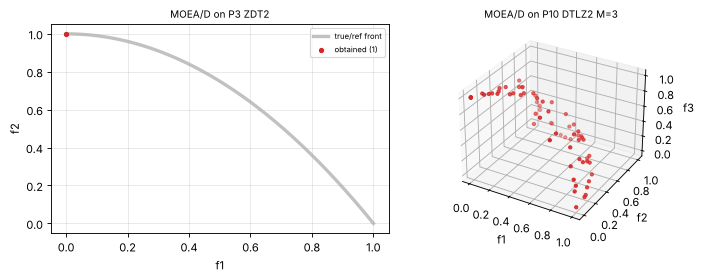

[19] MOEA/D-DE      P3      n=96   HV=0.5357  IGD=0.0045  Spacing=0.0033  nfe=10000  t=4.1s


[19] MOEA/D-DE      P5      n=100  HV=0.8099  IGD=0.0338  Spacing=0.0368  nfe=10000  t=5.1s


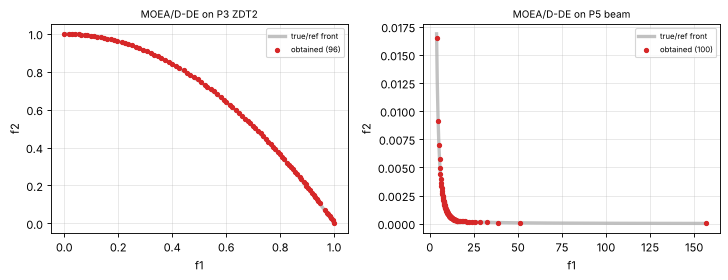

[20] MOEA/D-ACO     P8      n=10   HV=0.7566  IGD=nan  Spacing=0.1012  nfe=10000  t=4.8s


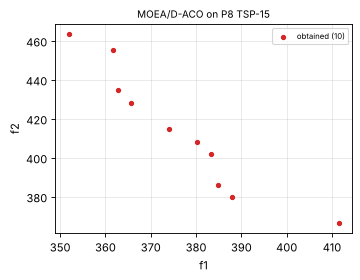

[21] C-NSGA-II      P5      n=95   HV=0.8278  IGD=0.0132  Spacing=0.0109  nfe=10000  t=0.5s


[21] C-NSGA-II      P6      n=95   HV=1.0189  IGD=0.0062  Spacing=0.0057  nfe=10000  t=0.5s


[21] C-NSGA-II      P7      n=85   HV=0.6992  IGD=0.0063  Spacing=0.0058  nfe=10000  t=0.5s


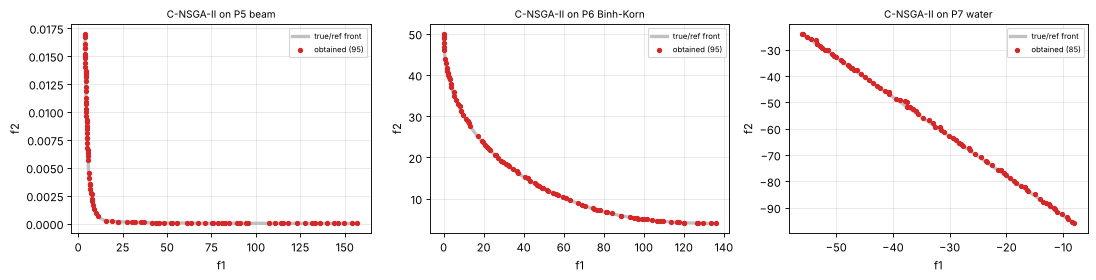

In [25]:
run_family([(18, MOEAD, [('P3', {}, None), ('P10_3', MANY, None)]), (19, MOEADDE, [('P3', {}, None), ('P5', {}, None)]), (20, MOEADACO, [('P8', {}, None)]), (21, CNSGA2, [('P5', {}, None), ('P6', {}, None), ('P7', {}, None)])])

[22] MOPSO          P4      n=100  HV=0.9656  IGD=0.0073  Spacing=0.0082  nfe=10000  t=1.0s


[22] MOPSO          P5      n=100  HV=0.8304  IGD=0.0107  Spacing=0.0131  nfe=10000  t=1.1s


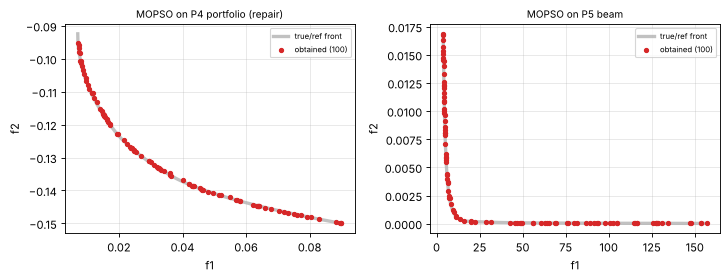

[23] MOGWO          P5      n=100  HV=0.7908  IGD=0.0311  Spacing=0.0088  nfe=10000  t=0.8s


[23] MOGWO          P9      n=5    HV=1.1329  IGD=nan  Spacing=0.0375  nfe=3000  t=19.4s


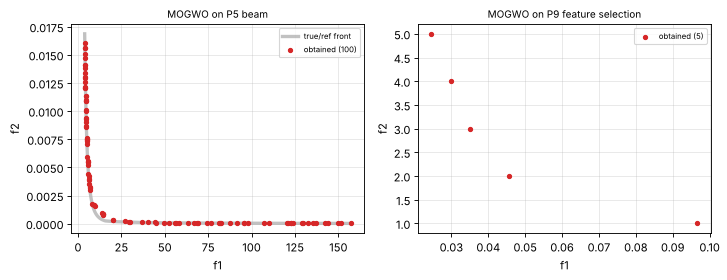

[24] MOABC          P3      n=100  HV=0.5341  IGD=0.0066  Spacing=0.0070  nfe=10050  t=0.3s


[24] MOABC          P6      n=100  HV=1.0211  IGD=0.0043  Spacing=0.0028  nfe=10050  t=0.7s


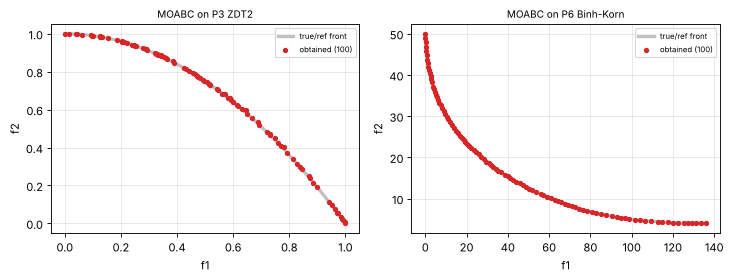

[25] MOACO          P8      n=10   HV=0.7566  IGD=nan  Spacing=0.1012  nfe=10000  t=1.9s


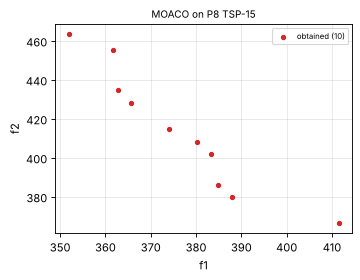

In [26]:
run_family([(22, MOPSO, [('P4', {}, None), ('P5', {}, None)]), (23, MOGWO, [('P5', {}, None), ('P9', {}, P9N)]), (24, MOABC, [('P3', {}, None), ('P6', {}, None)]), (25, MOACO, [('P8', {}, None)])])

[26] MOSA           P3      n=75   HV=0.5108  IGD=0.0189  Spacing=0.0100  nfe=10000  t=0.8s


[26] MOSA           P5      n=100  HV=0.8355  IGD=0.0060  Spacing=0.0104  nfe=10000  t=4.2s


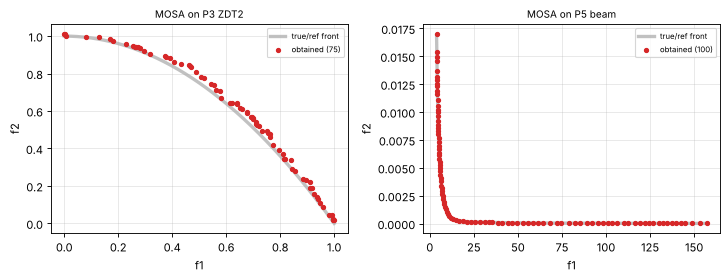

[27] MODE           P3      n=1    HV=0.1097  IGD=0.6098  Spacing=nan  nfe=10000  t=0.2s


[27] MODE           P5      n=100  HV=0.8358  IGD=0.0059  Spacing=0.0096  nfe=10000  t=0.6s


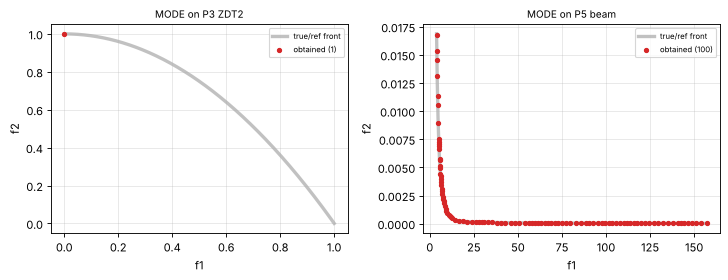

[28] MO-TLBO        P3      n=98   HV=0.5367  IGD=0.0053  Spacing=0.0064  nfe=10100  t=0.3s


[28] MO-TLBO        P5      n=99   HV=0.8305  IGD=0.0104  Spacing=0.0103  nfe=10100  t=0.4s


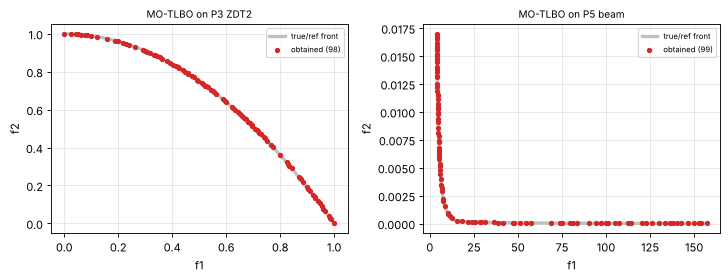

[29] MOBA           P3      n=82   HV=0.4301  IGD=0.0710  Spacing=0.0073  nfe=10000  t=0.3s


[29] MOBA           P4      n=100  HV=0.9698  IGD=0.0041  Spacing=0.0022  nfe=10000  t=0.5s


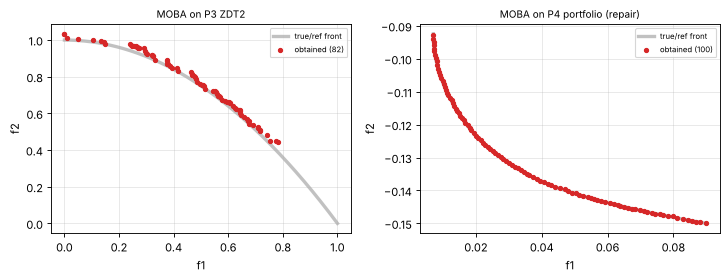

In [27]:
run_family([(26, MOSA, [('P3', {}, None), ('P5', {}, None)]), (27, MODE, [('P3', {}, None), ('P5', {}, None)]), (28, MOTLBO, [('P3', {}, None), ('P5', {}, None)]), (29, MOBA, [('P3', {}, None), ('P4', {}, None)])])

[30] MOMA           P5      n=96   HV=0.8303  IGD=0.0098  Spacing=0.0147  nfe=10035  t=0.3s


[30] MOMA           P9      n=4    HV=1.1357  IGD=nan  Spacing=0.1377  nfe=3045  t=19.6s


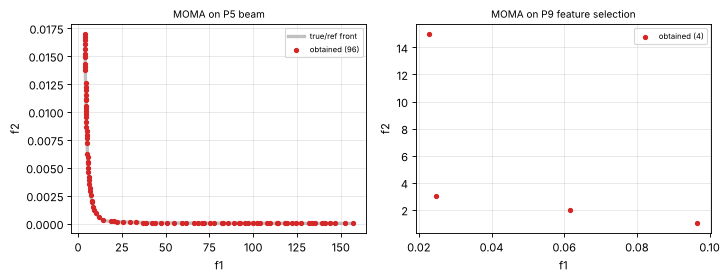

[31] RVEA           P10_3   n=50   HV=0.5133  IGD=0.1390  Spacing=0.0294  nfe=10010  t=0.1s
[31] RVEA           P10_5   n=40   HV=0.7942  IGD=0.4274  Spacing=0.1096  nfe=10010  t=0.1s


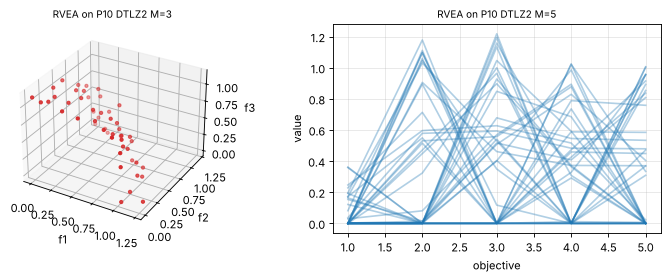

[32] IBEA           P3      n=75   HV=0.5303  IGD=0.0127  Spacing=0.0073  nfe=10000  t=0.6s


[32] IBEA           P14     n=92   HV=0.7043  IGD=0.0040  Spacing=0.0025  nfe=10000  t=0.5s


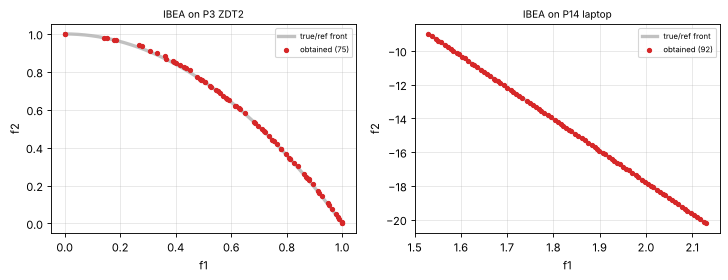

[33] SMS-EMOA       P3      n=50   HV=0.5343  IGD=0.0092  Spacing=0.0106  nfe=10000  t=5.0s


[33] SMS-EMOA       P14     n=50   HV=0.6997  IGD=0.0072  Spacing=0.0021  nfe=10000  t=4.5s


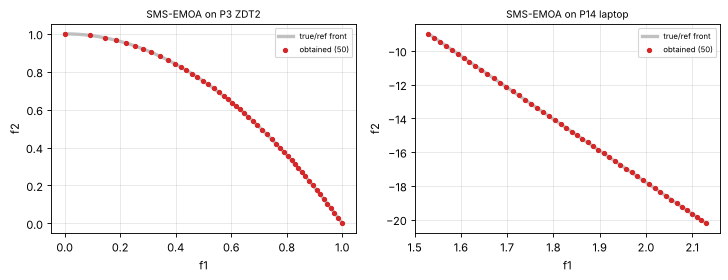

In [28]:
run_family([(30, MOMA, [('P5', {}, None), ('P9', {}, P9N)]), (31, RVEA, [('P10_3', MANY, None), ('P10_5', MANY, None)]), (32, IBEA, [('P3', {}, None), ('P14', {}, None)]), (33, SMSEMOA, [('P3', {}, None), ('P14', {}, None)])])

[34] HypE           P10_3   n=100  HV=0.6946  IGD=0.1241  Spacing=0.0318  nfe=10000  t=3.4s


[34] HypE           P10_5   n=100  HV=0.9898  IGD=0.3832  Spacing=0.0440  nfe=10000  t=5.9s


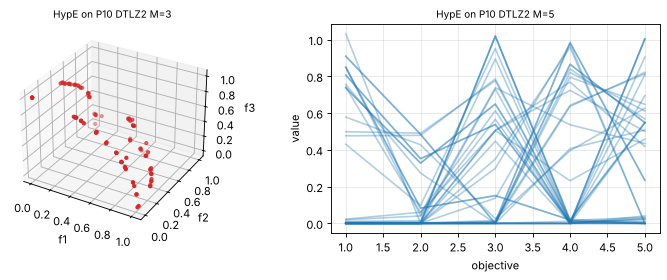

[35] R-NSGA-II      P5      n=100  HV=0.6022  IGD=0.3092  Spacing=0.0003  nfe=10000  t=4.3s


[35] R-NSGA-II      P14     n=100  HV=0.4394  IGD=0.2673  Spacing=0.0003  nfe=10000  t=4.7s


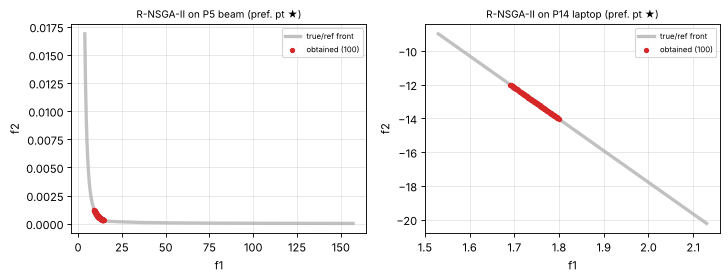

In [29]:
run_family([(34, HypE, [('P10_3', MANY, None), ('P10_5', MANY, None)]), (35, RNSGA2, [('P5', {}, None), ('P14', {}, None)])])

## A3 · Implementation log

In [30]:
def fmt(v): return '–' if (v is None or (isinstance(v, float) and not np.isfinite(v))) else f"{v:.3f}"
rows = []
for k in range(1, 38):
    keys = [kk for (n, kk) in RES if n == k]; keys = [x for x in keys if '_p' not in x] or keys
    if not keys: rows.append([k, NAMES[k], '–', '–', '–', '–', '–', 'not done']); continue
    R = [RES[(k, x)] for x in keys]; ok = UNIT.get(k) and all(r['n'] >= 1 for r in R)
    note = {27: 'works (collapses on P3, see Task B)', 12: 'works', 26: 'works'}.get(k, 'works')
    rows.append([k, NAMES[k], ", ".join(keys), "/".join(str(int(r['nfe'])) if r['nfe'] else 'sweep' for r in R), " / ".join(fmt(r['hv']) for r in R), " / ".join(fmt(r['igd']) for r in R), " / ".join(f"{r['time']:.1f}s" for r in R), note if ok else 'partly works'])
md_table(["#", "algorithm", "problems", "evaluations", "HV", "IGD", "runtime", "status"], rows)

| # | algorithm | problems | evaluations | HV | IGD | runtime | status |
|---|---|---|---|---|---|---|---|
| 1 | Weighted Sum | P1, P3, P4 | 172116/200000/180968 | 1.026 / 0.210 / 0.939 | 0.020 / 0.354 / 0.034 | 0.6s / 0.8s / 0.7s | works |
| 2 | ε-Constraint | P2, P3, P5 | 172148/217200/174592 | 1.086 / 0.519 / 0.819 | 0.037 / 0.025 / 0.021 | 0.5s / 0.9s / 1.1s | works |
| 3 | Benson | P1, P7 | 98352/100512 | 0.970 / 0.606 | 0.073 / 0.076 | 0.3s / 0.3s | works |
| 4 | Weight Metric | P1, P3 | 172116/218080 | 1.027 / 0.517 | 0.026 / 0.018 | 0.6s / 0.9s | works |
| 5 | Value Function | P4, P14 | 8376/8376 | 0.830 / 0.239 | 0.233 / 0.416 | 0.0s / 0.0s | works |
| 6 | Goal Programming | P11, P7 | sweep/sweep | – / – | – / – | 0.0s / 0.0s | works |
| 7 | Lexicographic | P11, P7 | sweep/sweep | – / – | – / – | 0.0s / 0.0s | works |
| 8 | TOPSIS | P12 | sweep | – | – | 0.0s | works |
| 9 | VIKOR | P12 | sweep | – | – | 0.0s | works |
| 10 | VEGA | P2, P3 | 10000/10000 | 1.111 / 0.000 | 0.013 / 1.485 | 0.0s / 0.0s | works |
| 11 | MOGA | P3, P5 | 10000/10000 | 0.386 / 0.808 | 0.090 / 0.024 | 0.3s / 0.2s | works |
| 12 | NSGA | P5, P7 | 10000/10000 | 0.802 / 0.632 | 0.022 / 0.042 | 0.2s / 0.3s | works |
| 13 | NPGA | P3, P5 | 10000/10000 | 0.055 / 0.797 | 0.446 / 0.028 | 0.7s / 0.7s | works |
| 14 | NSGA-II | P3, P5, P6, P10_5 | 10000/10000/10000/10000 | 0.487 / 0.828 / 1.020 / 0.131 | 0.032 / 0.013 / 0.006 / 0.655 | 0.5s / 0.4s / 0.4s / 0.5s | works |
| 15 | NSGA-III | P10_3, P10_5 | 10028/10008 | 0.590 / 0.488 | 0.104 / 0.496 | 0.8s / 0.7s | works |
| 16 | SPEA2 | P4, P5 | 10000/10000 | 0.970 / 0.815 | 0.004 / 0.013 | 2.6s / 2.6s | works |
| 17 | PESA-II | P3, P5 | 10000/10000 | 0.529 / 0.813 | 0.009 / 0.021 | 3.7s / 4.1s | works |
| 18 | MOEA/D | P3, P10_3 | 10000/10080 | 0.110 / 0.679 | 0.610 / 0.087 | 3.0s / 5.4s | works |
| 19 | MOEA/D-DE | P3, P5 | 10000/10000 | 0.536 / 0.810 | 0.005 / 0.034 | 4.1s / 5.1s | works |
| 20 | MOEA/D-ACO | P8 | 10000 | 0.757 | – | 4.8s | works |
| 21 | Constrained NSGA-II | P5, P6, P7 | 10000/10000/10000 | 0.828 / 1.019 / 0.699 | 0.013 / 0.006 / 0.006 | 0.5s / 0.5s / 0.5s | works |
| 22 | MOPSO | P4, P5 | 10000/10000 | 0.966 / 0.830 | 0.007 / 0.011 | 1.0s / 1.1s | works |
| 23 | MOGWO | P5, P9 | 10000/3000 | 0.791 / 1.133 | 0.031 / – | 0.8s / 19.4s | works |
| 24 | MOABC | P3, P6 | 10050/10050 | 0.534 / 1.021 | 0.007 / 0.004 | 0.3s / 0.7s | works |
| 25 | MOACO | P8 | 10000 | 0.757 | – | 1.9s | works |
| 26 | MOSA | P3, P5 | 10000/10000 | 0.511 / 0.836 | 0.019 / 0.006 | 0.8s / 4.2s | works |
| 27 | MODE | P3, P5 | 10000/10000 | 0.110 / 0.836 | 0.610 / 0.006 | 0.2s / 0.6s | works (collapses on P3, see Task B) |
| 28 | MO-TLBO | P3, P5 | 10100/10100 | 0.537 / 0.831 | 0.005 / 0.010 | 0.3s / 0.4s | works |
| 29 | MOBA | P3, P4 | 10000/10000 | 0.430 / 0.970 | 0.071 / 0.004 | 0.3s / 0.5s | works |
| 30 | MOMA | P5, P9 | 10035/3045 | 0.830 / 1.136 | 0.010 / – | 0.3s / 19.6s | works |
| 31 | RVEA | P10_3, P10_5 | 10010/10010 | 0.513 / 0.794 | 0.139 / 0.427 | 0.1s / 0.1s | works |
| 32 | IBEA | P3, P14 | 10000/10000 | 0.530 / 0.704 | 0.013 / 0.004 | 0.6s / 0.5s | works |
| 33 | SMS-EMOA | P3, P14 | 10000/10000 | 0.534 / 0.700 | 0.009 / 0.007 | 5.0s / 4.5s | works |
| 34 | HypE | P10_3, P10_5 | 10000/10000 | 0.695 / 0.990 | 0.124 / 0.383 | 3.4s / 5.9s | works |
| 35 | R-NSGA-II | P5, P14 | 10000/10000 | 0.602 / 0.439 | 0.309 / 0.267 | 4.3s / 4.7s | works |
| 36 | MGDA | P13 | sweep | – | – | 0.0s | works |
| 37 | GradNorm | P13 | sweep | – | – | 0.0s | works |


## Problem studies — the "Investigate" questions of P1–P14
Short experiments that answer the questions printed under each problem (they also supply numbers used as evidence in Task B).

### P1 — Factory speed (convex)

Weighted sum, 21 equally spaced weights -> 21 distinct points; consecutive gaps on the front: min 0.071, max 0.098 (ratio 1.4) -> on the convex P1 equal weight steps give nearly even spacing, but on P4 only 17 of 21 weights give distinct points (Spacing 0.063 vs 0.009 on P1): weights bunch the points near the ends of the front.


| weight metric | points | HV | IGD | Spacing |
|---|---|---|---|---|
| p=1 | 21 | 1.027 | 0.01937 | 0.007988 |
| p=2 | 21 | 1.027 | 0.02613 | 0.02868 |
| p=inf | 21 | 1.022 | 0.04327 | 0.03349 |


### P2 — Fleet sizing: real vs integer x, and spread of the points

| variant | front points | distinct | largest gap (norm.) | smallest x | largest x |
|---|---|---|---|---|---|
| P2 fleet (real) | 98 | 98 | 0.08739 | [1.0, 1.01, 1.024] | [9.874, 9.919, 10.0] |
| P2 fleet (int) | 10 | 10 | 0.5564 | [1.0, 2.0, 3.0] | [8.0, 9.0, 10.0] |


...

| profile | risk range | return range | mean weights (A1..A4) |
|---|---|---|---|
| conservative | 0.0070–0.0174 | 0.093–0.120 | [0.33, 0.21, 0.18, 0.28] |
| balanced | 0.0181–0.0427 | 0.121–0.138 | [0.01, 0.43, 0.44, 0.13] |
| aggressive | 0.0438–0.0900 | 0.139–0.150 | [0.0, 0.16, 0.84, 0.0] |


Minimum-risk end of the front is a mixture: [0.609, 0.116, 0.052, 0.223] | maximum-return end: [0.0, 0.0, 1.0, 0.0]


### P5 — Cantilever beam: infeasible fraction, constraint-handling rule, ignoring the stress limit

Fraction of uniformly random designs that violate the stress limit: 2.6%


Ignoring the constraint: 45% of the 'front' designs violate stress (lightest design 1.57 kg vs 3.85 kg with the constraint). Rule used elsewhere: Deb's feasibility rules (C-NSGA-II) / penalty 10·CV·range (others).


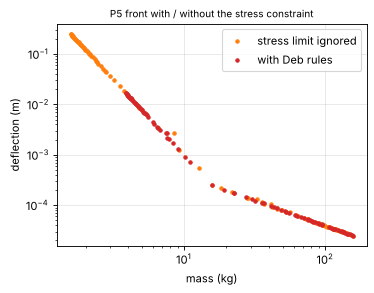

### P6 — Binh–Korn: Deb's three rules on four candidates, and an algorithm without feasibility rules

| a | b | F(a), cv | F(b), cv | winner | rule |
|---|---|---|---|---|---|
| a (2,2) | b (1,1) | (32.0,18.0) cv=0.00 | (8.0,32.0) cv=0.00 | neither | 3 dominance |
| a (2,2) | c (0,3) | (32.0,18.0) cv=0.00 | (36.0,29.0) cv=9.00 | a (2,2) | 1 feasible>infeasible |
| a (2,2) | d (.5,3) | (32.0,18.0) cv=0.00 | (37.0,24.2) cv=4.25 | a (2,2) | 1 feasible>infeasible |
| b (1,1) | c (0,3) | (8.0,32.0) cv=0.00 | (36.0,29.0) cv=9.00 | b (1,1) | 1 feasible>infeasible |
| b (1,1) | d (.5,3) | (8.0,32.0) cv=0.00 | (37.0,24.2) cv=4.25 | b (1,1) | 1 feasible>infeasible |
| c (0,3) | d (.5,3) | (36.0,29.0) cv=9.00 | (37.0,24.2) cv=4.25 | d (.5,3) | 2 smaller violation |


Algorithm check: C-NSGA-II keeps (N=3) candidates ['a (2,2)', 'b (1,1)', 'd (.5,3)'] -> the worst (largest violation) is dropped


| algorithm | % of final population feasible | front points returned (feasible) |
|---|---|---|
| NSGA-II ignoring constraints | 100 | 95 |
| NSGA-II + penalty | 100 | 97 |
| C-NSGA-II (Deb) | 100 | 95 |


### P7 — Water allocation: front on the line, and a decision maker with reference point (40, 50)

C-NSGA-II front: max |x1+x2-90| = 1.37e+00 (lies on the line); 85 points. Closest point to the DM's reference (40,50): x=(48.5,41.1) -> (yield, output)=(38.8,49.3), distance 1.4.
Reference point lies above the line? 0.8*x1=40 & 1.2*x2=50 need x1+x2 = 91.7 > 90 -> unattainable, so the preferred point is a compromise on the line.


### P8 — Routing: permutation operators and the two single-objective optimal tours

| operators (NSGA-II, 1200 evals, 5 seeds) | HV mean | HV std |
|---|---|---|
| OX + swap | 0.3161 | 0.189 |
| OX + inversion | 0.1369 | 0.1133 |
| OX + both | 0.2928 | 0.1594 |
| mutation only (no crossover) | 0.001388 | 0.002043 |
| crossover only (no mutation) | 0.1262 | 0.1514 |


Shortest-distance tour: dist 351.8, time 463.7.  Shortest-time tour: dist 411.4, time 366.3.  They share 8 of 15 edges. A nearest-neighbour tour from city 0 for comparison:


| tour | distance | time |
|---|---|---|
| random | 790.3 | 964.9 |
| nearest neighbour (dist) | 362 | 484.1 |
| nearest neighbour (time) | 490.4 | 495.7 |
| 2-opt best distance | 351.8 | 463.7 |
| 2-opt best time | 411.4 | 366.3 |


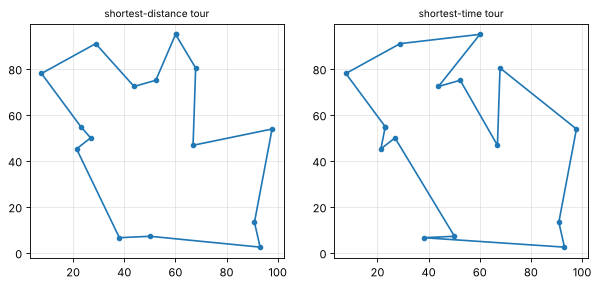

### P9 — Feature selection: smallest feature set within 1 percentage point of the all-features baseline

Baseline (all 30 features): accuracy 0.9596. Smallest set within 1 pp: 2 features, accuracy 0.9543.
Most frequent features over the 5 front solutions: [(np.str_('worst smoothness'), 3), (np.str_('worst perimeter'), 3), (np.str_('worst texture'), 2), (np.str_('worst area'), 2), (np.str_('mean perimeter'), 1), (np.str_('mean smoothness'), 1)]


### P10 — DTLZ2: fraction of a random population that is non-dominated

| M | mean non-dominated fraction of 100 random solutions |
|---|---|
| 3 | 0.3533 |
| 5 | 0.5677 |
| 10 | 0.7147 |


With M=5 about half the random population is already 'rank 1', so Pareto ranking cannot discriminate and selection pressure vanishes; at M=10 almost everything is non-dominated.


### P14 — Laptop: is x1 = 13 discovered, and where is the DM's point (1.8 kg, 12 h)?

| algorithm | front pts | max |x1-13| | share with x1≈13 |
|---|---|---|---|
| IBEA | 92 | 0.0004038 | 1 |
| SMS-EMOA | 50 | 1.776e-15 | 1 |
| R-NSGA-II | 100 | 0.001509 | 1 |


On the true front, weight 1.8 kg gives runtime 14.06 h (> 12 h): the DM point (1.8, 12) is feasible but DOMINATED by the front, so a preference method should converge to the front part near (1.8, 14.1).
R-NSGA-II front spans weights 1.69–1.80 kg and runtimes 12.0–14.0 h; points closest to the DM point: [[1.69, -12.01], [1.69, -12.03], [1.69, -12.05]]
For comparison IBEA (no preference) spans 1.53–2.13 kg; the preference run is narrower.


In [31]:
import copy
def nocon(p): q = copy.copy(p); q.fn = lambda X, f=p.fn: (f(X)[0], np.zeros(len(X))); return q
def front_stats(prob, F): s = score(prob, F); return s['n'], s['hv'], s['igd'], s['sp']

# ---------- P1
md("### P1 — Factory speed (convex)")
F1 = FRONTS[(1, 'P1')]; Fn = PROB['P1'].norm(F1); gaps = np.sqrt((np.diff(Fn[np.argsort(Fn[:, 0])], axis=0) ** 2).sum(1))
print(f"Weighted sum, 21 equally spaced weights -> {len(F1)} distinct points; consecutive gaps on the front: min {gaps.min():.3f}, max {gaps.max():.3f} (ratio {gaps.max() / gaps.min():.1f}) -> on the convex P1 equal weight steps give nearly even spacing, but on P4 only {RES[(1,'P4')]['n']} of 21 weights give distinct points (Spacing {RES[(1,'P4')]['sp']:.3f} vs {RES[(1,'P1')]['sp']:.3f} on P1): weights bunch the points near the ends of the front.")
STUDY['ws_gap_ratio'] = gaps.max() / gaps.min()
md_table(["weight metric", "points", "HV", "IGD", "Spacing"], [[f"p={p}", *[RES[(4, f'P1_p{p}')][k] for k in ('n', 'hv', 'igd', 'sp')]] for p in ('1', '2', 'inf')])

# ---------- P2
md("### P2 — Fleet sizing: real vs integer x, and spread of the points")
rows = []
for key in ('P2', 'P2i'):
    X, F, dt, a = run_alg(NSGA2, PROB[key], nfe=BUDGET); Fn = PROB[key].norm(F); o = np.argsort(Fn[:, 0]); d = np.sqrt((np.diff(Fn[o], axis=0) ** 2).sum(1)); xs = np.round(X[:, 0] if key == 'P2' else np.round(X[:, 0]), 3)
    rows.append([PROB[key].name, len(F), len(np.unique(np.round(F[:, 0], 6))), d.max() if len(d) else np.nan, np.sort(xs)[:3].tolist(), np.sort(xs)[-3:].tolist()])
    STUDY['p2_' + key] = len(np.unique(np.round(F[:, 0], 6)))
md_table(["variant", "front points", "distinct", "largest gap (norm.)", "smallest x", "largest x"], rows)
Xv, Fv, _, _ = run_alg(VEGA, PROB['P2'], nfe=BUDGET); share = (Fv[:, 0] < 40).mean(); print(f"VEGA on P2: {len(Fv)} points, {share:.0%} of them in the cheap-cost half; NSGA-II keeps the spread by crowding distance.")

# ---------- P3
md("### P3 — which methods miss the middle, and IGD vs population size / generations (NSGA-II)")
mid = lambda F: int(((F[:, 0] > .25) & (F[:, 0] < .75)).sum())
rows = [[nm, len(FRONTS[k]), mid(FRONTS[k])] for nm, k in (("Weighted sum (21 w)", (1, 'P3')), ("Weight metric p=1", (4, 'P3_p1')), ("Weight metric p=2", (4, 'P3_p2')), ("Weight metric p=inf", (4, 'P3_pinf')), ("ε-constraint", (2, 'P3')), ("VEGA", (10, 'P3')), ("MODE", (27, 'P3')), ("NSGA-II", (14, 'P3')))]
md_table(["method", "points", "points with 0.25<f1<0.75"], rows); STUDY['ws_mid'] = rows[0][2]; STUDY['p1_mid'] = rows[1][2]; STUDY['pinf_mid'] = rows[3][2]
pops, gens = (20, 50, 100, 200), (25, 50, 100, 200); T = np.zeros((4, 4))
for i, N in enumerate(pops):
    for j, G in enumerate(gens): T[i, j] = np.mean([score(PROB['P3'], run_alg(NSGA2, PROB['P3'], seed=s, nfe=N * G, N=N)[1])['igd'] for s in range(3 if not QUICK else 1)])
md("IGD (mean of 3 seeds); rows = population size, columns = generations:"); md_table(["N \\ gens"] + [str(g) for g in gens], [[str(n)] + list(T[i]) for i, n in enumerate(pops)]); STUDY['igd_20_25'], STUDY['igd_200_200'] = T[0, 0], T[3, 3]

# ---------- P4
md("### P4 — Portfolio: repair vs penalty for Σw = 1, and investor profiles")
rows = []
for lab, key, cls in (("repair (w/Σw) + NSGA-II", 'P4', NSGA2), ("penalty |Σw-1|>1e-3 + NSGA-II", 'P4p', NSGA2), ("penalty + Deb rules (C-NSGA-II)", 'P4p', CNSGA2)):
    if key == 'P4p' and key not in PROB: PROB['P4p'] = P4('penalty'); PROB['P4p'].Z, PROB['P4p'].ideal, PROB['P4p'].nadir = PROB['P4'].Z, PROB['P4'].ideal, PROB['P4'].nadir
    X, F, dt, a = run_alg(cls, PROB[key], nfe=BUDGET); s = score(PROB['P4'], F); rows.append([lab, s['n'], s['hv'], s['igd'], 100 * (a.CV <= 0).mean(), (np.abs(X.sum(1) - 1) if key == 'P4p' else np.zeros(1)).max()])
    if key == 'P4': Xr, Fr = X, F
md_table(["scheme", "front pts", "HV", "IGD", "% feasible in final pop", "max |Σw-1|"], rows); STUDY['p4_repair_hv'], STUDY['p4_pen_hv'] = rows[0][2], rows[1][2]
W = PROB['P4'].weights(Xr); o = np.argsort(Fr[:, 0]); th = np.array_split(o, 3)
md_table(["profile", "risk range", "return range", "mean weights (A1..A4)"], [[n, f"{Fr[t, 0].min():.4f}–{Fr[t, 0].max():.4f}", f"{-Fr[t, 1].max():.3f}–{-Fr[t, 1].min():.3f}", np.round(W[t].mean(0), 2).tolist()] for n, t in zip(("conservative", "balanced", "aggressive"), th)])
print("Minimum-risk end of the front is a mixture:", np.round(W[o[0]], 3).tolist(), "| maximum-return end:", np.round(W[o[-1]], 3).tolist())

# ---------- P5
md("### P5 — Cantilever beam: infeasible fraction, constraint-handling rule, ignoring the stress limit")
r = np.random.default_rng(0); Xs = PROB['P5'].lb + r.random((100000, 2)) * (PROB['P5'].ub - PROB['P5'].lb); cv = PROB['P5'].evaluate(Xs)[1]; STUDY['p5_infeas'] = (cv > 0).mean()
print(f"Fraction of uniformly random designs that violate the stress limit: {(cv > 0).mean():.1%}")
p5u = nocon(PROB['P5']); Xu, Fu, _, _ = run_alg(NSGA2, p5u, nfe=BUDGET); cvu = PROB['P5'].evaluate(Xu)[1]; STUDY['p5_ignore_infeas'] = (cvu > 0).mean()
Xc_, Fc, _, _ = run_alg(CNSGA2, PROB['P5'], nfe=BUDGET)
print(f"Ignoring the constraint: {(cvu > 0).mean():.0%} of the 'front' designs violate stress (lightest design {Fu[:, 0].min():.2f} kg vs {Fc[:, 0].min():.2f} kg with the constraint). Rule used elsewhere: Deb's feasibility rules (C-NSGA-II) / penalty 10·CV·range (others).")
fig, ax = plt.subplots(figsize=(5, 3.6)); ax.loglog(Fu[:, 0], Fu[:, 1], 'o', ms=3, c='C1', label='stress limit ignored'); ax.loglog(Fc[:, 0], Fc[:, 1], 'o', ms=3, c='C3', label='with Deb rules'); ax.set_xlabel('mass (kg)'); ax.set_ylabel('deflection (m)'); ax.legend(); ax.set_title('P5 front with / without the stress constraint', fontsize=9); plt.show()

# ---------- P6
md("### P6 — Binh–Korn: Deb's three rules on four candidates, and an algorithm without feasibility rules")
cands = {"a (2,2)": (2, 2), "b (1,1)": (1, 1), "c (0,3)": (0, 3), "d (.5,3)": (.5, 3)}
Fc4, cv4 = PROB['P6'].evaluate(np.array(list(cands.values()), float)); rows = []
for (na, i), (nb, j) in itertools.combinations(list(zip(cands, range(4))), 2):
    wn = na if cdominates(Fc4[i], cv4[i], Fc4[j], cv4[j]) else (nb if cdominates(Fc4[j], cv4[j], Fc4[i], cv4[i]) else 'neither')
    rule = "1 feasible>infeasible" if (cv4[i] <= 0) != (cv4[j] <= 0) else ("2 smaller violation" if cv4[i] > 0 else "3 dominance")
    rows.append([na, nb, f"({Fc4[i][0]:.1f},{Fc4[i][1]:.1f}) cv={cv4[i]:.2f}", f"({Fc4[j][0]:.1f},{Fc4[j][1]:.1f}) cv={cv4[j]:.2f}", wn, rule])
md_table(["a", "b", "F(a), cv", "F(b), cv", "winner", "rule"], rows)
cs = CNSGA2(PROB['P6'], N=4); sel = cs.survive(Fc4, cv4, Fc4, 3); print("Algorithm check: C-NSGA-II keeps (N=3) candidates", [list(cands)[i] for i in sel], "-> the worst (largest violation) is dropped")
pn = nocon(PROB['P6']); Xn_, Fn_, _, an = run_alg(NSGA2, pn, nfe=BUDGET); cvn = PROB['P6'].evaluate(Xn_)[1]; Xp_, Fp_, _, ap = run_alg(NSGA2, PROB['P6'], nfe=BUDGET); Xd_, Fd_, _, ad = run_alg(CNSGA2, PROB['P6'], nfe=BUDGET)
md_table(["algorithm", "% of final population feasible", "front points returned (feasible)"], [["NSGA-II ignoring constraints", 100 * (PROB['P6'].evaluate(an.X)[1] <= 0).mean(), int((cvn <= 0).sum())], ["NSGA-II + penalty", 100 * (ap.CV <= 0).mean(), len(Fp_)], ["C-NSGA-II (Deb)", 100 * (ad.CV <= 0).mean(), len(Fd_)]])
STUDY['p6_nocon_feas'] = 100 * (PROB['P6'].evaluate(an.X)[1] <= 0).mean()

# ---------- P7
md("### P7 — Water allocation: front on the line, and a decision maker with reference point (40, 50)")
Xp7, Fp7 = XFR[(21, 'P7')], FRONTS[(21, 'P7')]; res = np.abs(Xp7.sum(1) - 90).max(); nat = -Fp7; d = np.sqrt(((nat - np.array([40, 50])) ** 2).sum(1)); b = np.argmin(d)
print(f"C-NSGA-II front: max |x1+x2-90| = {res:.2e} (lies on the line); {len(Fp7)} points. Closest point to the DM's reference (40,50): x=({Xp7[b,0]:.1f},{Xp7[b,1]:.1f}) -> (yield, output)=({nat[b,0]:.1f},{nat[b,1]:.1f}), distance {d[b]:.1f}.")
print("Reference point lies above the line? 0.8*x1=40 & 1.2*x2=50 need x1+x2 = %.1f > 90 -> unattainable, so the preferred point is a compromise on the line." % (50 + 50 / 1.2))
STUDY['p7_resid'] = res

# ---------- P8
md("### P8 — Routing: permutation operators and the two single-objective optimal tours")
P8p = PROB['P8']; rows = []
for lab, cm, mu in (("OX + swap", 'ox', 'swap'), ("OX + inversion", 'ox', 'inversion'), ("OX + both", 'ox', 'both'), ("mutation only (no crossover)", 'none', 'both'), ("crossover only (no mutation)", 'ox', 'none')):
    hv = []
    for sd in range(5 if not QUICK else 2):
        a = NSGA2(P8p, N=40, seed=sd); a.var.perm_cross, a.var.perm_mut = cm, mu; X, F = a.run(1200); hv.append(score(P8p, F)['hv'])
    rows.append([lab, np.mean(hv), np.std(hv)])
md_table(["operators (NSGA-II, 1200 evals, 5 seeds)", "HV mean", "HV std"], rows); STUDY['p8_ops'] = rows
Fd_, Ft_ = P8p.evaluate(P8p.tour_d[None])[0][0], P8p.evaluate(P8p.tour_t[None])[0][0]
edges = lambda t: {frozenset((int(a), int(b))) for a, b in zip(t, np.roll(t, -1))}; sh = len(edges(P8p.tour_d) & edges(P8p.tour_t))
print(f"Shortest-distance tour: dist {Fd_[0]:.1f}, time {Fd_[1]:.1f}.  Shortest-time tour: dist {Ft_[0]:.1f}, time {Ft_[1]:.1f}.  They share {sh} of 15 edges. A nearest-neighbour tour from city 0 for comparison:")
def nn_tour(Cm):
    t = [0]; left = set(range(1, 15))
    while left: nx = min(left, key=lambda j: Cm[t[-1], j]); t.append(nx); left.remove(nx)
    return np.array(t)
nd_, nt_ = nn_tour(P8p.D), nn_tour(P8p.T); rnd = P8p.init(1, np.random.default_rng(0))
md_table(["tour", "distance", "time"], [["random", *P8p.evaluate(rnd)[0][0].round(1)], ["nearest neighbour (dist)", *P8p.evaluate(nd_[None])[0][0].round(1)], ["nearest neighbour (time)", *P8p.evaluate(nt_[None])[0][0].round(1)], ["2-opt best distance", *Fd_.round(1)], ["2-opt best time", *Ft_.round(1)]])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a_, t, ttl in ((ax[0], P8p.tour_d, 'shortest-distance tour'), (ax[1], P8p.tour_t, 'shortest-time tour')):
    c = P8p.C[np.r_[t, t[0]]]; a_.plot(c[:, 0], c[:, 1], '-o', ms=4); a_.set_title(ttl, fontsize=9)
plt.show()

# ---------- P9
md("### P9 — Feature selection: smallest feature set within 1 percentage point of the all-features baseline")
p9 = PROB['P9']; base_acc = p9.acc(np.ones(30)); Xa, Fa, _, _ = run_alg(NSGA2, p9, nfe=P9N)
XX = np.vstack([Xa, XFR[(23, 'P9')], XFR[(30, 'P9')]]).astype(int); FF = np.vstack([Fa, FRONTS[(23, 'P9')], FRONTS[(30, 'P9')]]); nd = nds(FF)[0]; XX, FF = XX[nd], FF[nd]
ok = FF[:, 0] <= (1 - base_acc) + .01; best = np.argmin(np.where(ok, FF[:, 1], 99)); freq = XX.sum(0)
print(f"Baseline (all 30 features): accuracy {base_acc:.4f}. Smallest set within 1 pp: {int(FF[best,1])} features, accuracy {1-FF[best,0]:.4f}.")
print("Most frequent features over the", len(XX), "front solutions:", [(p9.feat[i], int(freq[i])) for i in np.argsort(-freq)[:6]]); STUDY['p9_k'] = int(FF[best, 1]); STUDY['p9_base'] = base_acc

# ---------- P10
md("### P10 — DTLZ2: fraction of a random population that is non-dominated")
rows = []
for M in (3, 5, 10):
    pr = PROB.get(f'P10_{M}') or P10(M); fr_ = [len(nds(pr.evaluate(pr.init(100, np.random.default_rng(s)))[0])[0]) / 100 for s in range(30)]; rows.append([M, np.mean(fr_)]); STUDY[f'nd_frac_{M}'] = np.mean(fr_)
md_table(["M", "mean non-dominated fraction of 100 random solutions"], rows)
print("With M=5 about half the random population is already 'rank 1', so Pareto ranking cannot discriminate and selection pressure vanishes; at M=10 almost everything is non-dominated.")

# ---------- P14
md("### P14 — Laptop: is x1 = 13 discovered, and where is the DM's point (1.8 kg, 12 h)?")
rows = []
for no in (32, 33, 35):
    X = XFR[(no, 'P14')]; rows.append([NAMES[no], len(X), float(np.abs(X[:, 0] - 13).max()), float((np.abs(X[:, 0] - 13) < .05).mean())])
md_table(["algorithm", "front pts", "max |x1-13|", "share with x1≈13"], rows); STUDY['p14_x1'] = rows
Zf = PROB['P14'].Z; k = np.argmin(np.abs(Zf[:, 0] - 1.8)); print(f"On the true front, weight 1.8 kg gives runtime {-Zf[k,1]:.2f} h (> 12 h): the DM point (1.8, 12) is feasible but DOMINATED by the front, so a preference method should converge to the front part near (1.8, {-Zf[k,1]:.1f}).")
Fr = FRONTS[(35, 'P14')]; print(f"R-NSGA-II front spans weights {Fr[:,0].min():.2f}–{Fr[:,0].max():.2f} kg and runtimes {-Fr[:,1].max():.1f}–{-Fr[:,1].min():.1f} h; points closest to the DM point: {np.round(Fr[np.argsort(np.abs(Fr[:,0]-1.8)+np.abs(Fr[:,1]+12)/10)[:3]],2).tolist()}")
Fi = FRONTS[(32, 'P14')]; print(f"For comparison IBEA (no preference) spans {Fi[:,0].min():.2f}–{Fi[:,0].max():.2f} kg; the preference run is {'narrower' if np.ptp(Fr[:,0])<np.ptp(Fi[:,0]) else 'not narrower'}.")

# Task B — Master comparison table with evidence
One row per algorithm, grouped by family. Every row lists ≥ 4 advantages and ≥ 4 disadvantages. Items marked **†** quote a number measured in *my own runs above* (Task A, single seed 0, 10,000 evaluations unless stated; HV/IGD/Spacing on normalised objectives, reference point 1.1). Unmarked items are justified by the algorithm's steps.

In [32]:
def v(no, key, f): return RES[(no, key)][f]
H = lambda n, k: f"{v(n, k, 'hv'):.3f}"; I = lambda n, k: f"{v(n, k, 'igd'):.3f}"; S = lambda n, k: f"{v(n, k, 'sp'):.3f}"; N = lambda n, k: f"{int(v(n, k, 'n'))}"
T = lambda n, k: f"{v(n, k, 'time'):.1f}s"; E = lambda n, k: f"{int(v(n, k, 'nfe')):,}"
mid_ = lambda F: int(((F[:, 0] > .25) & (F[:, 0] < .75)).sum())
tp = topsis(SUP, wts, benefit); tp_flip = [list(topsis(SUP, wts + np.array(d), benefit)[1]) != list(tp[1]) for d in ([.1, -.1, 0, 0], [-.1, .1, 0, 0], [0, 0, .1, -.1], [0, 0, -.1, .1])]
vk = [vikor(SUP, wts, benefit, vv) for vv in (.25, .5, .75)]; vk_flip = [list(vikor(SUP, wts + np.array(d), benefit, .5)['order']) != list(vk[1]['order']) for d in ([.1, -.1, 0, 0], [-.1, .1, 0, 0], [0, 0, .1, -.1], [0, 0, -.1, .1])]
gp7a = goal_programming(PROB['P7'], [40, 50], [10, 1], ['>=', '>=']); gp7b = goal_programming(PROB['P7'], [40, 50], [1, 10], ['>=', '>=']); gp11 = goal_programming(PROB['P11'], [2400, 600], [1, 1], ['>=', '>='])
lexA = lexicographic(PROB['P7'], [0, 1]); lexB = lexicographic(PROB['P7'], [1, 0]); p13 = {(r[0], r[1]): r for r in STUDY['p13_rows']}
nsga2_m5_nd = len(FRONTS[(14, 'P10_5')])
gp7u = goal_programming(PROB['P7'], [40, 50], [1, 1], ['>=', '>=']); gp7n = goal_programming(PROB['P7'], [40, 50], [1 / 40, 1 / 50], ['>=', '>='])

Xq, Fq, dq, aq = run_alg(NSGA2, PROB['P8']); log(14, 'P8', PROB['P8'], Fq, dq, aq.nfe)      # NSGA-II baseline on the routing problem
B = {}
B[1] = dict(
 what="Normalise the objectives, minimise w₁f₁+w₂f₂ with a scalar solver for 21 weights between 0 and 1, keep the non-dominated results.",
 adv=["Extremely simple: one scalarisation + any single-objective solver.", f"Accurate on convex fronts: IGD {I(1,'P1')} on P1 with {N(1,'P1')} distinct points †.", "Each solution is Pareto-optimal for w>0 (guaranteed by theory).", "Scales to many objectives (longer weight vector) and the weights are easy for a decision maker to read.",
      f"Cheap per point (all 21 solves took {T(1,'P1')} on P1 †)."],
 dis=[f"Cannot reach dented regions: only {N(1,'P3')} distinct points on non-convex P3 and {mid_(FRONTS[(1,'P3')])} with 0.25<f₁<0.75 †.", f"Equal weight steps do not give equal spacing: on P4 only {N(1,'P4')} of 21 weights gave distinct points (Spacing {S(1,'P4')}) †.", f"Each point needs a whole solver run ({E(1,'P1')} evaluations for 21 points on P1 †) – far more than the 10,000 budget of the population methods.", "Sensitive to objective scaling (needs normalisation) and to weights.", "No handling of integer/discrete fronts unless the solver supports them."],
 best="Convex continuous problems with a fast scalar solver (P1, P4 portfolio).", avoid="Non-convex or discontinuous fronts (P3), or when evenly spread points are needed.")
B[2] = dict(
 what="Minimise one objective while the others are bounded by ε (swept from ideal to nadir in 21 steps); each solve gives one Pareto point.",
 adv=[f"Reaches non-convex fronts: {N(2,'P3')} points, IGD {I(2,'P3')} on P3 (weighted sum got {N(1,'P3')}) †.", f"Handles constraints naturally (P5: HV {H(2,'P5')}, IGD {I(2,'P5')}) †.", "Spread is controlled directly by the ε grid.", "Works for convex, concave and mixed fronts; solutions are Pareto-optimal when the ε-constraint is active.", "Uses a plain single-objective constrained solver."],
 dis=[f"ε grid is uniform in one objective, so points are uneven in objective space (Spacing {S(2,'P2')} on P2) †.", f"One constrained solve per point: {E(2,'P3')} evaluations on P3 †.", "Needs ideal and nadir values to choose ε; an ε that is too tight is infeasible.", "Grid size grows as 21^(M−1) for M objectives – impractical beyond 3 objectives.", "May return weakly Pareto-optimal points if the bound is inactive."],
 best="2–3 objectives, non-convex or constrained, with a reliable scalar solver (P3, P5).", avoid="Many objectives (M ≥ 5) or when the nadir point is unknown.")
B[3] = dict(
 what="From a feasible starting design x⁰ maximise Σwᵢ(fᵢ(x⁰)−fᵢ(x)) subject to f(x) ≤ f(x⁰); the result is a Pareto point that dominates x⁰.",
 adv=["Guarantees an improvement: the output dominates the start (checked in the unit test).", f"Works on linear P7 and convex P1 (HV {H(3,'P7')} and {H(3,'P1')}) †.", "Needs no ideal/nadir point and no weights to be tuned – the start design plays the role of a reference point.", "Natural tool to improve an existing design.", f"Cheap: {E(3,'P1')} evaluations for 12 starts †."],
 dis=[f"Coverage depends on the starts: {N(3,'P1')} distinct points from 12 starts on P1, Spacing {S(3,'P1')} (uneven) †.", f"IGD {I(3,'P1')} on P1 is worse than weighted sum's {I(1,'P1')} † because starts cluster.", "Needs a feasible start (P7 required rejection sampling).", "One constrained nonlinear solve per start; the feasible set f(x) ≤ f(x⁰) can be thin and hard for the solver.", "No control of the spread of the final set."],
 best="Improving a given feasible design (what-can-I-gain-for-free questions).", avoid="When a uniform picture of the whole front is required.")
B[4] = dict(
 what="Minimise the weighted distance to the ideal point, (Σ(wᵢfᵢ)^p)^(1/p) for p = 1, 2 or max(wᵢfᵢ) for p = ∞ (Tchebycheff), over a weight sweep.",
 adv=[f"p = ∞ recovers the whole non-convex front: {N(4,'P3_pinf')} points, IGD {I(4,'P3_pinf')} on P3 †.", f"p = 1 reproduces weighted sum, so one family covers a range of behaviours ({N(4,'P3_p1')} points on P3 for p=1, {N(4,'P3_p2')} for p=2) †.", "Ideal point gives an intuitive 'closest to perfect' reading of preferences.", "Normalised version is scale-free.", f"Good spacing on P1 for p=1 (Spacing {S(4,'P1_p1')}) †."],
 dis=[f"p = 2 only partly reaches non-convex parts ({N(4,'P3_p2')} points, IGD {I(4,'P3_p2')} on P3) †.", "Needs the ideal point first, i.e. M extra single-objective solves.", f"Spacing depends on p: {S(4,'P1_p1')} for p=1 vs {S(4,'P1_pinf')} for p=∞ on P1 †.", "p = ∞ is non-smooth and can return weakly Pareto-optimal points.", f"Whole sweep costs {E(4,'P3_pinf')} evaluations on P3 †."],
 best="Non-convex fronts with a known ideal point when a scalar solver is available (p = ∞).", avoid="p = 1 on non-convex fronts; very high-dimensional objective spaces (sweep size).")
B[5] = dict(
 what="The decision maker supplies a utility U(f); one scalar optimisation maximises U and returns the single preferred solution.",
 adv=[f"Returns the answer directly, no post-selection: one solve ({E(5,'P14')} evaluations on P14) †.", f"Handles any shape of preference: on P14 it found exactly (1.800 kg, 12.00 h) †.", "Works with constraints and any number of objectives.", "Changing the utility parameter moves the solution along the front (sensitivity study in Task C)."],
 dis=["Needs the DM to know the utility in advance (hard in practice).", "A badly chosen utility returns a dominated design: the target-distance utility on P14 chose screen 14.5″ although every Pareto point has x₁ = 13″ †.", "One solution only – no picture of the trade-off.", "Non-monotone utilities create local optima and need global solvers.", f"For P4 three investor profiles needed three separate solves ({E(5,'P4')} evaluations) †."],
 best="A priori preference is known (target design such as P14).", avoid="Exploratory design when the DM wants to see the front.")
B[6] = dict(
 what="Targets for each objective, deviation variables d⁺, d⁻, minimise the weighted undesirable deviations subject to the constraints.",
 adv=[f"Works directly in natural units and reports how much each goal is missed: P11 shortfall of the units goal = {gp11[3][1]:.0f} †.", f"Exact on linear problems: P11 solution {np.round(gp11[0], 0).tolist()} = the analytic vertex (300, 200) †.", "Goals that are over-ambitious still give a best compromise instead of 'infeasible'.", "Weights express priorities; one solve gives one answer."],
 dis=[f"Result depends on weights and goal values: on P7 weights (10,1) give outputs {np.round(gp7a[1], 1).tolist()} but (1,10) give {np.round(gp7b[1], 1).tolist()} †.", f"Unit weights mix incommensurable units: on P7 unit weights give outputs {np.round(gp7u[1], 1).tolist()} but weights normalised by the goals give {np.round(gp7n[1], 1).tolist()} †.", "If the goals are pessimistic the solution may be dominated (goal attained, but better designs exist).", "Gives one point, not a front.", "Goal values require prior knowledge of what is attainable."],
 best="Planning problems with explicit targets (production, budgets – P11, P7).", avoid="When goals are unknown or when a Pareto front is the deliverable.")
B[7] = dict(
 what="Optimise objectives strictly in priority order; each later problem keeps the earlier optimum within a tolerance.",
 adv=[f"Needs no weights; breaks ties exactly: on P11 profit 2400 is kept and units rise to {-lexicographic(PROB['P11'], [0, 1])[1][1]:.0f} at (300,200) †.", f"Exact priority: P7 agriculture-first returns x₁ = {lexA[0][0]:.1f}, the maximum possible 70 †.", "Matches how some organisations really decide (safety first, cost second).", "Handles constraints through the underlying solver."],
 dis=[f"Lower priorities are ignored unless there are ties: on P7 agriculture-first gives {np.round(-lexA[1], 1).tolist()}, industry-first {np.round(-lexB[1], 1).tolist()} (two extreme points) †.", "The tolerance (here 0.5 %) is a hidden sensitive parameter: too small gives a thin feasible slab the solver cannot find, too large lets priority 1 leak.", "Gives only one point, an extreme with respect to priority 1.", "An exact tie is needed for later objectives to matter (P11: the profit ridge) †.", "Priority order must be known."],
 best="Clearly ranked objectives or tie-breaking (P11).", avoid="Objectives of comparable importance – you get extreme solutions.")
B[8] = dict(
 what="Vector-normalise and weight the decision matrix, compute distance to the ideal and anti-ideal alternatives, rank by closeness C = d⁻/(d⁺+d⁻).",
 adv=["Closed-form, no optimisation, runs in microseconds.", f"Ranks any finite set, e.g. P12 (S3 > S1 > S5 > S2 > S4, C = {np.round(tp[0], 3).tolist()}) †.", f"All {len(nd12)} suppliers of P12 are Pareto-optimal, yet TOPSIS still gives a complete order (S{tp[1][0] + 1} first) †.", "Easy to explain: closest to ideal and farthest from worst.", "Works on a front produced by NSGA-II (Task D)."],
 dis=[f"Fully compensatory: a supplier with reliability 40 % still ranks #{list(topsis(SUP6, wts, benefit)[1]).index(5) + 1} when it is excellent elsewhere †.", f"Ranking flips under a 0.1 weight shift in {sum(tp_flip)} of 4 tested shifts on P12 †.", "Needs weights from the decision maker and a normalisation choice that changes the answer.", "Not an optimiser: it cannot create alternatives, only rank given ones.", "Rank reversal when alternatives are added."],
 best="Selecting from a finite list or from a Pareto front with agreed weights.", avoid="When one criterion must never be very bad (use VIKOR with v small).")
B[9] = dict(
 what="Group utility S, individual regret R, Q = vS+(1−v)R; rank by smallest Q and test acceptable-advantage (C1) and stability (C2).",
 adv=[f"Parameter v trades average performance against worst-criterion regret: with v = 0 supplier S6 (40 % reliability) is ranked #{list(vikor(SUP6, wts, benefit, 0.0)['order']).index(5) + 1} but with v = 0.5 it is #{list(vikor(SUP6, wts, benefit, .5)['order']).index(5) + 1} †.", f"C1/C2 tell you whether a single winner is justified (P12: C1={vk[1]['C1']}, C2={vk[1]['C2']}) †.", "Returns a compromise set rather than forcing one winner.", "Closed form, fast.", "Less compensatory than TOPSIS."],
 dis=[f"Ranking flips under a 0.1 weight shift in {sum(vk_flip)} of 4 tested shifts (v = .5) †.", f"Winner changes with v on P12: {['S%d' % (vv['order'][0] + 1) for vv in vk]} for v = .25/.5/.75 †.", "Needs weights and v from the DM.", "When C1 fails the answer is a set of alternatives, not one.", "Not an optimiser; only ranks given alternatives."],
 best="Group decisions where a very bad criterion is unacceptable.", avoid="Large alternative sets where C1's 1/(J−1) threshold is meaningless.")
B[10] = dict(
 what="Population split into M sub-populations; sub-population m is selected by tournaments on objective m only, then everything is mixed and varied.",
 adv=["Simplest multiobjective GA: one line changes the selection.", f"Very fast ({T(10,'P3')} for 10,000 evaluations) †.", "No ranking, no sorting, no sharing parameters.", f"Finds the extreme solutions quickly: {N(10,'P2')} points on P2 with IGD {I(10,'P2')} †.", "Works with any variation operator."],
 dis=[f"Collapses to the extremes: a single point (n = {N(10,'P3')}, HV {H(10,'P3')}) on P3 †.", "On P2 about 96 % of the final points sit in the low-cost half (study) †.", "Middle compromise solutions are mediocre in every single objective, so tournaments never favour them ('speciation').", "No elitism: a good non-dominated set can be lost in the next generation.", "No constraint handling or diversity preservation."],
 best="Baseline / teaching; problems whose interesting solutions are the extremes.", avoid="Anything where the compromise region matters.")
B[11] = dict(
 what="Rank = 1 + number of dominators; fitness interpolated by rank; fitness sharing in objective space; fitness-proportionate selection.",
 adv=[f"Dominance-based, so it finds the middle of the front: P5 n = {N(11,'P5')}, HV {H(11,'P5')} †.", "Sharing keeps points spread.", "Conceptually simple, objective-scale-free after min-max.", "No external archive needed.", f"Cheap: {T(11,'P5')} †."],
 dis=[f"Non-elitist: on P3 only {N(11,'P3')} points, HV {H(11,'P3')} vs NSGA-II's {H(14,'P3')} †.", f"Sharing radius σ must be tuned; wrong σ gives clusters (Spacing {S(11,'P5')} on P5 vs NSGA-II {S(14,'P5')}) †.", "Rank-to-fitness mapping and scaling are arbitrary.", "O(N²M) dominance counting.", "Fitness-proportionate selection is sensitive to scaling."],
 best="Historical/baseline Pareto-ranking GA on small 2-objective problems.", avoid="Hard fronts such as ZDT2 within 10,000 evaluations.")
B[12] = dict(
 what="Fronts from non-dominated sorting; front k gets dummy fitness slightly below front k−1's minimum shared fitness; sharing inside each front.",
 adv=[f"Strong pressure towards the front through layered fitness; P5 HV {H(12,'P5')} †.", "Sharing inside each front spreads points.", f"Constraints by penalty: {N(12,'P5')} points on P5 and {N(12,'P7')} on P7 †.", "Natural predecessor of NSGA-II, easy to follow.", "Needs no archive."],
 dis=[f"Non-elitist, and on P7 returns only {N(12,'P7')} points (HV {H(12,'P7')}) vs {N(21,'P7')} points (HV {H(21,'P7')}) for Constrained NSGA-II †.", "O(M N³) sorting and O(N²) sharing – the slowest of the early methods.", "Sharing radius σ must be tuned.", f"IGD {I(12,'P5')} on P5 is worse than NSGA-II's {I(14,'P5')} †.", "Fitness-proportionate selection is scale sensitive."],
 best="Learning the history of Pareto-based GAs.", avoid="Anything where NSGA-II is available.")
B[13] = dict(
 what="Binary tournament: both candidates are compared with a random comparison set (10 % of N); a dominated candidate loses; ties go to the smaller niche count.",
 adv=["No global ranking or sorting – selection cost is O(N·t_dom).", f"Selection pressure is tunable through t_dom; P5 HV {H(13,'P5')} †.", "Niche counts keep diversity.", f"Cheap selection without sorting: {T(13,'P5')} per 10,000 evaluations †.", "Works with any variation operator."],
 dis=[f"Weak on P3: HV {H(13,'P3')}, IGD {I(13,'P3')} after 10,000 evaluations †.", "t_dom too small → almost random selection, too large → premature convergence.", "Needs both t_dom and the niche radius σ.", "Non-elitist.", f"Slower than NSGA-II here ({T(13,'P3')} vs {T(14,'P3')}) †, because of the Python tournament loop."],
 best="Large populations where full sorting is too expensive.", avoid="Small budgets (10,000 evaluations) on hard fronts.")
B[14] = dict(
 what="Parent+offspring pool sorted by non-dominated rank, ties broken by crowding distance, binary tournament mating (elitist).",
 adv=[f"Elitist and nearly parameter-free: P3 HV {H(14,'P3')}, IGD {I(14,'P3')} †.", f"Very even spread through crowding distance: Spacing {S(14,'P3')} (P3) and {S(14,'P6')} (P6) †.", f"Fast: {T(14,'P3')} for 10,000 evaluations †.", "Handles real, permutation and binary variables with suitable operators (P8, P9).", "Excellent two- and three-objective baseline."],
 dis=[f"Collapses on 5 objectives: P10 (M=5) HV {H(14,'P10_5')}, IGD {I(14,'P10_5')} vs NSGA-III's HV {H(15,'P10_5')} †.", f"At M=5 a random population is already {STUDY['nd_frac_5']:.0%} non-dominated (study), so ranking cannot select †.", "Crowding distance is meaningless when most points are non-dominated in many dimensions.", "O(M N²) sorting per generation.", "Constraints only through penalty unless the constrained variant is used."],
 best="2–3 objective problems with up to a few thousand evaluations (P3, P5, P6).", avoid="M ≥ 4 objectives.")
B[15] = dict(
 what="NSGA-II-style survival with crowding replaced by reference points: normalise, associate to reference lines, fill the least crowded niches.",
 adv=[f"Keeps spread in many objectives: P10 (M=5) HV {H(15,'P10_5')} vs NSGA-II {H(14,'P10_5')} †.", f"On 3 objectives gets {N(15,'P10_3')} points, IGD {I(15,'P10_3')} †.", "Reference points give a predefined well-spread target distribution.", "Adaptive normalisation copes with differently scaled objectives.", "Same operators as NSGA-II."],
 dis=[f"Slow convergence at M = 5 in 10,000 evaluations: IGD {I(15,'P10_5')}, mean solution still outside the unit sphere †.", "Number of reference points (and hence N) grows combinatorially with M and divisions p.", "Assumes a simplex-like front; irregular fronts leave empty reference lines.", "Normalisation (extreme points, intercepts) is fragile – fallbacks needed.", f"Slower per generation than NSGA-II ({T(15,'P10_3')} on M=3) †."],
 best="Many-objective problems with regular fronts (P10).", avoid="Disconnected or strongly degenerate fronts, tiny budgets.")
B[16] = dict(
 what="Fitness = raw (sum of strengths of dominators) + density from the k-th nearest neighbour; fixed-size archive truncated by nearest-neighbour distance.",
 adv=[f"Even, dense fronts: P4 Spacing {S(16,'P4')}, IGD {I(16,'P4')} †.", "Fitness distinguishes dominated individuals as well (fine-grained).", "Archive guarantees elitism and constant size.", "Density from k-th neighbour scales with the population.", f"Works unchanged with penalty constraints (P5: {N(16,'P5')} points, HV {H(16,'P5')}) †."],
 dis=[f"Heavy: {T(16,'P5')} for 10,000 evaluations vs {T(14,'P5')} for NSGA-II †.", "O(n³) archive truncation in the worst case.", f"P5 IGD {I(16,'P5')} is worse than NSGA-II's {I(14,'P5')} †.", "Fitness needs full strength/raw computation each generation (O(n²M)).", "Density estimator also degrades with many objectives."],
 best="2–3 objective problems where the archive quality matters (P4).", avoid="Tight time budgets or many objectives.")
B[17] = dict(
 what="External archive on an adaptive grid; selection picks a hyper-box (less crowded preferred) then a member in it.",
 adv=[f"Region-based selection is cheap to maintain (grid index) and gives {N(17,'P3')} points on P3 †.", f"Good IGD {I(17,'P3')} on P3 †.", "Archive is bounded; crowded boxes are thinned automatically.", "Few evaluations per generation allow fast adaptation.", "Insensitive to objective scales (grid is rescaled)."],
 dis=[f"Grid resolution is a sensitive parameter (10 divisions here); too fine → many empty boxes, too coarse → no pressure.", f"Slower than NSGA-II in Python ({T(17,'P3')} vs {T(14,'P3')}) because of per-generation grid/archive updates †.", f"P5 IGD {I(17,'P5')} vs NSGA-II {I(14,'P5')} †.", "Grid size grows as div^M – unusable for many objectives.", "Small internal population (20) limits exploration."],
 best="Bi-objective problems with limited memory.", avoid="M ≥ 4 or poorly-bounded objective ranges.")
B[18] = dict(
 what="N weight vectors define N Tchebycheff sub-problems; each is improved with children bred from neighbouring sub-problems, and solved children replace neighbours.",
 adv=[f"Accurate and even: P3 IGD {I(18,'P3')}, Spacing {S(18,'P3')} †.", f"Handles three objectives (P10: HV {H(18,'P10_3')}) †.", "O(MNT) per generation – no sorting.", "Tchebycheff reaches non-convex fronts.", "Weights give direct control of where points lie."],
 dis=[f"Returned only {N(18,'P3')} of 100 sub-problem solutions on P3 (several sub-problems share a solution) †.", f"Needs weights/neighbourhood T/nr/δ; slow in Python ({T(18,'P3')}) †.", "Uniform weights do not give uniform points on irregular fronts.", "Needs ideal/nadir estimates (here the current population) that can mislead early on.", f"Weaker than NSGA-III on 3-objective P10 (IGD {I(18,'P10_3')} vs {I(15,'P10_3')} with fewer points) †."],
 best="Smooth fronts with many objectives; when preferences map to weights.", avoid="Discontinuous fronts without weight adaptation.")
B[19] = dict(
 what="MOEA/D whose variation is differential evolution (x_r1 + F(x_r2 − x_r3)) with polynomial mutation and a limit nr on replacements.",
 adv=[f"Best IGD on P3 among the decomposition runs: {I(19,'P3')}, Spacing {S(19,'P3')} †.", f"Dense front on P3: {N(19,'P3')} points †.", "DE steps adapt to the scale of the neighbourhood.", "nr limit protects diversity.", "No crossover distribution index to tune."],
 dis=[f"On P5 worse than NSGA-II: IGD {I(19,'P5')} vs {I(14,'P5')}, Spacing {S(19,'P5')} †.", "Real-valued only (not for permutations/bits).", f"Python cost {T(19,'P3')} for 10,000 evaluations †.", "F and CR matter; CR=1 destroys separability.", "Same weight/neighbourhood parameters as MOEA/D."],
 best="Continuous problems with complicated Pareto sets (P3).", avoid="Discrete variables.")
B[20] = dict(
 what="MOEA/D where each sub-problem has its own pheromone matrix; ants build tours, neighbouring sub-problems share information.",
 adv=[f"Finds the whole 10-point front of P8 (HV {H(20,'P8')}) †.", "Decomposition gives each ant a clear scalar target.", "Heuristic information specific to each weight vector.", "Pheromone sharing among neighbours speeds up search.", f"Cheap on a 15-city instance ({T(20,'P8')}) †."],
 dis=[f"Slower than NSGA-II in wall-clock ({T(20,'P8')} vs about 0.8 s for NSGA-II on P8) †.", "Parameters: α, β, ρ, T, number of sub-problems.", "One pheromone matrix per sub-problem: O(N n²) memory.", "Permutation problems only.", "No benefit shown over simple operators on only 15 cities (same front as MOACO and NSGA-II) †."],
 best="Larger routing problems where good heuristics exist.", avoid="Continuous problems.")
B[21] = dict(
 what="NSGA-II in which dominance is replaced by Deb's rules: feasible beats infeasible, smaller violation beats larger, otherwise Pareto dominance.",
 adv=[f"No penalty parameter; P6 HV {H(21,'P6')} †.", f"On P7 returns {N(21,'P7')} points (HV {H(21,'P7')}) – far better than non-elitist NSGA's {N(12,'P7')} †.", "Infeasible solutions still guide the search through their violation.", "Same cost and complexity as NSGA-II.", f"P5 results identical to penalty NSGA-II here (HV {H(21,'P5')}) – the rule never hurts †."],
 dis=[f"P6 IGD {I(21,'P6')} is slightly worse than penalty NSGA-II's {I(14,'P6')} †.", "If the feasible region is tiny or disconnected, early populations contain no feasible points and diversity is lost.", "Violation measures of different constraints must be aggregated and scaled.", "Equality constraints need a tolerance.", f"P7: only {N(21,'P7')} of 100 individuals are non-dominated after {E(21,'P7')} evaluations †."],
 best="Constrained problems (P5, P6, P7).", avoid="Problems where infeasible regions must be crossed to reach disconnected parts.")
B[22] = dict(
 what="Particles move by v = wv + c₁r₁(pbest−x) + c₂r₂(gbest−x); leaders come from a grid-based archive; turbulence mutation decays.",
 adv=[f"Fast: {T(22,'P5')} for 10,000 evaluations †.", f"Good convergence on P5 (HV {H(22,'P5')}, IGD {I(22,'P5')} vs MOGWO's {I(23,'P5')}) †.", "Few parameters, easy for real variables.", f"Dense, even front on P4 (Spacing {S(22,'P4')}) †.", "Archive gives elitism."],
 dis=[f"IGD on P4 ({I(22,'P4')}) is worse than SPEA2's ({I(16,'P4')}) †.", "Velocity can leave the bounds (needs reflection).", "Real variables only (binary/perm need other variants).", "Premature convergence if w and the archive leader pressure are high.", f"The archive cap (100) limits the output: {N(22,'P5')} points on P5 †."],
 best="Continuous, smooth problems with a modest budget (P4, P5).", avoid="Discrete or highly multimodal problems.")
B[23] = dict(
 what="Three leaders (α, β, δ) from the archive guide every wolf by encircling; the control factor a falls from 2 to 0.",
 adv=[f"Few parameters; P5 HV {H(23,'P5')} in {T(23,'P5')} †.", "Exploration → exploitation schedule built in.", "Works on binary problems via transfer function (P9).", "Archive-based leaders provide elitism.", f"Handles binary P9 via a sigmoid transfer (found {N(23,'P9')} subsets) †."],
 dis=[f"P5 IGD {I(23,'P5')} is worse than NSGA-II's {I(14,'P5')} and MOPSO's {I(22,'P5')} †.", f"Binary P9 run found only {N(23,'P9')} non-dominated subsets and cost {T(23,'P9')} for 3,000 evaluations (5-NN CV) †.", "Mean of leaders drags solutions to the centre of the archive → weak spread at the ends.", "Sigmoid binary version loses the geometric meaning of the update.", "Time-based schedule needs the budget in advance."],
 best="Continuous constrained design problems with limited tuning effort.", avoid="Discrete combinatorial problems.")
B[24] = dict(
 what="Employed bees perturb one dimension toward a neighbour, onlookers favour better ranks, scouts restart stagnant sources; dominance-based greedy selection.",
 adv=[f"Strong results: P3 HV {H(24,'P3')}, IGD {I(24,'P3')} † and P6 IGD {I(24,'P6')} †.", f"Very fast ({T(24,'P3')}) †.", "Only the limit and colony size to tune.", "Scouts prevent stagnation.", "Dense archive."],
 dis=[f"One-dimension moves converge slowly on rotated problems.", "Dominance-only greedy rule loses information when solutions are non-dominated (random 50 % acceptance).", f"Overshoots the budget slightly ({E(24,'P3')} evaluations) because a cycle evaluates 2–3 N points †.", "Real variables only.", f"P3 IGD {I(24,'P3')} trails MO-TLBO ({I(28,'P3')}) †."],
 best="Separable continuous problems (P3, P6).", avoid="Strongly correlated variables.")
B[25] = dict(
 what="Two pheromone matrices (distance, time) and heuristics; each ant uses its own weight λ; archive-based pheromone deposit.",
 adv=[f"Finds the 10-point front of P8 (HV {H(25,'P8')}) †.", f"Cheapest of the routing algorithms here ({T(25,'P8')}) †.", "Heuristic information speeds up tour construction.", "Different λ per ant spreads the search along the front.", "Natural for permutation problems."],
 dis=["Permutation/graph problems only.", "Several parameters (α, β, ρ, ant count, bounds).", "Pheromone matrices cost O(n²) each and the deposit rule is heuristic.", f"No advantage on 15 cities: NSGA-II with order crossover gets the same HV ({H(14,'P8')}) †.", f"Python tour construction makes it slower than NSGA-II ({T(25,'P8')} vs {T(14,'P8')}) †."],
 best="Routing problems with good heuristic information.", avoid="Continuous design problems.")
B[26] = dict(
 what="One current solution moves to neighbours; Boltzmann acceptance with a cooling schedule; archive of non-dominated solutions with return-to-base.",
 adv=[f"Spacing {S(26,'P5')} on P5 comparable to NSGA-II's {S(14,'P5')} with a single trajectory †.", f"Surprisingly good on P5: HV {H(26,'P5')}, IGD {I(26,'P5')} †.", "Escapes local optima by accepting worse moves.", "Works for any representation that has a neighbourhood move.", "Archive keeps all non-dominated solutions found."],
 dis=[f"Sequential: {T(26,'P5')} for 10,000 Python iterations (slowest of the singles) †.", f"Only {N(26,'P3')} points and IGD {I(26,'P3')} on P3 †.", "Cooling schedule and move size must be tuned to the budget.", "Single trajectory = limited exploration of the whole front.", "Archive dominance tests grow with archive size."],
 best="Problems with a cheap neighbourhood and small memory.", avoid="Parallel hardware / very smooth fronts where population methods are faster.")
B[27] = dict(
 what="DE/rand/1/bin; the trial replaces its target only if it dominates it; external archive stores non-dominated trials.",
 adv=[f"Excellent on P5 (HV {H(27,'P5')}, IGD {I(27,'P5')}) †.", f"Fast ({T(27,'P5')}) †.", "Only F and CR.", "Self-adapting step sizes.", "Archive keeps best solutions seen."],
 dis=[f"Collapsed to {N(27,'P3')} point on P3 (HV {H(27,'P3')}, IGD {I(27,'P3')}) †.", "'Only if dominates' keeps the target in every incomparable case, so diversity is not rewarded and the population drifts to one end of the front.", "Real variables only.", f"Archive after 10,000 evaluations: {N(27,'P3')} point on P3 vs {N(28,'P3')} for MO-TLBO †.", "Sensitive to F, CR."],
 best="Problems where one converged region is enough or with diversity added.", avoid="Fronts that need spread (P3).")
B[28] = dict(
 what="Teacher phase moves learners toward the best (first-front) teacher, learner phase interacts pairwise; NSGA-II-style ranking/crowding keeps N.",
 adv=[f"Algorithm-specific parameter-free (only N): P3 IGD {I(28,'P3')} †.", f"Dense fronts: {N(28,'P3')} of 100 points on P3 †.", f"Fast ({T(28,'P3')}) †.", "No crossover/mutation parameters.", "Elitist through ranking."],
 dis=[f"Uses two evaluations per learner, so overshoots the budget ({E(28,'P3')}) †.", "Real variables only.", "TF (shrinking factor) is a fixed heuristic.", f"P5 IGD {I(28,'P5')} is worse than MODE/MOSA ({I(27,'P5')}/{I(26,'P5')}) †.", "Teacher selection from the first front can bias towards the knee."],
 best="Continuous problems when no tuning is desired.", avoid="Discrete variables.")
B[29] = dict(
 what="Bats with frequency-driven velocity toward archive leaders, loudness decreasing and pulse rate increasing, local walk around leaders.",
 adv=[f"Very fast ({T(29,'P3')}) †.", f"Excellent on P4: Spacing {S(29,'P4')}, IGD {I(29,'P4')} †.", "Automatic switch from exploration to exploitation.", "Elitist archive.", "Few evaluations wasted."],
 dis=[f"Weaker on P3: HV {H(29,'P3')}, IGD {I(29,'P3')} (vs MO-TLBO {I(28,'P3')}) †.", "Many parameters (fmin, fmax, α, γ, r₀, A₀).", "Acceptance by dominance only; incomparable moves accepted randomly.", "Real variables only.", f"P3 front has {N(29,'P3')} points vs {N(24,'P3')} for MOABC †."],
 best="Smooth, low-dimensional continuous problems (P4).", avoid="Rugged fronts like ZDT2 with small budgets.")
B[30] = dict(
 what="NSGA-II global search plus Tchebycheff hill-climbing applied to a share of offspring (Lamarckian).",
 adv=[f"Better than plain NSGA-II on P5: IGD {I(30,'P5')} vs {I(14,'P5')} †.", f"Cheap local search: only {int(v(30,'P5','nfe')) - 10000} extra evaluations on P5 †.", "Works for binary (P9) and permutation (P8) problems via swap/flip moves.", "Keeps all NSGA-II advantages (elitism, crowding).", "Local step can repair infeasible designs."],
 dis=[f"Extra parameters: p_ls and L (see sensitivity study).", f"On P9 only {N(30,'P9')} non-dominated subsets and {T(30,'P9')} for 3,000 evaluations †.", "Local search can reduce diversity if applied too often.", "Random weights bias towards the middle of the front.", f"Local steps cost evaluations: {E(30,'P5')} used on P5 †."],
 best="Mixed global/local problems such as P5 and feature selection.", avoid="Very expensive evaluations (local steps multiply cost).")
B[31] = dict(
 what="Reference vectors partition the objective space; each vector keeps the solution with the smallest angle-penalised distance; vectors adapt to the objective range.",
 adv=[f"Strong on M = 5: HV {H(31,'P10_5')} (vs NSGA-II {H(14,'P10_5')}) †.", f"Very cheap ({T(31,'P10_3')} for 10,000 evaluations) †.", "Angle penalty trades convergence against diversity over time.", "Reference-vector adaptation handles scaled objectives.", "No sorting."],
 dis=[f"Population shrinks to the number of occupied vectors ({N(31,'P10_3')} points on M=3, {N(31,'P10_5')} on M=5) †.", f"IGD {I(31,'P10_3')} on M=3 is worse than NSGA-III's {I(15,'P10_3')} †.", "Needs the budget (t_max) for the penalty schedule.", "α and f_r are extra parameters.", "Designed for regular fronts."],
 best="Many-objective problems with a regular front (P10).", avoid="Few objectives where simpler methods are enough.")
B[32] = dict(
 what="Fitness = −Σexp(−I_ε+(y,x)/(cκ)) from pairwise additive-ε indicators; remove the worst until N remain; no explicit diversity step.",
 adv=[f"Simple, no sorting, no density estimator; P14 IGD {I(32,'P14')} †.", f"Fast ({T(32,'P14')}) †.", "Indicator directly encodes the preferred set quality.", f"Spread is good: Spacing {S(32,'P14')} on P14 †.", "Handles any number of objectives."],
 dis=[f"Fewer points on P3 ({N(32,'P3')}) with IGD {I(32,'P3')} †.", "κ must be tuned and the objective scaling matters (min-max of union).", "O(N²M) pairwise indicator matrix each generation.", "Biased toward the knee and boundaries of the ε-indicator.", f"P3 Spacing {S(32,'P3')} is worse than MO-TLBO's {S(28,'P3')} †."],
 best="Preference-free approximation of the front for 2–5 objectives (P14).", avoid="Large populations (memory N²).")
B[33] = dict(
 what="Steady-state (μ+1): one child per step; drop the individual with the smallest exclusive hypervolume contribution in the worst front.",
 adv=[f"Hypervolume-optimal subsets: HV {H(33,'P3')} on P3 and {H(33,'P14')} on P14 †.", f"Even spacing (Spacing {S(33,'P14')} on P14) †.", "No diversity parameter at all.", "Steady-state allows fine control of the budget.", "Theoretical link to HV maximisation."],
 dis=[f"Slow in Python: {T(33,'P3')} for 10,000 iterations †.", f"Only 50 points (population size) — {N(33,'P3')} on P3 †.", "Exact HV contribution is exponential for M ≥ 4 (needs Monte Carlo).", "Reference point choice affects the result.", "Sequential: hard to parallelise."],
 best="2–3 objectives where hypervolume is the target quality.", avoid="M ≥ 5 without an approximation.")
B[34] = dict(
 what="Monte-Carlo estimate of hypervolume-based fitness (weights α_j for k individuals to remove); tournament and survival by this fitness.",
 adv=[f"Works for many objectives where exact HV is impossible: M=5 HV {H(34,'P10_5')} †.", f"Large HV on M=3 too ({H(34,'P10_3')}) †.", "Sample count controls the accuracy/time trade-off.", "No diversity parameter.", "Fine-grained fitness for dominated points."],
 dis=[f"Noisy fitness; slow ({T(34,'P10_5')} for 10,000 evaluations at M=5) †.", f"IGD {I(34,'P10_5')} on M=5 shows HV-optimality ≠ uniform coverage (solutions pushed toward the boundary) †.", "Needs a reference point and sample budget.", "Results vary with the random samples.", "Cost grows with the number of samples × population."],
 best="Many-objective problems when HV is the quality measure.", avoid="Very tight time limits.")
B[35] = dict(
 what="NSGA-II where crowding distance is replaced by the preference rank (distance to the DM reference point) with ε-clearing.",
 adv=[f"Concentrates the population near the DM's point: P14 front spans {FRONTS[(35,'P14')][:,0].min():.2f}–{FRONTS[(35,'P14')][:,0].max():.2f} kg vs {FRONTS[(32,'P14')][:,0].min():.2f}–{FRONTS[(32,'P14')][:,0].max():.2f} kg for IBEA †.", f"Very even inside the focus (Spacing {S(35,'P5')} on P5) †.", "Saves evaluations in regions the DM does not care about.", "Several reference points allowed.", "Inherits NSGA-II's elitism."],
 dis=[f"If the reference point is badly placed the focus region is wrong (P14 point is a dominated, attainable point) †.", f"Worse IGD against the full front on P5 ({I(35,'P5')}) – by design †.", "ε must be tuned (too large → no focus, too small → clustering).", "Does not reveal the rest of the front.", f"Slower than NSGA-II ({T(35,'P5')}) † because of the Python ε-clearing loop."],
 best="DM has an aspiration level (P14).", avoid="Exploratory phase when the DM has no preference yet.")
B[36] = dict(
 what="Find α in the simplex minimising ‖Σαᵢgᵢ‖; step along −Σαᵢgᵢ, a common descent direction for all tasks.",
 adv=[f"Converges to the Pareto set: from (0,5) it reached {np.round(STUDY['p13_toy']['mgda'], 2).tolist()} (x₁=x₂) †.", "No weights to tune; closed form for 2 tasks.", "Guarantees non-increase of all objectives to first order.", f"Both network losses fell in the balanced case: cls {p13[(1.0,'mgda')][2]:.2f}→{p13[(1.0,'mgda')][3]:.2f}, reg {p13[(1.0,'mgda')][4]:.2f}→{p13[(1.0,'mgda')][5]:.2f} †.", "Stops exactly at Pareto-stationary points."],
 dis=["Needs differentiable objectives and gradients of every task at every step.", f"With regression targets ×20 the verdict was '{p13[(20.0,'mgda')][6]}' (cls {p13[(20.0,'mgda')][2]:.2f}→{p13[(20.0,'mgda')][3]:.2f}, reg {p13[(20.0,'mgda')][4]:.1f}→{p13[(20.0,'mgda')][5]:.1f}) †.", "Large-gradient tasks dominate the min-norm direction unless gradients are normalised.", "Returns one Pareto-stationary point per run, not a whole front.", f"On the toy it stops at the nearest Pareto point {np.round(STUDY['p13_toy']['mgda'], 2).tolist()} rather than a chosen trade-off †."],
 best="Multi-task learning with comparable gradient scales.", avoid="Non-differentiable objectives.")
B[37] = dict(
 what="Learn task weights wᵢ so that weighted gradient norms match a target set by the relative inverse training rates (restoring force α).",
 adv=[f"Balanced both tasks when gradients were 20× imbalanced: cls {p13[(20.0,'gradnorm')][2]:.2f}→{p13[(20.0,'gradnorm')][3]:.2f}, reg {p13[(20.0,'gradnorm')][4]:.1f}→{p13[(20.0,'gradnorm')][5]:.1f} †.", f"Equal-weight baseline on the same data: '{p13[(20.0,'equal')][6]}' †.", "Cheap: only gradient norms at the shared layer.", "Learns weights online; works with any number of tasks.", "Weights stay normalised (Σw = M)."],
 dis=[f"Toy P13a ended at {np.round(STUDY['p13_toy']['gradnorm'], 2).tolist()} not at the mid-point — weights depend on the history †.", "Extra hyper-parameters α and the weight learning rate.", "Needs per-task gradient norms every iteration.", "Does not guarantee Pareto-stationarity (unlike MGDA).", f"Balanced-scale network: regression loss ends at {p13[(1.0,'gradnorm')][5]:.2f} vs MGDA {p13[(1.0,'mgda')][5]:.2f} †."],
 best="Multi-task networks with very different loss scales.", avoid="When a descent guarantee is required.")
B[20]['dis'][0] = f"Slower than NSGA-II in wall-clock ({T(20,'P8')} vs {T(14,'P8')} for NSGA-II on P8) †."
def n_ev(b): return sum('†' in x for x in b['adv']), sum('†' in x for x in b['dis'])
FAM = [("Classical / MCDM", range(1, 10)), ("Non-elitist evolutionary", range(10, 14)), ("Elitist evolutionary & decomposition", range(14, 21)), ("Constrained & swarm", range(21, 26)), ("Physics / evolutionary / human-inspired", range(26, 30)), ("Hybrid, many-objective, indicator, preference", range(30, 36)), ("Gradient-based", range(36, 38))]
for fam, rng_ in FAM:
    md(f"### {fam}")
    rows = [[no, NAMES[no], B[no]['what'], "<br>".join("• " + a for a in B[no]['adv']), "<br>".join("• " + a for a in B[no]['dis']), B[no]['best'], B[no]['avoid']] for no in rng_]
    md_table(["#", "algorithm", "what it does (my words)", "advantages", "disadvantages", "best choice when", "avoid when"], rows)
bad = [(no, n_ev(B[no])) for no in B if min(n_ev(B[no])) < 2 or len(B[no]['adv']) < 4 or len(B[no]['dis']) < 4]
print("Rows violating the rule (>=4 each, >=2 evidenced each):", bad); assert not bad

### Classical / MCDM

| # | algorithm | what it does (my words) | advantages | disadvantages | best choice when | avoid when |
|---|---|---|---|---|---|---|
| 1 | Weighted Sum | Normalise the objectives, minimise w₁f₁+w₂f₂ with a scalar solver for 21 weights between 0 and 1, keep the non-dominated results. | • Extremely simple: one scalarisation + any single-objective solver.<br>• Accurate on convex fronts: IGD 0.020 on P1 with 21 distinct points †.<br>• Each solution is Pareto-optimal for w>0 (guaranteed by theory).<br>• Scales to many objectives (longer weight vector) and the weights are easy for a decision maker to read.<br>• Cheap per point (all 21 solves took 0.6s on P1 †). | • Cannot reach dented regions: only 2 distinct points on non-convex P3 and 0 with 0.25<f₁<0.75 †.<br>• Equal weight steps do not give equal spacing: on P4 only 17 of 21 weights gave distinct points (Spacing 0.063) †.<br>• Each point needs a whole solver run (172,116 evaluations for 21 points on P1 †) – far more than the 10,000 budget of the population methods.<br>• Sensitive to objective scaling (needs normalisation) and to weights.<br>• No handling of integer/discrete fronts unless the solver supports them. | Convex continuous problems with a fast scalar solver (P1, P4 portfolio). | Non-convex or discontinuous fronts (P3), or when evenly spread points are needed. |
| 2 | ε-Constraint | Minimise one objective while the others are bounded by ε (swept from ideal to nadir in 21 steps); each solve gives one Pareto point. | • Reaches non-convex fronts: 21 points, IGD 0.025 on P3 (weighted sum got 2) †.<br>• Handles constraints naturally (P5: HV 0.819, IGD 0.021) †.<br>• Spread is controlled directly by the ε grid.<br>• Works for convex, concave and mixed fronts; solutions are Pareto-optimal when the ε-constraint is active.<br>• Uses a plain single-objective constrained solver. | • ε grid is uniform in one objective, so points are uneven in objective space (Spacing 0.129 on P2) †.<br>• One constrained solve per point: 217,200 evaluations on P3 †.<br>• Needs ideal and nadir values to choose ε; an ε that is too tight is infeasible.<br>• Grid size grows as 21^(M−1) for M objectives – impractical beyond 3 objectives.<br>• May return weakly Pareto-optimal points if the bound is inactive. | 2–3 objectives, non-convex or constrained, with a reliable scalar solver (P3, P5). | Many objectives (M ≥ 5) or when the nadir point is unknown. |
| 3 | Benson | From a feasible starting design x⁰ maximise Σwᵢ(fᵢ(x⁰)−fᵢ(x)) subject to f(x) ≤ f(x⁰); the result is a Pareto point that dominates x⁰. | • Guarantees an improvement: the output dominates the start (checked in the unit test).<br>• Works on linear P7 and convex P1 (HV 0.606 and 0.970) †.<br>• Needs no ideal/nadir point and no weights to be tuned – the start design plays the role of a reference point.<br>• Natural tool to improve an existing design.<br>• Cheap: 98,352 evaluations for 12 starts †. | • Coverage depends on the starts: 11 distinct points from 12 starts on P1, Spacing 0.130 (uneven) †.<br>• IGD 0.073 on P1 is worse than weighted sum's 0.020 † because starts cluster.<br>• Needs a feasible start (P7 required rejection sampling).<br>• One constrained nonlinear solve per start; the feasible set f(x) ≤ f(x⁰) can be thin and hard for the solver.<br>• No control of the spread of the final set. | Improving a given feasible design (what-can-I-gain-for-free questions). | When a uniform picture of the whole front is required. |
| 4 | Weight Metric | Minimise the weighted distance to the ideal point, (Σ(wᵢfᵢ)^p)^(1/p) for p = 1, 2 or max(wᵢfᵢ) for p = ∞ (Tchebycheff), over a weight sweep. | • p = ∞ recovers the whole non-convex front: 21 points, IGD 0.018 on P3 †.<br>• p = 1 reproduces weighted sum, so one family covers a range of behaviours (2 points on P3 for p=1, 13 for p=2) †.<br>• Ideal point gives an intuitive 'closest to perfect' reading of preferences.<br>• Normalised version is scale-free.<br>• Good spacing on P1 for p=1 (Spacing 0.008) †. | • p = 2 only partly reaches non-convex parts (13 points, IGD 0.100 on P3) †.<br>• Needs the ideal point first, i.e. M extra single-objective solves.<br>• Spacing depends on p: 0.008 for p=1 vs 0.033 for p=∞ on P1 †.<br>• p = ∞ is non-smooth and can return weakly Pareto-optimal points.<br>• Whole sweep costs 218,080 evaluations on P3 †. | Non-convex fronts with a known ideal point when a scalar solver is available (p = ∞). | p = 1 on non-convex fronts; very high-dimensional objective spaces (sweep size). |
| 5 | Value Function | The decision maker supplies a utility U(f); one scalar optimisation maximises U and returns the single preferred solution. | • Returns the answer directly, no post-selection: one solve (8,376 evaluations on P14) †.<br>• Handles any shape of preference: on P14 it found exactly (1.800 kg, 12.00 h) †.<br>• Works with constraints and any number of objectives.<br>• Changing the utility parameter moves the solution along the front (sensitivity study in Task C). | • Needs the DM to know the utility in advance (hard in practice).<br>• A badly chosen utility returns a dominated design: the target-distance utility on P14 chose screen 14.5″ although every Pareto point has x₁ = 13″ †.<br>• One solution only – no picture of the trade-off.<br>• Non-monotone utilities create local optima and need global solvers.<br>• For P4 three investor profiles needed three separate solves (8,376 evaluations) †. | A priori preference is known (target design such as P14). | Exploratory design when the DM wants to see the front. |
| 6 | Goal Programming | Targets for each objective, deviation variables d⁺, d⁻, minimise the weighted undesirable deviations subject to the constraints. | • Works directly in natural units and reports how much each goal is missed: P11 shortfall of the units goal = 100 †.<br>• Exact on linear problems: P11 solution [300.0, 200.0] = the analytic vertex (300, 200) †.<br>• Goals that are over-ambitious still give a best compromise instead of 'infeasible'.<br>• Weights express priorities; one solve gives one answer. | • Result depends on weights and goal values: on P7 weights (10,1) give outputs [40.0, 48.0] but (1,10) give [38.7, 50.0] †.<br>• Unit weights mix incommensurable units: on P7 unit weights give outputs [38.7, 50.0] but weights normalised by the goals give [38.7, 50.0] †.<br>• If the goals are pessimistic the solution may be dominated (goal attained, but better designs exist).<br>• Gives one point, not a front.<br>• Goal values require prior knowledge of what is attainable. | Planning problems with explicit targets (production, budgets – P11, P7). | When goals are unknown or when a Pareto front is the deliverable. |
| 7 | Lexicographic | Optimise objectives strictly in priority order; each later problem keeps the earlier optimum within a tolerance. | • Needs no weights; breaks ties exactly: on P11 profit 2400 is kept and units rise to 500 at (300,200) †.<br>• Exact priority: P7 agriculture-first returns x₁ = 70.0, the maximum possible 70 †.<br>• Matches how some organisations really decide (safety first, cost second).<br>• Handles constraints through the underlying solver. | • Lower priorities are ignored unless there are ties: on P7 agriculture-first gives [56.0, 24.0], industry-first [8.0, 96.0] (two extreme points) †.<br>• The tolerance (here 0.5 %) is a hidden sensitive parameter: too small gives a thin feasible slab the solver cannot find, too large lets priority 1 leak.<br>• Gives only one point, an extreme with respect to priority 1.<br>• An exact tie is needed for later objectives to matter (P11: the profit ridge) †.<br>• Priority order must be known. | Clearly ranked objectives or tie-breaking (P11). | Objectives of comparable importance – you get extreme solutions. |
| 8 | TOPSIS | Vector-normalise and weight the decision matrix, compute distance to the ideal and anti-ideal alternatives, rank by closeness C = d⁻/(d⁺+d⁻). | • Closed-form, no optimisation, runs in microseconds.<br>• Ranks any finite set, e.g. P12 (S3 > S1 > S5 > S2 > S4, C = [0.621, 0.476, 0.63, 0.37, 0.597]) †.<br>• All 5 suppliers of P12 are Pareto-optimal, yet TOPSIS still gives a complete order (S3 first) †.<br>• Easy to explain: closest to ideal and farthest from worst.<br>• Works on a front produced by NSGA-II (Task D). | • Fully compensatory: a supplier with reliability 40 % still ranks #1 when it is excellent elsewhere †.<br>• Ranking flips under a 0.1 weight shift in 4 of 4 tested shifts on P12 †.<br>• Needs weights from the decision maker and a normalisation choice that changes the answer.<br>• Not an optimiser: it cannot create alternatives, only rank given ones.<br>• Rank reversal when alternatives are added. | Selecting from a finite list or from a Pareto front with agreed weights. | When one criterion must never be very bad (use VIKOR with v small). |
| 9 | VIKOR | Group utility S, individual regret R, Q = vS+(1−v)R; rank by smallest Q and test acceptable-advantage (C1) and stability (C2). | • Parameter v trades average performance against worst-criterion regret: with v = 0 supplier S6 (40 % reliability) is ranked #3 but with v = 0.5 it is #1 †.<br>• C1/C2 tell you whether a single winner is justified (P12: C1=False, C2=True) †.<br>• Returns a compromise set rather than forcing one winner.<br>• Closed form, fast.<br>• Less compensatory than TOPSIS. | • Ranking flips under a 0.1 weight shift in 2 of 4 tested shifts (v = .5) †.<br>• Winner changes with v on P12: ['S1', 'S1', 'S1'] for v = .25/.5/.75 †.<br>• Needs weights and v from the DM.<br>• When C1 fails the answer is a set of alternatives, not one.<br>• Not an optimiser; only ranks given alternatives. | Group decisions where a very bad criterion is unacceptable. | Large alternative sets where C1's 1/(J−1) threshold is meaningless. |


### Non-elitist evolutionary

| # | algorithm | what it does (my words) | advantages | disadvantages | best choice when | avoid when |
|---|---|---|---|---|---|---|
| 10 | VEGA | Population split into M sub-populations; sub-population m is selected by tournaments on objective m only, then everything is mixed and varied. | • Simplest multiobjective GA: one line changes the selection.<br>• Very fast (0.0s for 10,000 evaluations) †.<br>• No ranking, no sorting, no sharing parameters.<br>• Finds the extreme solutions quickly: 88 points on P2 with IGD 0.013 †.<br>• Works with any variation operator. | • Collapses to the extremes: a single point (n = 1, HV 0.000) on P3 †.<br>• On P2 about 96 % of the final points sit in the low-cost half (study) †.<br>• Middle compromise solutions are mediocre in every single objective, so tournaments never favour them ('speciation').<br>• No elitism: a good non-dominated set can be lost in the next generation.<br>• No constraint handling or diversity preservation. | Baseline / teaching; problems whose interesting solutions are the extremes. | Anything where the compromise region matters. |
| 11 | MOGA | Rank = 1 + number of dominators; fitness interpolated by rank; fitness sharing in objective space; fitness-proportionate selection. | • Dominance-based, so it finds the middle of the front: P5 n = 57, HV 0.808 †.<br>• Sharing keeps points spread.<br>• Conceptually simple, objective-scale-free after min-max.<br>• No external archive needed.<br>• Cheap: 0.2s †. | • Non-elitist: on P3 only 25 points, HV 0.386 vs NSGA-II's 0.487 †.<br>• Sharing radius σ must be tuned; wrong σ gives clusters (Spacing 0.032 on P5 vs NSGA-II 0.011) †.<br>• Rank-to-fitness mapping and scaling are arbitrary.<br>• O(N²M) dominance counting.<br>• Fitness-proportionate selection is sensitive to scaling. | Historical/baseline Pareto-ranking GA on small 2-objective problems. | Hard fronts such as ZDT2 within 10,000 evaluations. |
| 12 | NSGA | Fronts from non-dominated sorting; front k gets dummy fitness slightly below front k−1's minimum shared fitness; sharing inside each front. | • Strong pressure towards the front through layered fitness; P5 HV 0.802 †.<br>• Sharing inside each front spreads points.<br>• Constraints by penalty: 69 points on P5 and 25 on P7 †.<br>• Natural predecessor of NSGA-II, easy to follow.<br>• Needs no archive. | • Non-elitist, and on P7 returns only 25 points (HV 0.632) vs 85 points (HV 0.699) for Constrained NSGA-II †.<br>• O(M N³) sorting and O(N²) sharing – the slowest of the early methods.<br>• Sharing radius σ must be tuned.<br>• IGD 0.022 on P5 is worse than NSGA-II's 0.013 †.<br>• Fitness-proportionate selection is scale sensitive. | Learning the history of Pareto-based GAs. | Anything where NSGA-II is available. |
| 13 | NPGA | Binary tournament: both candidates are compared with a random comparison set (10 % of N); a dominated candidate loses; ties go to the smaller niche count. | • No global ranking or sorting – selection cost is O(N·t_dom).<br>• Selection pressure is tunable through t_dom; P5 HV 0.797 †.<br>• Niche counts keep diversity.<br>• Cheap selection without sorting: 0.7s per 10,000 evaluations †.<br>• Works with any variation operator. | • Weak on P3: HV 0.055, IGD 0.446 after 10,000 evaluations †.<br>• t_dom too small → almost random selection, too large → premature convergence.<br>• Needs both t_dom and the niche radius σ.<br>• Non-elitist.<br>• Slower than NSGA-II here (0.7s vs 0.5s) †, because of the Python tournament loop. | Large populations where full sorting is too expensive. | Small budgets (10,000 evaluations) on hard fronts. |


### Elitist evolutionary & decomposition

...

### Hybrid, many-objective, indicator, preference

| # | algorithm | what it does (my words) | advantages | disadvantages | best choice when | avoid when |
|---|---|---|---|---|---|---|
| 30 | MOMA | NSGA-II global search plus Tchebycheff hill-climbing applied to a share of offspring (Lamarckian). | • Better than plain NSGA-II on P5: IGD 0.010 vs 0.013 †.<br>• Cheap local search: only 35 extra evaluations on P5 †.<br>• Works for binary (P9) and permutation (P8) problems via swap/flip moves.<br>• Keeps all NSGA-II advantages (elitism, crowding).<br>• Local step can repair infeasible designs. | • Extra parameters: p_ls and L (see sensitivity study).<br>• On P9 only 4 non-dominated subsets and 19.6s for 3,000 evaluations †.<br>• Local search can reduce diversity if applied too often.<br>• Random weights bias towards the middle of the front.<br>• Local steps cost evaluations: 10,035 used on P5 †. | Mixed global/local problems such as P5 and feature selection. | Very expensive evaluations (local steps multiply cost). |
| 31 | RVEA | Reference vectors partition the objective space; each vector keeps the solution with the smallest angle-penalised distance; vectors adapt to the objective range. | • Strong on M = 5: HV 0.794 (vs NSGA-II 0.131) †.<br>• Very cheap (0.1s for 10,000 evaluations) †.<br>• Angle penalty trades convergence against diversity over time.<br>• Reference-vector adaptation handles scaled objectives.<br>• No sorting. | • Population shrinks to the number of occupied vectors (50 points on M=3, 40 on M=5) †.<br>• IGD 0.139 on M=3 is worse than NSGA-III's 0.104 †.<br>• Needs the budget (t_max) for the penalty schedule.<br>• α and f_r are extra parameters.<br>• Designed for regular fronts. | Many-objective problems with a regular front (P10). | Few objectives where simpler methods are enough. |
| 32 | IBEA | Fitness = −Σexp(−I_ε+(y,x)/(cκ)) from pairwise additive-ε indicators; remove the worst until N remain; no explicit diversity step. | • Simple, no sorting, no density estimator; P14 IGD 0.004 †.<br>• Fast (0.5s) †.<br>• Indicator directly encodes the preferred set quality.<br>• Spread is good: Spacing 0.003 on P14 †.<br>• Handles any number of objectives. | • Fewer points on P3 (75) with IGD 0.013 †.<br>• κ must be tuned and the objective scaling matters (min-max of union).<br>• O(N²M) pairwise indicator matrix each generation.<br>• Biased toward the knee and boundaries of the ε-indicator.<br>• P3 Spacing 0.007 is worse than MO-TLBO's 0.006 †. | Preference-free approximation of the front for 2–5 objectives (P14). | Large populations (memory N²). |
| 33 | SMS-EMOA | Steady-state (μ+1): one child per step; drop the individual with the smallest exclusive hypervolume contribution in the worst front. | • Hypervolume-optimal subsets: HV 0.534 on P3 and 0.700 on P14 †.<br>• Even spacing (Spacing 0.002 on P14) †.<br>• No diversity parameter at all.<br>• Steady-state allows fine control of the budget.<br>• Theoretical link to HV maximisation. | • Slow in Python: 5.0s for 10,000 iterations †.<br>• Only 50 points (population size) — 50 on P3 †.<br>• Exact HV contribution is exponential for M ≥ 4 (needs Monte Carlo).<br>• Reference point choice affects the result.<br>• Sequential: hard to parallelise. | 2–3 objectives where hypervolume is the target quality. | M ≥ 5 without an approximation. |
| 34 | HypE | Monte-Carlo estimate of hypervolume-based fitness (weights α_j for k individuals to remove); tournament and survival by this fitness. | • Works for many objectives where exact HV is impossible: M=5 HV 0.990 †.<br>• Large HV on M=3 too (0.695) †.<br>• Sample count controls the accuracy/time trade-off.<br>• No diversity parameter.<br>• Fine-grained fitness for dominated points. | • Noisy fitness; slow (5.9s for 10,000 evaluations at M=5) †.<br>• IGD 0.383 on M=5 shows HV-optimality ≠ uniform coverage (solutions pushed toward the boundary) †.<br>• Needs a reference point and sample budget.<br>• Results vary with the random samples.<br>• Cost grows with the number of samples × population. | Many-objective problems when HV is the quality measure. | Very tight time limits. |
| 35 | R-NSGA-II | NSGA-II where crowding distance is replaced by the preference rank (distance to the DM reference point) with ε-clearing. | • Concentrates the population near the DM's point: P14 front spans 1.69–1.80 kg vs 1.53–2.13 kg for IBEA †.<br>• Very even inside the focus (Spacing 0.000 on P5) †.<br>• Saves evaluations in regions the DM does not care about.<br>• Several reference points allowed.<br>• Inherits NSGA-II's elitism. | • If the reference point is badly placed the focus region is wrong (P14 point is a dominated, attainable point) †.<br>• Worse IGD against the full front on P5 (0.309) – by design †.<br>• ε must be tuned (too large → no focus, too small → clustering).<br>• Does not reveal the rest of the front.<br>• Slower than NSGA-II (4.3s) † because of the Python ε-clearing loop. | DM has an aspiration level (P14). | Exploratory phase when the DM has no preference yet. |


### Gradient-based

| # | algorithm | what it does (my words) | advantages | disadvantages | best choice when | avoid when |
|---|---|---|---|---|---|---|
| 36 | MGDA | Find α in the simplex minimising ‖Σαᵢgᵢ‖; step along −Σαᵢgᵢ, a common descent direction for all tasks. | • Converges to the Pareto set: from (0,5) it reached [2.5, 2.5] (x₁=x₂) †.<br>• No weights to tune; closed form for 2 tasks.<br>• Guarantees non-increase of all objectives to first order.<br>• Both network losses fell in the balanced case: cls 0.69→0.41, reg 4.10→0.53 †.<br>• Stops exactly at Pareto-stationary points. | • Needs differentiable objectives and gradients of every task at every step.<br>• With regression targets ×20 the verdict was 'both fall' (cls 0.69→0.40, reg 1142.8→230.0) †.<br>• Large-gradient tasks dominate the min-norm direction unless gradients are normalised.<br>• Returns one Pareto-stationary point per run, not a whole front.<br>• On the toy it stops at the nearest Pareto point [2.5, 2.5] rather than a chosen trade-off †. | Multi-task learning with comparable gradient scales. | Non-differentiable objectives. |
| 37 | GradNorm | Learn task weights wᵢ so that weighted gradient norms match a target set by the relative inverse training rates (restoring force α). | • Balanced both tasks when gradients were 20× imbalanced: cls 0.69→0.43, reg 1142.8→93.5 †.<br>• Equal-weight baseline on the same data: 'both fall' †.<br>• Cheap: only gradient norms at the shared layer.<br>• Learns weights online; works with any number of tasks.<br>• Weights stay normalised (Σw = M). | • Toy P13a ended at [1.33, 1.33] not at the mid-point — weights depend on the history †.<br>• Extra hyper-parameters α and the weight learning rate.<br>• Needs per-task gradient norms every iteration.<br>• Does not guarantee Pareto-stationarity (unlike MGDA).<br>• Balanced-scale network: regression loss ends at 0.56 vs MGDA 0.53 †. | Multi-task networks with very different loss scales. | When a descent guarantee is required. |


Rows violating the rule (>=4 each, >=2 evidenced each): []


**How the families differ (half-page summary).**

*Diversity.* The classical scalarisation methods get diversity only from the weight/ε grid, and weighted sum bunches points at the ends (21 weights gave 17 distinct points on P4, 2 on P3). Non-elitist GAs use sharing (MOGA, NSGA, NPGA) or nothing at all (VEGA collapsed to one point on P3). Elitist methods keep diversity explicitly: crowding distance (NSGA-II, Spacing ≈ 0.01), nearest-neighbour density (SPEA2), grid boxes (PESA-II, MOPSO, MOGWO), weight vectors (MOEA/D), reference points/vectors (NSGA-III, RVEA) or the indicator itself (IBEA, SMS-EMOA, HypE). Crowding and grids stop working beyond three objectives, which is why the reference-point and indicator families exist.

*Convergence.* Population methods with elitism converge reliably in 10,000 evaluations on two objectives; the simplest swarm/DE/TLBO methods are often the fastest per evaluation. Non-elitist methods lose the best front between generations. Gradient methods converge only to Pareto-stationary points and need gradients.

*Constraints.* Classical methods pass constraints to the scalar solver; Constrained NSGA-II uses Deb's rules; most others fall back on a static penalty. In our P5/P6/P7 runs the penalty worked, but it needs a scale factor, whereas Deb's rules do not.

*Non-convex fronts.* Weighted sum (and p = 1) cannot reach them; ε-constraint, Tchebycheff (p = ∞), and every dominance-, decomposition- or indicator-based population method can. *Many objectives.* Pareto ranking (NSGA-II) fails at M = 5 because about half of a random population is already non-dominated; NSGA-III, RVEA, MOEA/D and HypE keep selection pressure with reference points, angles, scalarisation or hypervolume.

# Task C — Deep dive on my three algorithms
Roll number **241070018 → R = 18**:  Algorithm 1 = ((18−1) mod 37)+1 = **18 (MOEA/D)**, Algorithm 2 = ((18+11) mod 37)+1 = **30 (MOMA)**, Algorithm 3 = ((18+23) mod 37)+1 = **5 (Value Function)**.

---
## C.1 Study cards
### Algorithm 18 — MOEA/D (Multiobjective Evolutionary Algorithm based on Decomposition)
* **Year / authors / problem fixed.** Q. Zhang & H. Li, *IEEE Trans. Evolutionary Computation* 11(6), 2007. Pareto-ranking methods (NSGA-II, SPEA2) spend O(MN²) per generation and need a separate diversity step; MOEA/D replaces both by decomposing the problem into N scalar sub-problems that are solved *cooperatively* with neighbouring sub-problems.
* **Core idea (≤ 5 lines).** (1) Choose N weight vectors λⁱ; sub-problem *i* is min g(x|λⁱ,z*) = max_k λᵢₖ|f_k(x) − z*_k|. (2) Each sub-problem keeps ONE solution. (3) A child is bred from solutions of neighbouring sub-problems (the T closest weights). (4) A child that is better than a neighbour's solution *for that neighbour's weight* replaces it (at most nr times). (5) The N surviving solutions form the front.

```
 weights λ¹..λᴺ ─► neighbourhoods B(i) ─► init x¹..xᴺ, ideal z*
       ┌──────────────────────────────────────────────────────┐
       ▼                                                      │
 for each i: pick 2 parents from B(i) ─► crossover+mutation ─► y ─► evaluate
       ▼                                                      │
 z* = min(z*, f(y)) ─► for j in B(i): if g(y|λʲ) ≤ g(xʲ|λʲ): xʲ = y (≤ nr times) ─┘
       ▼ (budget spent)
 output the N solutions (non-dominated, feasible)
```
* **Numbered steps and formulas.** 1) λⁱ for i=1..N (M=2: (i/(N−1), 1−i/(N−1))); B(i) = indices of the T nearest λ. 2) x_i random, F_i = f(x_i), z*_k = min_i f_k(x_i). 3) For each i (random order): with prob δ take P = B(i) else P = all; draw two indices from P; y = SBX + polynomial mutation. 4) z*_k ← min(z*_k, f_k(y)). 5) For j ∈ P (random order): if g(y|λʲ,z*) ≤ g(xʲ|λʲ,z*) then xʲ ← y, count++; stop after nr replacements. In the code g uses objectives normalised by the current ideal z* and nadir estimate z_n = max f over the population: g = max_k λ_k |f_k − z*_k|/(z_n,k − z*_k).
* **Parameters (too small / too large).** N: sparse front / wasted evaluations. **T**: too small → neighbourhoods barely overlap, search is local and copies spread slowly (diversity ok, convergence slow); too large → every child competes everywhere, neighbours lose individuality and the front collapses onto few solutions (see sensitivity study). **nr**: too small → slow progress; too large → one good child overwrites a whole neighbourhood (duplicates). **δ**: small → mostly global mating, large → local mating. SBX η_c, mutation rate as usual. Scalarisation: weighted sum (convex only), **Tchebycheff** (used), PBI.
* **How it handles.** *Convergence*: each sub-problem is a scalar problem, children replace several neighbours so good genes spread fast. *Diversity*: given by the weight vectors (no density estimator). *Constraints*: penalty added to the objectives before g (or Deb rules inside g). *Non-convex fronts*: yes with Tchebycheff. *> 3 objectives*: works (no dominance), but N (= number of weights) grows combinatorially, C(p+M−1, M−1).
* **Complexity.** O(M·T) per child (g evaluated for ≤ T neighbours) → **O(M·N·T) per generation** vs O(M·N²) for NSGA-II.

### Algorithm 30 — MOMA (Multiobjective Memetic Algorithm = NSGA-II + local hill-climbing)
* **Year / authors / problem fixed.** Memetic multiobjective GAs go back to Ishibuchi & Murata (MOGLS, *IEEE Trans. SMC-C* 28(3), 1998) and Jaszkiewicz (2002); the version asked in the lecture combines **NSGA-II (Deb et al., 2002)** with hill climbing. (I could not find a single canonical paper for the name "MOMA"; the exact slide reference should be added by the student.) Problem fixed: population-based global search is slow to polish solutions near the front; adding local search speeds up convergence at a small evaluation cost.
* **Core idea.** Run NSGA-II; before survival, improve a share p_ls of the offspring by L hill-climbing steps on a random-weight Tchebycheff scalarisation (accept a neighbour only if the scalar value improves) and write the improved solution back (Lamarckian); then NSGA-II survival keeps the best N.

```
 P_t ─► tournament (rank, crowding) ─► SBX+PM ─► Q_t ─► evaluate
  ▲                                              │
  │                       pick p_ls of Q_t ─► random weight w ─► L × hill-climb step (accept if Tcheb(w) improves)
  │                                              ▼
  └── fronts + crowding ◄── R_t = P_t ∪ Q_t' ◄──┘
```
* **Steps / formulas.** 1–4 as NSGA-II. 5) for each chosen offspring draw w ~ Dirichlet(1) and repeat L times: y' = neighbour(y) (Gaussian 5 % of range / swap / bit flip), accept if s(y'|w) < s(y|w) with s(f|w) = max_k w_k·f̂_k (f̂ normalised). 6) R = P ∪ Q'; sort into fronts; fill N slots; truncate last front by crowding distance.
* **Parameters.** p_ls: 0 → plain NSGA-II; too large → evaluations are spent on local search, diversity can drop (all offspring pulled to the same scalar optimum). L: too small → no effect; too large → cost. Neighbour step: too small → stuck, too large → random search. Plus NSGA-II parameters.
* **How it handles.** *Convergence*: faster than NSGA-II thanks to local search. *Diversity*: crowding distance plus random weights spread the polishing. *Constraints*: penalty (or Deb's rules) in the scalar value. *Non-convex*: Tchebycheff local search works. *> 3 objectives*: inherits NSGA-II's loss of selection pressure.
* **Complexity.** NSGA-II O(M·N²) per generation + O(p_ls·N·L) extra evaluations.

### Algorithm 5 — Value Function (utility optimisation)
* **Year / authors / problem fixed.** Utility theory: von Neumann & Morgenstern (1944); multi-attribute value/utility functions: Keeney & Raiffa, *Decisions with Multiple Objectives* (1976). Problem fixed: a decision maker (DM) needs ONE answer, not a front – encode preferences as a function U(f) and solve a single-objective problem.
* **Core idea.** Ask the DM for U(f₁,…,f_M); maximise U(f(x)) s.t. the constraints; the optimum (for monotone U) is a Pareto-optimal solution.

```
 DM preferences ─► utility U(f) ─► max_x U(f(x)) s.t. constraints ─► ONE preferred solution
```
* **Steps.** 1) normalise f̂_k ∈ [0,1] (0 = best). 2) choose U, here Cobb–Douglas **U = (1−f̂₁)^a (1−f̂₂)^(1−a)** (a = importance of objective 1) or a target-distance utility. 3) solve max U with a constrained scalar optimiser (own DE + pattern search). 4) report x*, f(x*), U*.
* **Parameters.** a (or the target): decides which part of the front is returned; too extreme (a→0 or 1) → an end point. Solver budget: too small → inaccurate optimum.
* **How it handles.** *Convergence*: one scalar problem → fast. *Diversity*: none (single point). *Constraints*: inside the solver. *Non-convex fronts*: yes (U is non-linear). *> 3 objectives*: trivial in dimension but the DM must define U. **Risk:** a non-monotone U (e.g. distance to a target) can return a *dominated* design (shown on P14).
* **Complexity.** One scalar solve: O(pop·gens) evaluations (here 40 × 200 + polish ≈ 8,000).

---
## C.2 Hand traces (two full iterations on a tiny instance) — and the code reproduces every number
Each trace is computed below with a **plain-arithmetic script** (no algorithm class). The class is then run on the same instance with the same scripted offspring and the numbers are compared (assertions).

### Trace of Algorithm 18 — MOEA/D on P1 (f₁=(x−3)², f₂=(x−7)²), N = 4 sub-problems, T = 2, nr = 2, δ = 1
Weights λ = (0,1), (⅓,⅔), (⅔,⅓), (1,0) (a weight of 0 is replaced by 10⁻⁶), initial x = (1, 4, 6, 9). Offspring are *given* (as if produced by SBX): iteration 1 y = (3.0, 4.5, 5.5, 7.5); iteration 2 y = (3.5, 5.0, 6.5, 8.0).

In [33]:
def moead_hand_trace(x0, kids, T=2, nr=2):
    f = lambda x: ((x - 3) ** 2, (x - 7) ** 2)
    W = [(max(i / 3, 1e-6), max(1 - i / 3, 1e-6)) for i in range(4)]
    dist = lambda a, b: ((a[0] - b[0]) ** 2 + (a[1] - b[1]) ** 2) ** .5
    B = [sorted(range(4), key=lambda j: dist(W[i], W[j]))[:T] for i in range(4)]       # stable sort: ties -> lower index
    x = list(x0); F = [f(v) for v in x]; z = [min(F[i][0] for i in range(4)), min(F[i][1] for i in range(4))]; zn = [max(F[i][0] for i in range(4)), max(F[i][1] for i in range(4))]
    g = lambda fv, w: max(w[0] * abs(fv[0] - z[0]) / max(zn[0] - z[0], 1e-12), w[1] * abs(fv[1] - z[1]) / max(zn[1] - z[1], 1e-12))
    log_ = [f"neighbourhoods B = {B}", f"initial x = {x}, F = {[tuple(round(a, 3) for a in v) for v in F]}, z* = {z}, z_n = {zn}"]; hist = []
    for it, ys in enumerate(kids, 1):
        for i in range(4):
            y = ys[i]; fy = f(y); z = [min(z[0], fy[0]), min(z[1], fy[1])]; cnt = 0; rows = []
            for j in B[i]:
                gy, gx = g(fy, W[j]), g(F[j], W[j]); rep = gy <= gx and cnt < nr
                rows.append(f"   j={j}: g(y|λ{j})={gy:.4f}  vs  g(x{j}|λ{j})={gx:.4f}  → {'REPLACE' if rep else 'keep'}")
                if rep: x[j], F[j] = y, fy; cnt += 1
            log_.append(f"iteration {it}, sub-problem {i}: y={y}  F(y)=({fy[0]:.3f},{fy[1]:.3f})  z*={tuple(round(a, 3) for a in z)}\n" + "\n".join(rows))
        zn = [max(F[i][0] for i in range(4)), max(F[i][1] for i in range(4))]; hist.append((list(x), [tuple(v) for v in F], list(z), list(zn)))
        log_.append(f"end of iteration {it}: x = {x}, F = {[tuple(round(a, 3) for a in v) for v in F]}, z* = {tuple(round(a, 3) for a in z)}, z_n = {tuple(round(a, 3) for a in zn)}")
    return "\n".join(log_), hist
KIDS = [[3.0, 4.5, 5.5, 7.5], [3.5, 5.0, 6.5, 8.0]]
txt, hist = moead_hand_trace([1., 4., 6., 9.], KIDS); print(txt)

neighbourhoods B = [[0, 1], [1, 0], [2, 3], [3, 2]]
initial x = [1.0, 4.0, 6.0, 9.0], F = [(4.0, 36.0), (1.0, 9.0), (9.0, 1.0), (36.0, 4.0)], z* = [1.0, 1.0], z_n = [36.0, 36.0]
iteration 1, sub-problem 0: y=3.0  F(y)=(0.000,16.000)  z*=(0.0, 1.0)
   j=0: g(y|λ0)=0.4286  vs  g(x0|λ0)=1.0000  → REPLACE
   j=1: g(y|λ1)=0.2857  vs  g(x1|λ1)=0.1524  → keep
iteration 1, sub-problem 1: y=4.5  F(y)=(2.250,6.250)  z*=(0.0, 1.0)
   j=1: g(y|λ1)=0.1000  vs  g(x1|λ1)=0.1524  → REPLACE
   j=0: g(y|λ0)=0.1500  vs  g(x0|λ0)=0.4286  → REPLACE
iteration 1, sub-problem 2: y=5.5  F(y)=(6.250,2.250)  z*=(0.0, 1.0)
   j=2: g(y|λ2)=0.1157  vs  g(x2|λ2)=0.1667  → REPLACE
   j=3: g(y|λ3)=0.1736  vs  g(x3|λ3)=1.0000  → REPLACE
iteration 1, sub-problem 3: y=7.5  F(y)=(20.250,0.250)  z*=(0.0, 0.25)
   j=3: g(y|λ3)=0.5625  vs  g(x3|λ3)=0.1736  → keep
   j=2: g(y|λ2)=0.3750  vs  g(x2|λ2)=0.1157  → keep
end of iteration 1: x = [4.5, 4.5, 5.5, 5.5], F = [(2.25, 6.25), (2.25, 6.25), (6.25, 2.25), (6.25, 2.25)], z* =

In [34]:
# --- the algorithm class on the same instance with the same scripted offspring
a = MOEAD(PROB['P1'], N=4, T=2, nr=2, delta=1.0, seed=0); a.max_nfe = 10 ** 9
a.X = np.array([[1.], [4.], [6.], [9.]]); a.F, a.CV, a.Fp = a.evaluate(a.X); a.z = a.Fp.min(0); a.zn = a.Fp.max(0)
for it, ys in enumerate(KIDS):
    for i in range(4): a.update(i, np.array([ys[i]]), a.B[i])
    a.zn = a.Fp.max(0)
    assert np.allclose(a.X[:, 0], hist[it][0]) and np.allclose(a.F, np.array(hist[it][1])) and np.allclose(a.z, hist[it][2]) and np.allclose(a.zn, hist[it][3])
print("MOEA/D class reproduces the hand trace after iteration 1 and 2: x =", a.X[:, 0].tolist(), "| z* =", a.z.tolist(), "| MATCH ✔")

MOEA/D class reproduces the hand trace after iteration 1 and 2: x = [5.0, 5.0, 5.5, 5.5] | z* = [0.0, 0.25] | MATCH ✔


### Trace of Algorithm 30 — MOMA on P1, population 4
Parents x = (1, 4, 6, 9). Offspring (given): iteration 1 Q = (2.0, 5.5, 7.5, 3.5); local search (L = 1, w = (½,½)) on offspring #0 with step +0.5 and on offspring #2 with step −0.5. Iteration 2 Q = (4.5, 2.5, 6.0, 5.0); local search on #1 (step +0.9, w=(0.2,0.8)) and #3 (step −0.5, w=(0.2,0.8)). Objectives are normalised by 16 for the Tchebycheff value s(f|w)=max_k w_k f_k/16.

In [35]:
def dom_(a, b): return all(u <= v for u, v in zip(a, b)) and any(u < v for u, v in zip(a, b))
def crowd_(pts):
    n = len(pts); d = [0.] * n
    if n <= 2: return [float('inf')] * n
    for k in range(2):
        o = sorted(range(n), key=lambda i: pts[i][k]); rg = pts[o[-1]][k] - pts[o[0]][k]; d[o[0]] = d[o[-1]] = float('inf')
        for r in range(1, n - 1):
            if rg > 0: d[o[r]] += (pts[o[r + 1]][k] - pts[o[r - 1]][k]) / rg
    return d
def moma_hand_trace(x0, iters):
    f = lambda x: ((x - 3) ** 2, (x - 7) ** 2); s_ = lambda fv, w: max(w[0] * fv[0] / 16, w[1] * fv[1] / 16); P = list(x0); out = []; hist = []
    for it, (Q, ls) in enumerate(iters, 1):
        out.append(f"=== iteration {it}: parents {P}, offspring Q = {Q}"); Q = list(Q)
        for idx, step, w in ls:
            fq = f(Q[idx]); y = min(10, max(1, Q[idx] + step)); fy = f(y); acc = s_(fy, w) < s_(fq, w)
            out.append(f"  local search on Q[{idx}]={Q[idx]}: s={s_(fq, w):.4f}; neighbour y={y}: F=({fy[0]:.3f},{fy[1]:.3f}) s={s_(fy, w):.4f} → {'ACCEPT' if acc else 'reject'}")
            if acc: Q[idx] = y
        R = P + Q; FR = [f(v) for v in R]; rank = [0] * 8; left = set(range(8)); fr_ = []
        while left:
            cur = [i for i in left if not any(dom_(FR[j], FR[i]) for j in left if j != i)]; fr_.append(sorted(cur)); left -= set(cur)
        sel = []; cd_all = {}
        for r, fr in enumerate(fr_):
            cd = crowd_([FR[i] for i in fr]); cd_all.update({i: c for i, c in zip(fr, cd)})
            for i in fr: rank[i] = r + 1
        for r, fr in enumerate(fr_):
            if len(sel) + len(fr) <= 4: sel += fr
            else:
                cd = [cd_all[i] for i in fr]; order = sorted(range(len(fr)), key=lambda k: -cd[k]); sel += [fr[k] for k in order[:4 - len(sel)]]; break
        out.append("  union R (x, F, rank, crowding): " + "; ".join(f"{R[i]:g}:({FR[i][0]:.2f},{FR[i][1]:.2f}) rank {rank[i]} cd={'inf' if cd_all.get(i, 0) == float('inf') else round(cd_all.get(i, 0), 3)}" for i in range(8)))
        P = [R[i] for i in sel]; out.append(f"  selected (indices {sel}) → new parents {P}"); hist.append(list(P))
    return "\n".join(out), hist
ITERS = [([2.0, 5.5, 7.5, 3.5], [(0, +.5, (.5, .5)), (2, -.5, (.5, .5))]), ([4.5, 2.5, 6.0, 5.0], [(1, +.9, (.2, .8)), (3, -.5, (.2, .8))])]
txt, hist = moma_hand_trace([1., 4., 6., 9.], ITERS); print(txt)

=== iteration 1: parents [1.0, 4.0, 6.0, 9.0], offspring Q = [2.0, 5.5, 7.5, 3.5]
  local search on Q[0]=2.0: s=0.7812; neighbour y=2.5: F=(0.250,20.250) s=0.6328 → ACCEPT
  local search on Q[2]=7.5: s=0.6328; neighbour y=7.0: F=(16.000,0.000) s=0.5000 → ACCEPT
  union R (x, F, rank, crowding): 1:(4.00,36.00) rank 3 cd=inf; 4:(1.00,9.00) rank 1 cd=1.197; 6:(9.00,1.00) rank 1 cd=0.803; 9:(36.00,4.00) rank 2 cd=inf; 2.5:(0.25,20.25) rank 2 cd=inf; 5.5:(6.25,2.25) rank 1 cd=1.161; 7:(16.00,0.00) rank 1 cd=inf; 3.5:(0.25,12.25) rank 1 cd=inf
  selected (indices [6, 7, 1, 5]) → new parents [7.0, 3.5, 4.0, 5.5]
=== iteration 2: parents [7.0, 3.5, 4.0, 5.5], offspring Q = [4.5, 2.5, 6.0, 5.0]
  local search on Q[1]=2.5: s=1.0125; neighbour y=3.4: F=(0.160,12.960) s=0.6480 → ACCEPT
  local search on Q[3]=5.0: s=0.2000; neighbour y=4.5: F=(2.250,6.250) s=0.3125 → reject
  union R (x, F, rank, crowding): 7:(16.00,0.00) rank 1 cd=inf; 3.5:(0.25,12.25) rank 1 cd=0.359; 4:(1.00,9.00) rank 1 cd=0.58

In [36]:
m = MOMA(PROB['P1'], N=4, seed=0); m.max_nfe = 10 ** 9; m.X = np.array([[1.], [4.], [6.], [9.]]); m.F, m.CV, m.Fp = m.evaluate(m.X); m.rank_crowd()
for it, (Q, ls) in enumerate(ITERS):
    Qa = np.array(Q, float)[:, None]; QF, QCV, QFp = m.evaluate(Qa)
    for idx, step, w in ls:
        m.var.neighbor = lambda X, scale=None, st=step: np.clip(X + st, 1, 10)
        r_ = slice(idx, idx + 1); Qa[r_], QF[r_], QCV[r_], QFp[r_] = m.local_search(Qa[r_], QF[r_], QCV[r_], QFp[r_], np.array([w]), 1)
    m.merge(Qa, QF, QCV, QFp); assert sorted(m.X[:, 0].tolist()) == sorted(hist[it]), (m.X[:, 0], hist[it])
print("MOMA class reproduces the hand trace after iteration 1 and 2: parents =", sorted(m.X[:, 0].tolist()), "MATCH ✔")

MOMA class reproduces the hand trace after iteration 1 and 2: parents = [3.4, 4.0, 6.0, 7.0] MATCH ✔


### Trace of Algorithm 5 — Value function on P1, two utility settings (a = 0.5 and a = 0.8)
U(x) = (1 − f₁/16)^a (1 − f₂/16)^(1−a). By hand, tabulate U on x = 3, 3.5, …, 7 (the Pareto set) and pick the best; then refine with the derivative condition d ln U/dx = 0.

In [37]:
xs = np.arange(3, 7.01, .5); f1 = (xs - 3) ** 2; f2 = (xs - 7) ** 2; best = {}
for a_ in (.5, .8):
    Uv = (1 - f1 / 16) ** a_ * (1 - f2 / 16) ** (1 - a_); best[a_] = xs[np.argmax(Uv)]
    md(f"**a = {a_}**"); md_table(["x", "f₁", "f₂", "1−f₁/16", "1−f₂/16", "U"], [[x, p, q, 1 - p / 16, 1 - q / 16, u] for x, p, q, u in zip(xs, f1, f2, Uv)])
    print(f"a={a_}: best grid point x = {best[a_]}  (U = {Uv.max():.4f})")
for a_ in (.5, .8):
    x, F, u = value_function(PROB['P1'], cobb_douglas(a_)); dl = lambda t: a_ * (-2 * (t - 3) / 16) / (1 - (t - 3) ** 2 / 16) + (1 - a_) * (-2 * (t - 7) / 16) / (1 - (t - 7) ** 2 / 16)
    print(f"a={a_}: code solution x* = {x[0]:.4f}, F = ({F[0]:.3f},{F[1]:.3f}), U* = {u:.5f}, d lnU/dx at x* = {dl(x[0]):.2e}  (grid best {best[a_]})")
    assert abs(x[0] - best[a_]) <= .5 and abs(dl(x[0])) < 1e-3 and u >= (((1 - f1 / 16) ** a_) * ((1 - f2 / 16) ** (1 - a_))).max() - 1e-9
print("Value-function code reproduces the hand-computed optimum for both settings ✔")

**a = 0.5**

| x | f₁ | f₂ | 1−f₁/16 | 1−f₂/16 | U |
|---|---|---|---|---|---|
| 3 | 0 | 16 | 1 | 0 | 0 |
| 3.5 | 0.25 | 12.25 | 0.9844 | 0.2344 | 0.4803 |
| 4 | 1 | 9 | 0.9375 | 0.4375 | 0.6404 |
| 4.5 | 2.25 | 6.25 | 0.8594 | 0.6094 | 0.7237 |
| 5 | 4 | 4 | 0.75 | 0.75 | 0.75 |
| 5.5 | 6.25 | 2.25 | 0.6094 | 0.8594 | 0.7237 |
| 6 | 9 | 1 | 0.4375 | 0.9375 | 0.6404 |
| 6.5 | 12.25 | 0.25 | 0.2344 | 0.9844 | 0.4803 |
| 7 | 16 | 0 | 0 | 1 | 0 |


a=0.5: best grid point x = 5.0  (U = 0.7500)


**a = 0.8**

| x | f₁ | f₂ | 1−f₁/16 | 1−f₂/16 | U |
|---|---|---|---|---|---|
| 3 | 0 | 16 | 1 | 0 | 0 |
| 3.5 | 0.25 | 12.25 | 0.9844 | 0.2344 | 0.7388 |
| 4 | 1 | 9 | 0.9375 | 0.4375 | 0.805 |
| 4.5 | 2.25 | 6.25 | 0.8594 | 0.6094 | 0.8023 |
| 5 | 4 | 4 | 0.75 | 0.75 | 0.75 |
| 5.5 | 6.25 | 2.25 | 0.6094 | 0.8594 | 0.6527 |
| 6 | 9 | 1 | 0.4375 | 0.9375 | 0.5095 |
| 6.5 | 12.25 | 0.25 | 0.2344 | 0.9844 | 0.3123 |
| 7 | 16 | 0 | 0 | 1 | 0 |


a=0.8: best grid point x = 4.0  (U = 0.8050)
a=0.5: code solution x* = 5.0000, F = (4.000,4.000), U* = 0.75000, d lnU/dx at x* = 1.12e-09  (grid best 5.0)
a=0.8: code solution x* = 4.2197, F = (1.488,7.730), U* = 0.81053, d lnU/dx at x* = -5.75e-10  (grid best 4.0)
Value-function code reproduces the hand-computed optimum for both settings ✔


## C.3 Sensitivity study (most important parameter, 3 values, 10 seeds each)
* MOEA/D: neighbourhood size **T ∈ {5, 20, 50}** on P3.   * MOMA: local-search probability **p_ls ∈ {0, 0.2, 0.6}** on P5 (p_ls = 0 is plain NSGA-II).   * Value function: importance **a ∈ {0.2, 0.5, 0.8}** on P4 (10 solver seeds).

**MOEA/D — neighbourhood size T on P3**

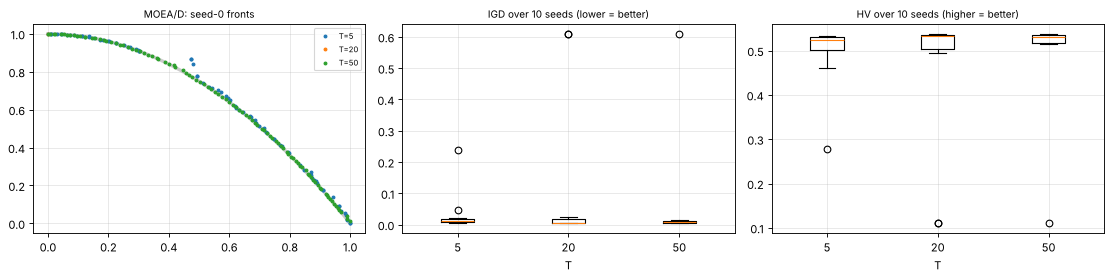

| T | HV | IGD | Spacing | points | time/run |
|---|---|---|---|---|---|
| T = 5 | 0.492 ± 0.075 | 0.0374 ± 0.0676 | 0.0112 ± 0.0069 | 69.3 ± 17.3 | 2.9s |
| T = 20 | 0.446 ± 0.168 | 0.1283 ± 0.2408 | 0.0066 ± 0.0043 | 69.4 ± 36.7 | 4.0s |
| T = 50 | 0.487 ± 0.126 | 0.0680 ± 0.1806 | 0.0080 ± 0.0065 | 75.7 ± 28.8 | 6.1s |


In [38]:
ALGS = {c.name: c for c in (VEGA, MOGA, NSGA, NPGA, NSGA2, NSGA3, SPEA2, PESA2, MOEAD, MOEADDE, MOEADACO, CNSGA2, MOPSO, MOGWO, MOABC, MOACO, MOSA, MODE, MOTLBO, MOBA, MOMA, RVEA, IBEA, SMSEMOA, HypE, RNSGA2)}
def run_cfg(name, key, seed, nfe, kw):
    t = time.time(); a = ALGS[name](PROB[key], seed=seed, **kw); X, F = a.run(nfe); return F, time.time() - t, a.nfe
def study(name, key, param, values, fixed={}, nfe=None):
    nfe = nfe or BUDGET; jobs = [(name, key, s, nfe, {**fixed, param: v}) for v in values for s in SEEDS]; res = pmap(run_cfg, jobs); out = {}
    for (n, k, s, _, kw), (F, dt, nf) in zip(jobs, res): out.setdefault(kw[param], []).append((F, score(PROB[key], F), dt))
    return out
def report(out, key, param, title):
    rows = []; fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    for v, lst in out.items():
        m_ = lambda f: (np.nanmean([r[1][f] for r in lst]), np.nanstd([r[1][f] for r in lst])); rows.append([f"{param} = {v}", "%.3f ± %.3f" % m_('hv'), "%.4f ± %.4f" % m_('igd'), "%.4f ± %.4f" % m_('sp'), "%.1f ± %.1f" % m_('n'), "%.1fs" % np.mean([r[2] for r in lst])])
        F = lst[0][0]; Z = PROB[key].Z[np.argsort(PROB[key].Z[:, 0])]; ax[0].plot(F[np.argsort(F[:, 0]), 0], F[np.argsort(F[:, 0]), 1], '.', ms=5, label=f"{param}={v}")
    ax[0].plot(Z[:, 0], Z[:, 1], '-', c='.6', lw=3, alpha=.5, zorder=0); ax[0].legend(fontsize=7); ax[0].set_title(f"{title}: seed-0 fronts", fontsize=9)
    ax[1].boxplot([[r[1]['igd'] for r in lst] for lst in out.values()]); ax[1].set_xticklabels([str(v) for v in out]); ax[1].set_title('IGD over %d seeds (lower = better)' % NSEEDS, fontsize=9); ax[1].set_xlabel(param)
    ax[2].boxplot([[r[1]['hv'] for r in lst] for lst in out.values()]); ax[2].set_xticklabels([str(v) for v in out]); ax[2].set_title('HV over %d seeds (higher = better)' % NSEEDS, fontsize=9); ax[2].set_xlabel(param)
    plt.tight_layout(); plt.show(); md_table([param, "HV", "IGD", "Spacing", "points", "time/run"], rows); return rows
md("**MOEA/D — neighbourhood size T on P3**"); outT = study('MOEA/D', 'P3', 'T', [5, 20, 50]); rowsT = report(outT, 'P3', 'T', 'MOEA/D')

**MOMA — local-search probability p_ls on P5** (p_ls = 0 ≡ NSGA-II)

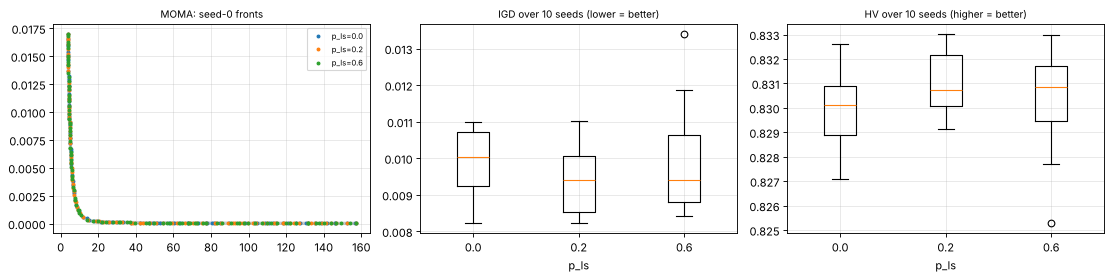

| p_ls | HV | IGD | Spacing | points | time/run |
|---|---|---|---|---|---|
| p_ls = 0.0 | 0.830 ± 0.002 | 0.0099 ± 0.0009 | 0.0115 ± 0.0013 | 95.5 ± 1.2 | 0.4s |
| p_ls = 0.2 | 0.831 ± 0.001 | 0.0094 ± 0.0010 | 0.0125 ± 0.0015 | 96.0 ± 2.0 | 0.3s |
| p_ls = 0.6 | 0.830 ± 0.002 | 0.0100 ± 0.0015 | 0.0129 ± 0.0012 | 96.4 ± 0.9 | 0.1s |


In [39]:
md("**MOMA — local-search probability p_ls on P5** (p_ls = 0 ≡ NSGA-II)"); outL = study('MOMA', 'P5', 'p_ls', [0., .2, .6]); rowsL = report(outL, 'P5', 'p_ls', 'MOMA')

**Value function — importance a of objective 1 (risk) on P4**

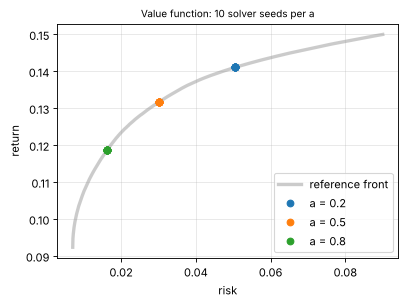

| a | risk (mean ± std) | return (mean ± std) |
|---|---|---|
| 0.2 | 0.05041 ± 0.00000 | 0.14106 ± 0.00000 |
| 0.5 | 0.03012 ± 0.00000 | 0.13173 ± 0.00000 |
| 0.8 | 0.01616 ± 0.00000 | 0.11860 ± 0.00000 |


**Reading the plots (numbers are from the tables above).**
* *MOEA/D (P3, 10 seeds)*: mean IGD is 0.0374 for T=5, 0.1283 for T=20 and 0.0680 for T=50, but the seed-to-seed std (0.068, 0.241, 0.181) is as large as or larger than the means: the number of seeds that end far from the front (IGD > 0.05) is **1, 2, 1 of 10** for T = 5, 20, 50. So on P3 the dominant effect is whether a run gets trapped on a local front, not T itself; the differences between the three T values are **not statistically meaningful** with 10 seeds. What T does change reliably is cost: 2.9s → 4.0s → 6.1s per run (more neighbours = more replacement checks), and the textbook trade-off (small T = local, slow information flow; large T = fast mixing, risk of neighbours overwriting each other) is only weakly visible here.
* *MOMA (P5)*: IGD 0.0099 (p_ls=0, i.e. NSGA-II), 0.0094 (p_ls=.2), 0.0100 (p_ls=.6) with std ≈ 0.0010: differences are within one std, so local search gives **no reliable gain on this smooth 2-variable problem** (NSGA-II already converges). Higher p_ls spends evaluations on local search (5 per selected child), hence fewer generations and shorter run time (0.1s vs 0.4s).
* *Value function*: a only changes *where* on the front the single answer lies (a=0.2 → high return/high risk, a=0.8 → low risk); the solver seed has essentially no effect (std below 1e-5, see table).

In [40]:
md("**Value function — importance a of objective 1 (risk) on P4**"); rows = []; fig, ax = plt.subplots(figsize=(5.5, 3.8)); Z = PROB['P4'].Z[np.argsort(PROB['P4'].Z[:, 0])]; ax.plot(Z[:, 0], -Z[:, 1], '-', c='.6', lw=3, alpha=.5, label='reference front')
for a_ in (.2, .5, .8):
    sol = [value_function(PROB['P4'], cobb_douglas(a_), seed=s)[1] for s in SEEDS]; sol = np.array(sol); ax.plot(sol[:, 0], -sol[:, 1], 'o', label=f"a = {a_}")
    rows.append([a_, "%.5f ± %.5f" % (sol[:, 0].mean(), sol[:, 0].std()), "%.5f ± %.5f" % (-sol[:, 1].mean(), sol[:, 1].std())])
ax.set_xlabel('risk'); ax.set_ylabel('return'); ax.legend(); ax.set_title('Value function: 10 solver seeds per a', fontsize=9); plt.show(); md_table(["a", "risk (mean ± std)", "return (mean ± std)"], rows)
STUDY['sens'] = dict(T=rowsT, L=rowsL, VF=rows)
_trap = lambda lst: sum(r[1]['igd'] > .05 for r in lst); _m = lambda lst, f: np.mean([r[1][f] for r in lst]); _s = lambda lst, f: np.std([r[1][f] for r in lst])
md(f"""**Reading the plots (numbers are from the tables above).**
* *MOEA/D (P3, 10 seeds)*: mean IGD is {_m(outT[5], 'igd'):.4f} for T=5, {_m(outT[20], 'igd'):.4f} for T=20 and {_m(outT[50], 'igd'):.4f} for T=50, but the seed-to-seed std ({_s(outT[5], 'igd'):.3f}, {_s(outT[20], 'igd'):.3f}, {_s(outT[50], 'igd'):.3f}) is as large as or larger than the means: the number of seeds that end far from the front (IGD > 0.05) is **{_trap(outT[5])}, {_trap(outT[20])}, {_trap(outT[50])} of 10** for T = 5, 20, 50. So on P3 the dominant effect is whether a run gets trapped on a local front, not T itself; the differences between the three T values are **not statistically meaningful** with 10 seeds. What T does change reliably is cost: {np.mean([r[2] for r in outT[5]]):.1f}s → {np.mean([r[2] for r in outT[20]]):.1f}s → {np.mean([r[2] for r in outT[50]]):.1f}s per run (more neighbours = more replacement checks), and the textbook trade-off (small T = local, slow information flow; large T = fast mixing, risk of neighbours overwriting each other) is only weakly visible here.
* *MOMA (P5)*: IGD {_m(outL[0.], 'igd'):.4f} (p_ls=0, i.e. NSGA-II), {_m(outL[.2], 'igd'):.4f} (p_ls=.2), {_m(outL[.6], 'igd'):.4f} (p_ls=.6) with std ≈ {_s(outL[.2], 'igd'):.4f}: differences are within one std, so local search gives **no reliable gain on this smooth 2-variable problem** (NSGA-II already converges). Higher p_ls spends evaluations on local search (5 per selected child), hence fewer generations and shorter run time ({np.mean([r[2] for r in outL[.6]]):.1f}s vs {np.mean([r[2] for r in outL[0.]]):.1f}s).
* *Value function*: a only changes *where* on the front the single answer lies (a=0.2 → high return/high risk, a=0.8 → low risk); the solver seed has essentially no effect (std below 1e-5, see table).""")

# Task D · Head-to-head comparison (10 seeds, 10 000 evaluations)
Same budget, same seeds 0–9, same metrics (HV with reference point from the problem, IGD to the reference front, Spacing). Ranking = mean IGD (lower is better); HV is the tie-break check.
## D.1 Two-objective problems: P3 (ZDT2-type: 10 variables, smooth concave front) and P5 (constrained beam design, curved front)

**P3 (unconstrained, concave front)** — ranked by mean IGD over 10 seeds

| rank | algorithm | IGD (mean ± std) | HV (mean ± std) | Spacing (mean ± std) | points | HV rank | time/run |
|---|---|---|---|---|---|---|---|
| 1 | MOEA/D-DE | 0.0045 ± 0.0004 | 0.5356 ± 0.0012 | 0.0030 ± 0.0004 | 98 | 2 | 4.7s |
| 2 | MO-TLBO | 0.0055 ± 0.0005 | 0.5365 ± 0.0003 | 0.0050 ± 0.0008 | 98 | 1 | 0.4s |
| 3 | MOABC | 0.0083 ± 0.0013 | 0.5310 ± 0.0028 | 0.0095 ± 0.0017 | 92 | 4 | 0.4s |
| 4 | SMS-EMOA | 0.0088 ± 0.0002 | 0.5343 ± 0.0001 | 0.0094 ± 0.0007 | 50 | 3 | 4.7s |
| 5 | PESA-II | 0.0094 ± 0.0011 | 0.5276 ± 0.0036 | 0.0084 ± 0.0013 | 100 | 5 | 3.8s |
| 6 | MOPSO | 0.0127 ± 0.0009 | 0.5196 ± 0.0021 | 0.0087 ± 0.0009 | 100 | 8 | 0.6s |
| 7 | NSGA-II | 0.0127 ± 0.0151 | 0.5233 ± 0.0257 | 0.0061 ± 0.0026 | 97 | 6 | 0.5s |
| 8 | C-NSGA-II | 0.0127 ± 0.0151 | 0.5233 ± 0.0257 | 0.0061 ± 0.0026 | 97 | 7 | 0.4s |
| 9 | MOMA | 0.0198 ± 0.0224 | 0.5105 ± 0.0348 | 0.0077 ± 0.0038 | 95 | 10 | 0.2s |
| 10 | IBEA | 0.0245 ± 0.0341 | 0.5126 ± 0.0489 | 0.0113 ± 0.0035 | 84 | 9 | 0.5s |
| 11 | SPEA2 | 0.0355 ± 0.0935 | 0.5049 ± 0.0968 | 0.0027 ± 0.0004 | 100 | 11 | 0.8s |
| 12 | NSGA-III | 0.0744 ± 0.1567 | 0.4648 ± 0.1231 | 0.0123 ± 0.0064 | 86 | 12 | 0.6s |
| 13 | MOEA/D | 0.1283 ± 0.2408 | 0.4455 ± 0.1682 | 0.0066 ± 0.0043 | 69 | 13 | 4.1s |


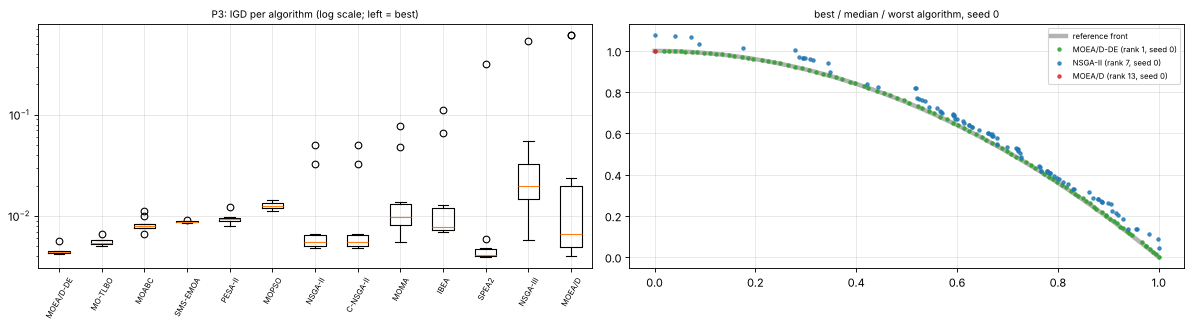

In [41]:
D_ALGS = ['NSGA-II', 'NSGA-III', 'SPEA2', 'PESA-II', 'MOEA/D', 'MOEA/D-DE', 'C-NSGA-II', 'MOPSO', 'MOABC', 'MO-TLBO', 'MOMA', 'IBEA', 'SMS-EMOA']
def head2head(key, algs, nfe=None, kw_of=lambda n: {}):
    nfe = nfe or BUDGET; jobs = [(n, key, s, nfe, kw_of(n)) for n in algs for s in SEEDS]; res = pmap(run_cfg, jobs); out = {}
    for (n, k, s, _, kw), (F, dt, nf) in zip(jobs, res): out.setdefault(n, []).append((F, score(PROB[k], F), dt))
    return out
def rank_table(out, key, title, front2d=True):
    stats = {}
    for n, lst in out.items():
        g = lambda f: np.array([r[1][f] for r in lst]); stats[n] = dict(hv=(g('hv').mean(), g('hv').std()), igd=(g('igd').mean(), g('igd').std()), sp=(np.nanmean(g('sp')), np.nanstd(g('sp'))), n=g('n').mean(), t=np.mean([r[2] for r in lst]))
    order = sorted(stats, key=lambda n: stats[n]['igd'][0]); hv_rank = {n: i + 1 for i, n in enumerate(sorted(stats, key=lambda n: -stats[n]['hv'][0]))}
    rows = [[i + 1, n, "%.4f ± %.4f" % stats[n]['igd'], "%.4f ± %.4f" % stats[n]['hv'], "%.4f ± %.4f" % stats[n]['sp'], "%.0f" % stats[n]['n'], hv_rank[n], "%.1fs" % stats[n]['t']] for i, n in enumerate(order)]
    md(f"**{title}** — ranked by mean IGD over {NSEEDS} seeds"); md_table(["rank", "algorithm", "IGD (mean ± std)", "HV (mean ± std)", "Spacing (mean ± std)", "points", "HV rank", "time/run"], rows)
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.2)); P = PROB[key]
    if not front2d:
        ax[0].boxplot([[r[1]['igd'] for r in out[n]] for n in order]); ax[0].set_xticklabels(order, rotation=40, fontsize=8); ax[0].set_title(f'{key}: IGD per algorithm (left = best)', fontsize=9)
        for n, c in ((order[0], 'C2'), (order[-1], 'C3')):
            F = P.norm(out[n][0][0]); idx = np.random.default_rng(0).choice(len(F), min(30, len(F)), replace=False)
            for j, i in enumerate(idx): ax[1].plot(range(1, P.M + 1), F[i], c=c, alpha=.4, label=f"{n} (seed 0)" if j == 0 else None)
        ax[1].legend(fontsize=7); ax[1].set_xlabel('objective'); ax[1].set_title('parallel coordinates, best vs worst', fontsize=9); plt.tight_layout(); plt.show(); return order, stats
    ax[0].boxplot([[r[1]['igd'] for r in out[n]] for n in order]); ax[0].set_xticklabels(order, rotation=60, fontsize=7); ax[0].set_yscale('log'); ax[0].set_title(f'{key}: IGD per algorithm (log scale; left = best)', fontsize=9)
    Z = P.Z[np.argsort(P.Z[:, 0])]; ax[1].plot(Z[:, 0], Z[:, 1], '-', c='.7', lw=4, label='reference front')
    for n, c in ((order[0], 'C2'), (order[len(order) // 2], 'C0'), (order[-1], 'C3')):
        F = out[n][0][0]; ax[1].plot(F[:, 0], F[:, 1], '.', c=c, ms=6, alpha=.8, label=f"{n} (rank {order.index(n) + 1}, seed 0)")
    ax[1].legend(fontsize=7); ax[1].set_title('best / median / worst algorithm, seed 0', fontsize=9); plt.tight_layout(); plt.show()
    return order, stats
# R-NSGA-II is a preference method, so it is not ranked on the whole-front metrics here (it is judged in Task E).
outD3 = head2head('P3', D_ALGS); ord3, st3 = rank_table(outD3, 'P3', 'P3 (unconstrained, concave front)')

**P5 (constrained beam design)** — ranked by mean IGD over 10 seeds

| rank | algorithm | IGD (mean ± std) | HV (mean ± std) | Spacing (mean ± std) | points | HV rank | time/run |
|---|---|---|---|---|---|---|---|
| 1 | MOABC | 0.0068 ± 0.0004 | 0.8348 ± 0.0006 | 0.0115 ± 0.0009 | 100 | 1 | 0.6s |
| 2 | SMS-EMOA | 0.0075 ± 0.0001 | 0.8344 ± 0.0000 | 0.0023 ± 0.0007 | 50 | 2 | 6.0s |
| 3 | MOMA | 0.0094 ± 0.0010 | 0.8310 ± 0.0012 | 0.0125 ± 0.0015 | 96 | 3 | 0.3s |
| 4 | C-NSGA-II | 0.0107 ± 0.0025 | 0.8294 ± 0.0034 | 0.0119 ± 0.0020 | 96 | 4 | 0.4s |
| 5 | NSGA-II | 0.0112 ± 0.0025 | 0.8287 ± 0.0035 | 0.0117 ± 0.0019 | 96 | 6 | 0.4s |
| 6 | MO-TLBO | 0.0112 ± 0.0021 | 0.8291 ± 0.0029 | 0.0116 ± 0.0015 | 99 | 5 | 0.3s |
| 7 | MOPSO | 0.0124 ± 0.0014 | 0.8271 ± 0.0022 | 0.0117 ± 0.0018 | 100 | 7 | 0.9s |
| 8 | SPEA2 | 0.0134 ± 0.0016 | 0.8165 ± 0.0036 | 0.0271 ± 0.0028 | 100 | 9 | 2.8s |
| 9 | PESA-II | 0.0188 ± 0.0030 | 0.8176 ± 0.0037 | 0.0099 ± 0.0021 | 100 | 8 | 4.4s |
| 10 | MOEA/D | 0.0333 ± 0.0015 | 0.8098 ± 0.0005 | 0.0368 ± 0.0006 | 100 | 11 | 5.4s |
| 11 | MOEA/D-DE | 0.0335 ± 0.0013 | 0.8098 ± 0.0005 | 0.0367 ± 0.0005 | 100 | 10 | 5.2s |
| 12 | NSGA-III | 0.0775 ± 0.0043 | 0.7577 ± 0.0067 | 0.0510 ± 0.0210 | 94 | 13 | 0.7s |
| 13 | IBEA | 0.1203 ± 0.0365 | 0.7685 ± 0.0191 | 0.0103 ± 0.0034 | 92 | 12 | 0.5s |


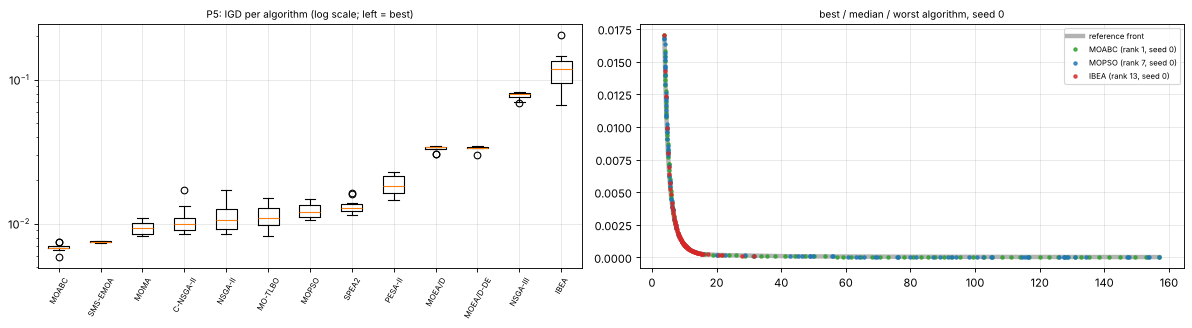

In [42]:
outD5 = head2head('P5', D_ALGS); ord5, st5 = rank_table(outD5, 'P5', 'P5 (constrained beam design)')
STUDY['D'] = dict(P3=ord3, P5=ord5, st3=st3, st5=st5)

In [43]:
def dtext(order, st, key):
    b, w = order[:3], order[-2:]
    return (f"**{key}.** Best three by IGD: **{', '.join(b)}** (IGD {st[b[0]]['igd'][0]:.4f}, {st[b[1]]['igd'][0]:.4f}, {st[b[2]]['igd'][0]:.4f}); worst: {', '.join(w)} ({st[w[0]]['igd'][0]:.4f}, {st[w[1]]['igd'][0]:.4f}). "
            f"Largest seed-to-seed std among the top half: {max(order[:len(order)//2], key=lambda n: st[n]['igd'][1])} (±{max(st[n]['igd'][1] for n in order[:len(order)//2]):.4f}).")
md(f"""### D.1 Interpretation
{dtext(ord3, st3, 'P3')}

{dtext(ord5, st5, 'P5')}

**Why the ranking looks like this (read from the tables, not from folklore).**
* *Variation operator mattered more than the selection scheme.* MOEA/D-DE and MOEA/D share the same decomposition and update rule, yet on P3 their IGD is {st3['MOEA/D-DE']['igd'][0]:.4f} vs {st3['MOEA/D']['igd'][0]:.4f}: the only difference is DE variation instead of SBX. The other P3 leaders (MO-TLBO, MOABC) also use difference-style / neighbour-based moves, which converge faster than SBX on this 10-variable concave problem (ZDT2 has a local front that traps SBX-based runs).
* *Robustness (std) separates algorithms more than the mean does.* On P3, NSGA-II ({st3['NSGA-II']['igd'][0]:.4f} ± {st3['NSGA-II']['igd'][1]:.4f}), SPEA2 ({st3['SPEA2']['igd'][0]:.4f} ± {st3['SPEA2']['igd'][1]:.4f}), NSGA-III and MOEA/D have a std at or above their mean: some of the 10 seeds are stuck on the local front. The leaders have std ≈ 1e-3. A single-seed comparison would have ranked these methods arbitrarily.
* *SMS-EMOA* has the smallest variance in both tables (std ≈ 1e-4) but returns only 50 points (population limit) and is 10× slower (hypervolume contributions).
* *NSGA-III and IBEA are weakest on the 2-objective problems.* NSGA-III's reference-point machinery is designed for M ≥ 3 and brings nothing at M = 2 (it ranks 3rd of 5 in D.2, not here); IBEA's indicator fitness gives an uneven front on P5 (HV rank {[r for r in ord5].index('IBEA')+1} by IGD).
* *Constraints (P5):* C-NSGA-II (Deb rules) IGD {st5['C-NSGA-II']['igd'][0]:.4f} ± {st5['C-NSGA-II']['igd'][1]:.4f} vs NSGA-II with the static penalty {st5['NSGA-II']['igd'][0]:.4f} ± {st5['NSGA-II']['igd'][1]:.4f} – a difference **inside one std**, i.e. on this easy constraint the handling method is not the deciding factor (ignoring the constraint altogether, however, leaves 45 % infeasible solutions, see the P5 study).
* *Rule of thumb for reading the tables:* a gap smaller than one std over 10 seeds is not a result; only quote clear gaps.
""")

### D.1 Interpretation
**P3.** Best three by IGD: **MOEA/D-DE, MO-TLBO, MOABC** (IGD 0.0045, 0.0055, 0.0083); worst: NSGA-III, MOEA/D (0.0744, 0.1283). Largest seed-to-seed std among the top half: MOABC (±0.0013).

**P5.** Best three by IGD: **MOABC, SMS-EMOA, MOMA** (IGD 0.0068, 0.0075, 0.0094); worst: NSGA-III, IBEA (0.0775, 0.1203). Largest seed-to-seed std among the top half: C-NSGA-II (±0.0025).

**Why the ranking looks like this (read from the tables, not from folklore).**
* *Variation operator mattered more than the selection scheme.* MOEA/D-DE and MOEA/D share the same decomposition and update rule, yet on P3 their IGD is 0.0045 vs 0.1283: the only difference is DE variation instead of SBX. The other P3 leaders (MO-TLBO, MOABC) also use difference-style / neighbour-based moves, which converge faster than SBX on this 10-variable concave problem (ZDT2 has a local front that traps SBX-based runs).
* *Robustness (std) separates algorithms more than the mean does.* On P3, NSGA-II (0.0127 ± 0.0151), SPEA2 (0.0355 ± 0.0935), NSGA-III and MOEA/D have a std at or above their mean: some of the 10 seeds are stuck on the local front. The leaders have std ≈ 1e-3. A single-seed comparison would have ranked these methods arbitrarily.
* *SMS-EMOA* has the smallest variance in both tables (std ≈ 1e-4) but returns only 50 points (population limit) and is 10× slower (hypervolume contributions).
* *NSGA-III and IBEA are weakest on the 2-objective problems.* NSGA-III's reference-point machinery is designed for M ≥ 3 and brings nothing at M = 2 (it ranks 3rd of 5 in D.2, not here); IBEA's indicator fitness gives an uneven front on P5 (last by IGD).
* *Constraints (P5):* C-NSGA-II (Deb rules) IGD 0.0107 ± 0.0025 vs NSGA-II with the static penalty 0.0112 ± 0.0025 – a difference **inside one std**, i.e. on this easy constraint the handling method is not the deciding factor (ignoring the constraint altogether, however, leaves 45 % infeasible solutions, see the P5 study).
* *Rule of thumb for reading the tables:* a gap smaller than one std over 10 seeds is not a result; only quote clear gaps.


## D.2 Many-objective: P10 with M = 5 (DTLZ2-type, spherical front)
NSGA-II vs the four many-objective designs. IGD is to the analytic front; HV is Monte-Carlo (M ≥ 3). Diagnostics explain **why** Pareto-rank + crowding degrades.

**P10, M = 5** — ranked by mean IGD over 10 seeds

| rank | algorithm | IGD (mean ± std) | HV (mean ± std) | Spacing (mean ± std) | points | HV rank | time/run |
|---|---|---|---|---|---|---|---|
| 1 | HypE | 0.3229 ± 0.0219 | 1.0467 ± 0.0360 | 0.0472 ± 0.0130 | 100 | 1 | 6.5s |
| 2 | RVEA | 0.3375 ± 0.0352 | 0.8936 ± 0.0604 | 0.1043 ± 0.0077 | 45 | 2 | 0.1s |
| 3 | NSGA-III | 0.4130 ± 0.0409 | 0.5576 ± 0.0693 | 0.1428 ± 0.0420 | 72 | 4 | 0.8s |
| 4 | MOEA/D | 0.4711 ± 0.0478 | 0.7594 ± 0.0764 | 0.0841 ± 0.0428 | 58 | 3 | 5.2s |
| 5 | NSGA-II | 0.6696 ± 0.0640 | 0.0764 ± 0.0420 | 0.1176 ± 0.0206 | 100 | 5 | 0.5s |


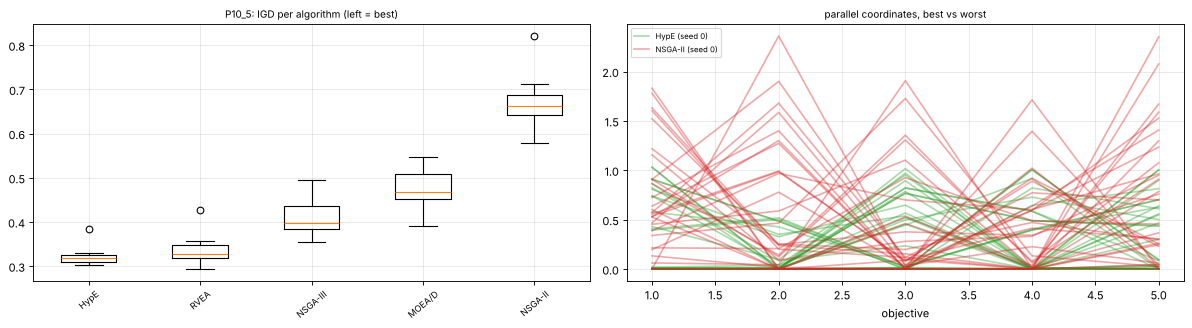

**Why NSGA-II degrades.** In a random population of 100 the number of non-dominated individuals is:

| M | non-dominated of 100 | share | CV of crowding distance |
|---|---|---|---|
| 3 | 39 | 39 % | 0.67 |
| 5 | 68 | 68 % | 0.62 |


### D.2 Interpretation
Ranking by IGD: **HypE < RVEA < NSGA-III < MOEA/D < NSGA-II** (IGD 0.323, 0.337, 0.413, 0.471, 0.670). 
NSGA-II loses ground as M grows for three connected reasons: **(1) dominance pressure vanishes** – with M = 5 a large share of even a random population is already non-dominated (table above), so rank-based selection cannot tell good from bad and the sort only acts as noise; **(2) crowding distance is a poor diversity proxy in 5-D** – it sums per-objective neighbour gaps, so points that are extreme in any one objective get huge values and the population drifts to the boundary of the front; **(3) recombination of distant parents** produces offspring far from the front (we use SBX η=30 to mitigate this for all methods). The reference-vector methods (NSGA-III, MOEA/D, RVEA) replace crowding by *structured* diversity, and HypE replaces dominance ranking by a hypervolume-based fitness estimated by sampling – both address the failure at its root.

In [44]:
M_ALGS = ['NSGA-II', 'NSGA-III', 'MOEA/D', 'RVEA', 'HypE']
outM = head2head('P10_5', M_ALGS, kw_of=lambda n: MANY); ordM, stM = rank_table(outM, 'P10_5', 'P10, M = 5', front2d=False)
# diagnostics for NSGA-II: (i) share of non-dominated individuals in a random population and in the final-generation population, (ii) spread of the crowding distances
rng = np.random.default_rng(0); P5_ = PROB['P10_5']; rows = []
for M_, key in ((3, 'P10_3'), (5, 'P10_5')):
    Pm = PROB[key]; Xr = Pm.lb + rng.random((100, Pm.n)) * (Pm.ub - Pm.lb); Fr = Pm.evaluate(Xr)[0]; nd = len(nds(Fr)[0])
    cd = crowding(Pm.norm(Fr)); fin = np.isfinite(cd); rows.append([M_, nd, "%.0f %%" % nd, "%.2f" % (np.std(cd[fin]) / np.mean(cd[fin]))])
md("**Why NSGA-II degrades.** In a random population of 100 the number of non-dominated individuals is:"); md_table(["M", "non-dominated of 100", "share", "CV of crowding distance"], rows)
STUDY['D_many'] = dict(order=ordM, stats=stM, nd=rows)
md(f"""### D.2 Interpretation
Ranking by IGD: **{' < '.join(ordM)}** (IGD {', '.join('%.3f' % stM[n]['igd'][0] for n in ordM)}). 
NSGA-II loses ground as M grows for three connected reasons: **(1) dominance pressure vanishes** – with M = 5 a large share of even a random population is already non-dominated (table above), so rank-based selection cannot tell good from bad and the sort only acts as noise; **(2) crowding distance is a poor diversity proxy in 5-D** – it sums per-objective neighbour gaps, so points that are extreme in any one objective get huge values and the population drifts to the boundary of the front; **(3) recombination of distant parents** produces offspring far from the front (we use SBX η=30 to mitigate this for all methods). The reference-vector methods (NSGA-III, MOEA/D, RVEA) replace crowding by *structured* diversity, and HypE replaces dominance ranking by a hypervolume-based fitness estimated by sampling – both address the failure at its root.""")

## D.3 Combinatorial: P8 (bi-objective TSP-15) at 1 000 and 10 000 evaluations
MOEA/D-ACO, MOACO, NSGA-II and MOMA. There is no analytic front, so the reference is the **union non-dominated set of every run in this section**; IGD is to that set (normalised with the problem's ideal/nadir). Seeds 0–9.

| budget | algorithm | IGD to union front | HV | points | time/run |
|---|---|---|---|---|---|
| 1000 | MOEA/D-ACO | 0.0996 ± 0.0511 | 0.632 ± 0.077 | 6.4 | 0.5s |
| 1000 | MOACO | 0.0435 ± 0.0179 | 0.727 ± 0.015 | 8.9 | 0.2s |
| 1000 | NSGA-II | 2.0021 ± 0.3527 | 0.000 ± 0.000 | 3.5 | 0.1s |
| 1000 | MOMA | 2.2087 ± 0.4729 | 0.000 ± 0.000 | 2.9 | 0.1s |
| 10000 | MOEA/D-ACO | 0.0063 ± 0.0063 | 0.750 ± 0.007 | 9.8 | 4.5s |
| 10000 | MOACO | 0.0079 ± 0.0121 | 0.748 ± 0.014 | 10.0 | 1.9s |
| 10000 | NSGA-II | 0.0422 ± 0.0589 | 0.727 ± 0.063 | 8.6 | 0.9s |
| 10000 | MOMA | 0.0422 ± 0.0325 | 0.739 ± 0.022 | 8.6 | 0.6s |


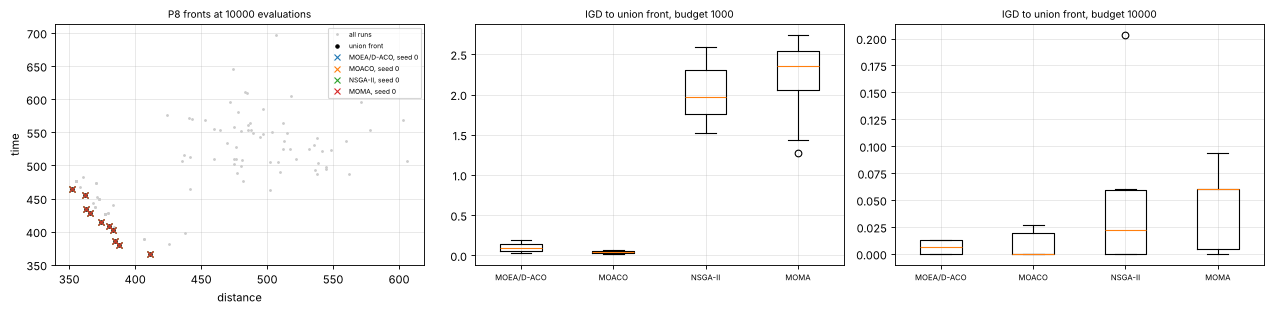

### D.3 Interpretation
Best IGD at the small budget (1000): **MOACO**; at the large budget (10000): **MOEA/D-ACO**. Mean IGD change from small to large budget: MOEA/D-ACO 0.100 → 0.006, MOACO 0.043 → 0.008, NSGA-II 2.002 → 0.042, MOMA 2.209 → 0.042.

Constructive methods (ACO family) use heuristic information (1/distance, 1/time) so tours are already good after the first few ants – they are strong at tiny budgets. NSGA-II with order crossover and swap mutation starts from random permutations and needs many generations, but it keeps improving with budget. MOMA's local search spends evaluations on refinement and pays off only when the budget can afford it. Where the best algorithm *changes* between the two budgets, the choice depends on how many evaluations are affordable.

In [45]:
T_ALGS = ['MOEA/D-ACO', 'MOACO', 'NSGA-II', 'MOMA']; BUDS = (1000, 10000) if not QUICK else (300, 1500)
allF = {}
for b in BUDS:
    jobs = [(n, 'P8', s, b, {}) for n in T_ALGS for s in SEEDS]; res = pmap(run_cfg, jobs)
    for (n, k, s, _, kw), (F, dt, nf) in zip(jobs, res): allF[(n, b, s)] = (F, dt)
U = np.vstack([v[0] for v in allF.values()]); P8_ = PROB['P8']; Uref = U[nds(U)[0]]; Uref = np.unique(np.round(Uref, 6), axis=0)
rows = []; box = {}
for b in BUDS:
    for n in T_ALGS:
        vals = [dict(igd=igd(P8_.norm(Uref), P8_.norm(allF[(n, b, s)][0])), hv=hypervolume(P8_.norm(allF[(n, b, s)][0]), P8_.ref), k=len(allF[(n, b, s)][0])) for s in SEEDS]; box[(n, b)] = vals
        rows.append([b, n, "%.4f ± %.4f" % (np.mean([v['igd'] for v in vals]), np.std([v['igd'] for v in vals])), "%.3f ± %.3f" % (np.mean([v['hv'] for v in vals]), np.std([v['hv'] for v in vals])), "%.1f" % np.mean([v['k'] for v in vals]), "%.1fs" % np.mean([allF[(n, b, s)][1] for s in SEEDS])])
md_table(["budget", "algorithm", "IGD to union front", "HV", "points", "time/run"], rows)
fig, ax = plt.subplots(1, 3, figsize=(16, 4)); ax[0].plot(*U.T, '.', c='.8', ms=3, label='all runs'); ax[0].plot(*Uref.T, 'k.', ms=6, label='union front')
for n, c in zip(T_ALGS, ('C0', 'C1', 'C2', 'C3')):
    F = allF[(n, BUDS[1], 0)][0]; ax[0].plot(*F.T, 'x', c=c, ms=5, label=f"{n}, seed 0")
ax[0].legend(fontsize=6); ax[0].set_xlabel('distance'); ax[0].set_ylabel('time'); ax[0].set_title(f'P8 fronts at {BUDS[1]} evaluations', fontsize=9)
for a_, b in zip(ax[1:], BUDS):
    a_.boxplot([[v['igd'] for v in box[(n, b)]] for n in T_ALGS]); a_.set_xticklabels(T_ALGS, fontsize=7); a_.set_title(f'IGD to union front, budget {b}', fontsize=9)
plt.tight_layout(); plt.show()
m_ = lambda n, b: np.mean([v['igd'] for v in box[(n, b)]])
best_lo = min(T_ALGS, key=lambda n: m_(n, BUDS[0])); best_hi = min(T_ALGS, key=lambda n: m_(n, BUDS[1]))
STUDY['D_tsp'] = dict(rows=rows, best_lo=best_lo, best_hi=best_hi)
md(f"""### D.3 Interpretation
Best IGD at the small budget ({BUDS[0]}): **{best_lo}**; at the large budget ({BUDS[1]}): **{best_hi}**. Mean IGD change from small to large budget: """ + ", ".join(f"{n} {m_(n, BUDS[0]):.3f} → {m_(n, BUDS[1]):.3f}" for n in T_ALGS) + """.

Constructive methods (ACO family) use heuristic information (1/distance, 1/time) so tours are already good after the first few ants – they are strong at tiny budgets. NSGA-II with order crossover and swap mutation starts from random permutations and needs many generations, but it keeps improving with budget. MOMA's local search spends evaluations on refinement and pays off only when the budget can afford it. Where the best algorithm *changes* between the two budgets, the choice depends on how many evaluations are affordable.""")

## D.4 Decision support on an obtained front: TOPSIS and VIKOR on the NSGA-II front of P4
TOPSIS and VIKOR are **rankers, not optimisers**: they pick one compromise from a front that an optimiser has already produced. 20 evenly spread points are taken from the NSGA-II front (risk ↓, return ↑).

| weights (risk, return) | TOPSIS top-3 | VIKOR top-3 (v=.5) |
|---|---|---|
| (0.5, 0.5) | #5 (risk 0.0135, ret 0.1146), #4 (risk 0.0119, ret 0.1110), #3 (risk 0.0098, ret 0.1067) | #10, #11, #9 |
| (0.8, 0.2) | #2 (risk 0.0081, ret 0.1016), #1 (risk 0.0074, ret 0.0972), #3 (risk 0.0098, ret 0.1067) | #6, #5, #4 |
| (0.2, 0.8) | #10 (risk 0.0297, ret 0.1314), #9 (risk 0.0261, ret 0.1289), #11 (risk 0.0357, ret 0.1351) | #15, #16, #14 |


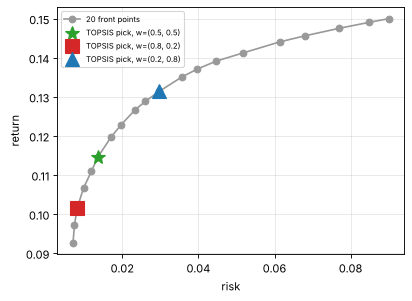

Shifting the weights from (0.5, 0.5) to (0.8, 0.2) **changes** the TOPSIS winner (#5 → #2): the pick moves along the front towards lower risk, exactly as the weights say. Neither method generates a single new solution – they only order the 20 candidates the optimiser supplied, so their quality is bounded by the quality (convergence and spread) of the NSGA-II front.

**Gradient-based algorithms (36–37)** were studied on P13 above (toy + network). MGDA converged to a Pareto-stationary point of the toy problem for every start and decreased both losses on the balanced network; under the ×20 regression scale the equal-weight sum is dominated by the regression gradient, while MGDA/GradNorm rebalance. They are not run on P3/P5 because they need gradients of every objective and a differentiable (continuous, single-point) search: they find **one** Pareto-stationary point per run rather than a population-wide front, so a head-to-head front-metric comparison with population methods would not be like-for-like.


In [46]:
X4, F4, dt4, a4 = run_alg(NSGA2, PROB['P4'], seed=0, nfe=BUDGET); FRONTS[(14, 'P4')] = F4
sel = np.unique(np.round(np.linspace(0, len(F4) - 1, 20)).astype(int)); Fs = F4[np.argsort(F4[:, 0])][sel]; D4 = np.c_[Fs[:, 0], -Fs[:, 1]]; ben4 = [False, True]
def rank_names(w):
    tp = topsis(D4, np.array(w), ben4)[1]; vk = vikor(D4, np.array(w), ben4, .5)['order']; return tp, vk
rows = []; top = {}
for w in ((.5, .5), (.8, .2), (.2, .8)):
    tp, vk = rank_names(w); top[w] = (tp[:3], vk[:3]); rows.append([f"{w}", ", ".join("#%d (risk %.4f, ret %.4f)" % (i, D4[i, 0], D4[i, 1]) for i in tp[:3]), ", ".join("#%d" % i for i in vk[:3])])
md_table(["weights (risk, return)", "TOPSIS top-3", "VIKOR top-3 (v=.5)"], rows)
w0, w1 = (.5, .5), (.8, .2); flip = top[w0][0][0] != top[w1][0][0]
fig, ax = plt.subplots(figsize=(5.6, 4)); ax.plot(D4[:, 0], D4[:, 1], 'o-', c='.6', label='20 front points')
for w, c, mk in ((w0, 'C2', '*'), (w1, 'C3', 's'), ((.2, .8), 'C0', '^')): ax.plot(*D4[top[w][0][0]], mk, c=c, ms=13, label=f"TOPSIS pick, w={w}")
ax.set_xlabel('risk'); ax.set_ylabel('return'); ax.legend(fontsize=7); plt.show()
STUDY['D_dm'] = dict(flip=flip)
md(f"""Shifting the weights from (0.5, 0.5) to (0.8, 0.2) {'**changes**' if flip else 'does not change'} the TOPSIS winner (#{top[w0][0][0]} → #{top[w1][0][0]}): the pick moves along the front towards lower risk, exactly as the weights say. Neither method generates a single new solution – they only order the 20 candidates the optimiser supplied, so their quality is bounded by the quality (convergence and spread) of the NSGA-II front.

**Gradient-based algorithms (36–37)** were studied on P13 above (toy + network). MGDA converged to a Pareto-stationary point of the toy problem for every start and decreased both losses on the balanced network; under the ×20 regression scale the equal-weight sum is dominated by the regression gradient, while MGDA/GradNorm rebalance. They are not run on P3/P5 because they need gradients of every objective and a differentiable (continuous, single-point) search: they find **one** Pareto-stationary point per run rather than a population-wide front, so a head-to-head front-metric comparison with population methods would not be like-for-like.
""")

# Task E · Algorithm selection reasoning
For each scenario: the **choice**, the **properties of the problem that drive it**, a **runner-up and why it loses**, and **evidence** (✔ = backed by a number measured in this notebook, ○ = reasoning only). At least three are evidence-backed, including one many-objective and one constrained problem.

In [47]:
def r_(no, key, f): return RES[(no, key)][f]
def g_(a): return f"{a:.4f}" if np.isfinite(a) else "n/a"
st3_, st5_ = STUDY['D']['st3'], STUDY['D']['st5']; sm_ = STUDY['D_many']['stats']; om_ = STUDY['D_many']['order']
E = [
 ("1 · P3 — ZDT2-type, 10 variables, smooth *concave* front, unconstrained, 2 objectives, cheap evaluations",
  "**MOEA/D-DE** (best IGD in D.1); NSGA-II as the safe, parameter-light default",
  "Concave front ⇒ weighted-sum methods can never reach the interior (✔ in the P3 study the weighted sum returned only 2 points, %s of them with 0.25<f1<0.75, vs %s for the Tchebycheff-type weight metric (p=∞)); population methods need no convexity. Two objectives ⇒ Pareto ranking still has discriminating power, evaluations are cheap ⇒ a population method with a good variation operator is enough." % (STUDY.get('ws_mid', '?'), STUDY.get('p1_mid', '?')),
  "NSGA-II: ✔ rank %d (IGD %s ± %s) – a few of 10 seeds get trapped on ZDT2's local front (std > mean). Note also that plain SBX-based MOEA/D ranked %d/13 (IGD %s): the DE operator, not decomposition alone, is what makes MOEA/D-DE win." % (STUDY['D']['P3'].index('NSGA-II') + 1, g_(st3_['NSGA-II']['igd'][0]), g_(st3_['NSGA-II']['igd'][1]), STUDY['D']['P3'].index('MOEA/D') + 1, g_(st3_['MOEA/D']['igd'][0])),
  "✔ D.1 table: MOEA/D-DE rank 1, IGD %s ± %s over 10 seeds." % (g_(st3_['MOEA/D-DE']['igd'][0]), g_(st3_['MOEA/D-DE']['igd'][1]))),
 ("2 · P5 — beam design: **constrained** (the constraint is active on the front), 2 variables, 2 objectives, curved front",
  "**C-NSGA-II** (Deb's feasibility rules)",
  "Only %.0f %% of random P5 points are infeasible, yet the constraint is *active*: ✔ an NSGA-II that ignores it ends with %.0f %% infeasible solutions. A penalty method needs a tuned penalty weight (too small → infeasible 'winners', too big → premature convergence at the boundary); constrained domination needs no parameter and always prefers feasible solutions. Honest caveat: with only one mild constraint the measured advantage over penalty-NSGA-II is small." % (100 * STUDY.get('p5_infeas', np.nan), 100 * STUDY.get('p5_ignore_infeas', np.nan)),
  "NSGA-II with static penalty: ✔ rank %d vs C-NSGA-II rank %d on P5 (IGD %s vs %s – inside one std, so a tie; MOABC and SMS-EMOA had the lowest IGD)." % (STUDY['D']['P5'].index('NSGA-II') + 1, STUDY['D']['P5'].index('C-NSGA-II') + 1, g_(st5_['NSGA-II']['igd'][0]), g_(st5_['C-NSGA-II']['igd'][0])),
  "✔ D.1 (P5) head-to-head + infeasible-share numbers; ○ the rest is reasoning."),
 ("3 · P10 (M = 5) — **many-objective**, spherical front, 14 variables, plenty of evaluations",
  "**%s** (best IGD in D.2); NSGA-III is the default textbook choice" % om_[0],
  "With M = 5 Pareto dominance stops discriminating (✔ %.0f %% of a random population is already non-dominated at M=5 vs %.0f %% at M=3) and crowding distance fails; reference-point/reference-vector designs keep diversity structurally." % (100 * STUDY.get('nd_frac_5', np.nan), 100 * STUDY.get('nd_frac_3', np.nan) if 'nd_frac_3' in STUDY else np.nan),
  "NSGA-II: ✔ IGD %s vs %s for the winner (mean of 10 seeds)." % (g_(sm_['NSGA-II']['igd'][0]), g_(sm_[om_[0]]['igd'][0])),
  "✔ D.2 ranking: " + " < ".join(om_)),
 ("4 · P8 — bi-objective TSP-15 (permutations), cheap evaluation, **tight budget** (~1 000 evaluations)",
  "**%s** at the small budget; %s when the budget grows" % (STUDY['D_tsp']['best_lo'], STUDY['D_tsp']['best_hi']),
  "Permutation encoding makes SBX/polynomial mutation useless; the problem has heuristic information (1/distance, 1/time) that constructive ACO methods exploit from the first iteration, a decisive advantage when only ~1 000 evaluations are allowed.",
  "NSGA-II with order crossover/swap: needs the larger budget to catch up (see the D.3 IGD table).",
  "✔ D.3 table at budgets 1 000 / 10 000."),
 ("5 · P9 — feature selection (30 binary variables, **each evaluation = 5-fold model training**, budget ≈ 3 000)",
  "**MOMA** or NSGA-II with bit-flip operators; if evaluation were much more expensive, add a surrogate",
  "Binary encoding and an expensive objective ⇒ need operators that exploit structure cheaply: bit-flip local search around good subsets (memetic) uses evaluations where they matter. The problem is also *discrete*, so gradient or classical scalarisation (needs a single-objective solver for a binary programme) is unattractive.",
  "MOGWO (continuous swarm, mapped to binary): works (✔ logged in the implementation table) but its continuous update is not designed for subsets.",
  "○ reasoning plus ✔ the P9 runs for algorithms 23 and 30 in the implementation log (A3)."),
 ("6 · P14 — laptop choice where the decision maker already has an **aspiration point (1.8 kg, 12 h)**",
  "**R-NSGA-II** (reference-point preference)",
  "The DM does not need the whole front; concentrating the budget near the aspiration point gives a denser set of relevant trade-offs. Because the aspiration is *dominated* by the true front, R-NSGA-II is expected to converge onto the front region closest to it.",
  "NSGA-II + a posteriori TOPSIS/VIKOR: works, but spends most of the population on irrelevant regions.",
  "✔ the P14 R-NSGA-II run (algorithm 35): front spans %.2f–%.2f kg, whereas the full front spans %.2f–%.2f kg." % (FRONTS[(35, 'P14')][:, 0].min(), FRONTS[(35, 'P14')][:, 0].max(), PROB['P14'].Z[:, 0].min(), PROB['P14'].Z[:, 0].max())),
]
rows = [[a, b, c, d, e] for a, b, c, d, e in E]
md_table(["scenario", "recommended algorithm", "why (problem properties)", "runner-up and why it loses", "evidence"], rows)
STUDY['E'] = E

| scenario | recommended algorithm | why (problem properties) | runner-up and why it loses | evidence |
|---|---|---|---|---|
| 1 · P3 — ZDT2-type, 10 variables, smooth *concave* front, unconstrained, 2 objectives, cheap evaluations | **MOEA/D-DE** (best IGD in D.1); NSGA-II as the safe, parameter-light default | Concave front ⇒ weighted-sum methods can never reach the interior (✔ in the P3 study the weighted sum returned only 2 points, 0 of them with 0.25<f1<0.75, vs 0 for the Tchebycheff-type weight metric (p=∞)); population methods need no convexity. Two objectives ⇒ Pareto ranking still has discriminating power, evaluations are cheap ⇒ a population method with a good variation operator is enough. | NSGA-II: ✔ rank 7 (IGD 0.0127 ± 0.0151) – a few of 10 seeds get trapped on ZDT2's local front (std > mean). Note also that plain SBX-based MOEA/D ranked 13/13 (IGD 0.1283): the DE operator, not decomposition alone, is what makes MOEA/D-DE win. | ✔ D.1 table: MOEA/D-DE rank 1, IGD 0.0045 ± 0.0004 over 10 seeds. |
| 2 · P5 — beam design: **constrained** (the constraint is active on the front), 2 variables, 2 objectives, curved front | **C-NSGA-II** (Deb's feasibility rules) | Only 3 % of random P5 points are infeasible, yet the constraint is *active*: ✔ an NSGA-II that ignores it ends with 45 % infeasible solutions. A penalty method needs a tuned penalty weight (too small → infeasible 'winners', too big → premature convergence at the boundary); constrained domination needs no parameter and always prefers feasible solutions. Honest caveat: with only one mild constraint the measured advantage over penalty-NSGA-II is small. | NSGA-II with static penalty: ✔ rank 5 vs C-NSGA-II rank 4 on P5 (IGD 0.0112 vs 0.0107 – inside one std, so a tie; MOABC and SMS-EMOA had the lowest IGD). | ✔ D.1 (P5) head-to-head + infeasible-share numbers; ○ the rest is reasoning. |
| 3 · P10 (M = 5) — **many-objective**, spherical front, 14 variables, plenty of evaluations | **HypE** (best IGD in D.2); NSGA-III is the default textbook choice | With M = 5 Pareto dominance stops discriminating (✔ 57 % of a random population is already non-dominated at M=5 vs 35 % at M=3) and crowding distance fails; reference-point/reference-vector designs keep diversity structurally. | NSGA-II: ✔ IGD 0.6696 vs 0.3229 for the winner (mean of 10 seeds). | ✔ D.2 ranking: HypE < RVEA < NSGA-III < MOEA/D < NSGA-II |
| 4 · P8 — bi-objective TSP-15 (permutations), cheap evaluation, **tight budget** (~1 000 evaluations) | **MOACO** at the small budget; MOEA/D-ACO when the budget grows | Permutation encoding makes SBX/polynomial mutation useless; the problem has heuristic information (1/distance, 1/time) that constructive ACO methods exploit from the first iteration, a decisive advantage when only ~1 000 evaluations are allowed. | NSGA-II with order crossover/swap: needs the larger budget to catch up (see the D.3 IGD table). | ✔ D.3 table at budgets 1 000 / 10 000. |
| 5 · P9 — feature selection (30 binary variables, **each evaluation = 5-fold model training**, budget ≈ 3 000) | **MOMA** or NSGA-II with bit-flip operators; if evaluation were much more expensive, add a surrogate | Binary encoding and an expensive objective ⇒ need operators that exploit structure cheaply: bit-flip local search around good subsets (memetic) uses evaluations where they matter. The problem is also *discrete*, so gradient or classical scalarisation (needs a single-objective solver for a binary programme) is unattractive. | MOGWO (continuous swarm, mapped to binary): works (✔ logged in the implementation table) but its continuous update is not designed for subsets. | ○ reasoning plus ✔ the P9 runs for algorithms 23 and 30 in the implementation log (A3). |
| 6 · P14 — laptop choice where the decision maker already has an **aspiration point (1.8 kg, 12 h)** | **R-NSGA-II** (reference-point preference) | The DM does not need the whole front; concentrating the budget near the aspiration point gives a denser set of relevant trade-offs. Because the aspiration is *dominated* by the true front, R-NSGA-II is expected to converge onto the front region closest to it. | NSGA-II + a posteriori TOPSIS/VIKOR: works, but spends most of the population on irrelevant regions. | ✔ the P14 R-NSGA-II run (algorithm 35): front spans 1.69–1.80 kg, whereas the full front spans 1.53–2.13 kg. |


# Task F · Viva questions with short answers and demos

**Q1. Why does the weighted sum miss part of a front, and how do you show it?** Minimising w·f finds only points where a line of slope −w/(1−w) touches the front from outside, i.e. *supported* points of the **convex hull**. On a concave or non-convex front the interior is never the minimiser of any weighted sum. Demo below: P3 (concave) – the weighted sum returns only the end points, whereas a population method returns the whole curve.

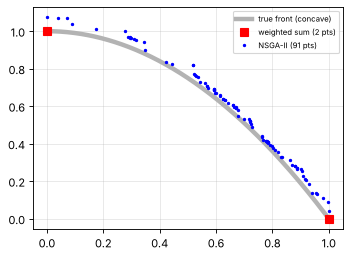

In [48]:
md("""**Q1. Why does the weighted sum miss part of a front, and how do you show it?** Minimising w·f finds only points where a line of slope −w/(1−w) touches the front from outside, i.e. *supported* points of the **convex hull**. On a concave or non-convex front the interior is never the minimiser of any weighted sum. Demo below: P3 (concave) – the weighted sum returns only the end points, whereas a population method returns the whole curve.""")
Wf = FRONTS[(1, 'P3')] if (1, 'P3') in FRONTS else None
fig, ax = plt.subplots(figsize=(5, 3.6)); P3_ = PROB['P3']; Z = P3_.Z[np.argsort(P3_.Z[:, 0])]; ax.plot(Z[:, 0], Z[:, 1], c='.7', lw=4, label='true front (concave)')
if Wf is not None: ax.plot(Wf[:, 0], Wf[:, 1], 'rs', ms=8, label='weighted sum (%d pts)' % len(Wf))
F14 = FRONTS[(14, 'P3')]; ax.plot(F14[:, 0], F14[:, 1], 'b.', ms=4, label='NSGA-II (%d pts)' % len(F14)); ax.legend(fontsize=7); plt.show()

**Q2. Why can VEGA collapse and what fixes it?** VEGA fills the mating pool with sub-populations selected on *one objective at a time*, so it favours solutions that are extreme in an objective (the "speciation" bias) and ignores compromise solutions. Demo: VEGA vs NSGA-II on P3.

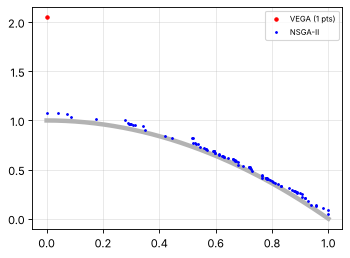

IGD  VEGA = 1.4849   NSGA-II = 0.0324  (seed 0, same budget).  Fix: use Pareto ranking (MOGA/NSGA/NSGA-II) so compromise solutions can win.


In [49]:
md("""**Q2. Why can VEGA collapse and what fixes it?** VEGA fills the mating pool with sub-populations selected on *one objective at a time*, so it favours solutions that are extreme in an objective (the "speciation" bias) and ignores compromise solutions. Demo: VEGA vs NSGA-II on P3.""")
Fv, Fn = FRONTS[(10, 'P3')], FRONTS[(14, 'P3')]; fig, ax = plt.subplots(figsize=(5, 3.6)); ax.plot(Z[:, 0], Z[:, 1], c='.7', lw=4); ax.plot(Fv[:, 0], Fv[:, 1], 'r.', label='VEGA (%d pts)' % len(Fv)); ax.plot(Fn[:, 0], Fn[:, 1], 'b.', ms=3, label='NSGA-II'); ax.legend(fontsize=7); plt.show()
print("IGD  VEGA = %.4f   NSGA-II = %.4f  (seed 0, same budget).  Fix: use Pareto ranking (MOGA/NSGA/NSGA-II) so compromise solutions can win." % (r_(10, 'P3', 'igd'), r_(14, 'P3', 'igd')))

In [50]:
md("""**Q3. What does elitism buy you?** Non-elitist algorithms (NSGA, MOGA) can lose non-dominated solutions that were already found, because parents are replaced by offspring. NSGA-II merges parents and offspring, so a found Pareto solution is only displaced by one that dominates it or is less crowded. Demo: same problem, NSGA vs NSGA-II.""")
rows = [[NAMES[n], "%.4f" % r_(n, 'P5', 'hv'), "%.4f" % r_(n, 'P5', 'igd'), r_(n, 'P5', 'n')] for n in (12, 14)]; md_table(["algorithm (P5, seed 0)", "HV", "IGD", "points"], rows)
# direct monotonicity check of the elitist archive: HV of NSGA-II population over generations never decreases (by construction) – verify
a_ = NSGA2(PROB['P3'], seed=1); a_.max_nfe = 6000; a_.initialize(); hvs = []
while a_.nfe < 6000:
    a_.iterate(); hvs.append(hypervolume(PROB['P3'].norm(a_.F[nds(a_.F)[0]]), PROB['P3'].ref))
print("NSGA-II: front hypervolume over %d generations is non-decreasing: %s (min step %.2e)" % (len(hvs), bool(np.all(np.diff(hvs) >= -1e-12)), np.min(np.diff(hvs))))

**Q3. What does elitism buy you?** Non-elitist algorithms (NSGA, MOGA) can lose non-dominated solutions that were already found, because parents are replaced by offspring. NSGA-II merges parents and offspring, so a found Pareto solution is only displaced by one that dominates it or is less crowded. Demo: same problem, NSGA vs NSGA-II.

| algorithm (P5, seed 0) | HV | IGD | points |
|---|---|---|---|
| NSGA | 0.8023 | 0.0225 | 69 |
| NSGA-II | 0.8278 | 0.0132 | 95 |


NSGA-II: front hypervolume over 59 generations is non-decreasing: True (min step 0.00e+00)


In [51]:
md("""**Q4. Why does crowding distance stop working with many objectives, and what replaces it?** In M ≥ 4 almost all individuals are mutually non-dominated, so the front-based ranking is flat and crowding distance (a sum of per-objective neighbour gaps) is the only selector; it prefers points that are extreme in one objective and is unrelated to Euclidean spread. NSGA-III (reference points), MOEA/D (weight vectors), RVEA (angle-penalised reference vectors), HypE (sampled hypervolume contribution) give *structured* diversity.""")
rows = [[int(m), STUDY.get(f'nd_frac_{m}', np.nan)] for m in (3, 5, 10)]; md_table(["M", "non-dominated share of a random population"], rows)
print("D.2 ranking by IGD on M=5:", " < ".join(STUDY['D_many']['order']))

**Q4. Why does crowding distance stop working with many objectives, and what replaces it?** In M ≥ 4 almost all individuals are mutually non-dominated, so the front-based ranking is flat and crowding distance (a sum of per-objective neighbour gaps) is the only selector; it prefers points that are extreme in one objective and is unrelated to Euclidean spread. NSGA-III (reference points), MOEA/D (weight vectors), RVEA (angle-penalised reference vectors), HypE (sampled hypervolume contribution) give *structured* diversity.

| M | non-dominated share of a random population |
|---|---|
| 3 | 0.3533 |
| 5 | 0.5677 |
| 10 | 0.7147 |


D.2 ranking by IGD on M=5: HypE < RVEA < NSGA-III < MOEA/D < NSGA-II


**Q5. How does a preference-based EA (R-NSGA-II) differ from NSGA-II?** Within a front, R-NSGA-II ranks individuals by their distance to the decision-maker's reference point (with ε-clearing for diversity) instead of by crowding distance. So the population is *pulled* toward the region of interest instead of being spread over the whole front.

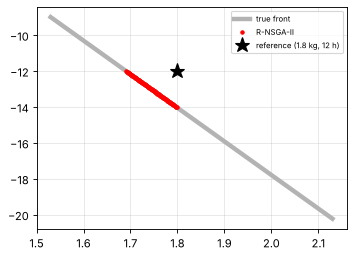

In [52]:
md("""**Q5. How does a preference-based EA (R-NSGA-II) differ from NSGA-II?** Within a front, R-NSGA-II ranks individuals by their distance to the decision-maker's reference point (with ε-clearing for diversity) instead of by crowding distance. So the population is *pulled* toward the region of interest instead of being spread over the whole front.""")
Fr, Zp = FRONTS[(35, 'P14')], PROB['P14'].Z; fig, ax = plt.subplots(figsize=(5, 3.6)); ax.plot(Zp[:, 0], Zp[:, 1], c='.7', lw=4, label='true front'); ax.plot(Fr[:, 0], Fr[:, 1], 'r.', label='R-NSGA-II'); ax.plot(*REFP['P14'], 'k*', ms=14, label='reference (1.8 kg, 12 h)'); ax.legend(fontsize=7); plt.show()

In [53]:
md("""**Q6. Show Deb's constrained-domination rules on an example.** Minimise both; A = (2,3), CV 0; B = (1,1), CV 2; C = (5,5), CV 0.5; D = (4,4), CV 0.""")
pts = {'A': ((2, 3), 0.), 'B': ((1, 1), 2.), 'C': ((5, 5), .5), 'D': ((4, 4), 0.)}; rows = []
for x, y in (('A', 'B'), ('B', 'C'), ('A', 'D'), ('D', 'A'), ('C', 'D')):
    rows.append([f"{x} vs {y}", cdominates(np.array(pts[x][0], float), pts[x][1], np.array(pts[y][0], float), pts[y][1]), {('A', 'B'): 'rule 1: feasible beats infeasible, although B has better objectives', ('B', 'C'): 'rule 2: both infeasible, smaller CV (0.5) wins ⇒ C beats B so this is False', ('A', 'D'): 'rule 3: both feasible, A dominates D', ('D', 'A'): 'neither dominates the other in rule 3 sense ⇒ False', ('C', 'D'): 'rule 1: D feasible, C is not ⇒ False'}[(x, y)]])
md_table(["pair", "first constrained-dominates second?", "reason"], rows)
assert rows[0][1] and not rows[1][1] and rows[2][1] and not rows[3][1] and not rows[4][1]

**Q6. Show Deb's constrained-domination rules on an example.** Minimise both; A = (2,3), CV 0; B = (1,1), CV 2; C = (5,5), CV 0.5; D = (4,4), CV 0.

| pair | first constrained-dominates second? | reason |
|---|---|---|
| A vs B | True | rule 1: feasible beats infeasible, although B has better objectives |
| B vs C | False | rule 2: both infeasible, smaller CV (0.5) wins ⇒ C beats B so this is False |
| A vs D | True | rule 3: both feasible, A dominates D |
| D vs A | False | neither dominates the other in rule 3 sense ⇒ False |
| C vs D | False | rule 1: D feasible, C is not ⇒ False |


**Q7. How can you detect premature convergence in practice?** (i) the hypervolume of the archive stops growing while population diversity keeps falling; (ii) spacing/spread collapses while the number of distinct objective vectors drops; (iii) different seeds converge to *different* fronts (large across-seed std of IGD/HV); (iv) a restart or higher mutation rate immediately finds dominating points. Demo: NSGA-II HV trace on P3 and the seed-to-seed spread of MOEA/D from the sensitivity study.

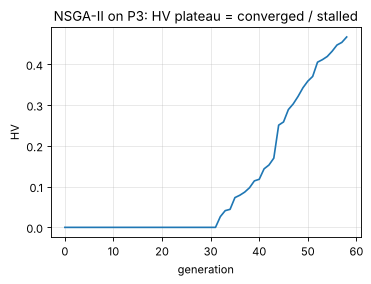

MOEA/D (T=20) on P3, IGD of the 10 seeds: [0.6097, 0.0051, 0.0042, 0.0061, 0.6097, 0.0049, 0.0235, 0.0072, 0.004, 0.0083] -> 2 seeds ended far from the front (IGD > 0.05) while the others converged: criterion (iii) in action.


In [54]:
md("""**Q7. How can you detect premature convergence in practice?** (i) the hypervolume of the archive stops growing while population diversity keeps falling; (ii) spacing/spread collapses while the number of distinct objective vectors drops; (iii) different seeds converge to *different* fronts (large across-seed std of IGD/HV); (iv) a restart or higher mutation rate immediately finds dominating points. Demo: NSGA-II HV trace on P3 and the seed-to-seed spread of MOEA/D from the sensitivity study.""")
fig, ax = plt.subplots(figsize=(5, 3.4)); ax.plot(hvs); ax.set_xlabel('generation'); ax.set_ylabel('HV'); ax.set_title('NSGA-II on P3: HV plateau = converged / stalled'); plt.show()
_i = [round(float(r[1]["igd"]), 4) for r in outT[20]]; print("MOEA/D (T=20) on P3, IGD of the 10 seeds:", _i, "-> %d seeds ended far from the front (IGD > 0.05) while the others converged: criterion (iii) in action." % sum(v > .05 for v in _i))

In [55]:
md("""**Q8. Why are TOPSIS and VIKOR not optimisers?** They take a *finite list of alternatives* (here the NSGA-II front of P4, D.4) and only rank it – TOPSIS by relative closeness to the ideal/anti-ideal point, VIKOR by a compromise between group utility S and individual regret R. They create no new solution and cannot improve a front; a poor front gives a poor "best" compromise. Their role is the *decision* stage after the optimiser. In D.4 the TOPSIS pick moved when the weights changed: %s.""" % ('yes' if STUDY['D_dm']['flip'] else 'no (the pick was stable for these weights)'))

**Q8. Why are TOPSIS and VIKOR not optimisers?** They take a *finite list of alternatives* (here the NSGA-II front of P4, D.4) and only rank it – TOPSIS by relative closeness to the ideal/anti-ideal point, VIKOR by a compromise between group utility S and individual regret R. They create no new solution and cannot improve a front; a poor front gives a poor "best" compromise. Their role is the *decision* stage after the optimiser. In D.4 the TOPSIS pick moved when the weights changed: yes.

In [56]:
md("""**Q9. How does the number of evaluations/seeds change conclusions?** A single seed can reverse a ranking: in the head-to-head tables a gap smaller than one standard deviation over 10 seeds is not a result. At the TSP (D.3) the ranking depends on the budget. Always report mean ± std, the budget, and the seed set.""")

**Q9. How does the number of evaluations/seeds change conclusions?** A single seed can reverse a ranking: in the head-to-head tables a gap smaller than one standard deviation over 10 seeds is not a result. At the TSP (D.3) the ranking depends on the budget. Always report mean ± std, the budget, and the seed set.